# Part 3 — Multi-trace forecasting ensemble with Fused vs Reactive DQN agents (SO / MO, decision lead 3), 4-fold trace-level cross-validation

**Fresh run.** Nothing from earlier runs is reused: all artifacts go to a new folder named by `RUN_TAG` (setup cell), so cached CV scores, forecaster fits, RL checkpoints and flag files cannot leak in. Every RL agent is trained from scratch: 4 folds x 10 seeds x {Reactive, Fused, Reactive-8, shuffled-forecast} x {SO, MO} = 320 agents.

1. **Setup and screening** — load the 5G traces, clean them, keep traces with zero DL <= 5% (eligible, 20 traces).
2. **Forecasting** — per-trace min-max fitted on the development portion only; inner CV selects the top-4 ensemble; multi-horizon forecasts are exported with a persistence benchmark.
3. **Lead-time RL testbed, 4-fold trace-level cross-validation** — the 20 eligible traces are split once (balanced on trace characteristics, not on any result) into 4 folds of 5. In each fold the agents train on the other 15 traces and are tested on the 5 held-out traces, so **every eligible trace is tested exactly once, by agents that never saw it**. Action effects are state-dependent and take effect `ACTION_LAG` = 3 steps after the decision.
4. **Held-out confirmation** — frozen forecaster and all 40 frozen agents per regime (4 folds x 10 seeds) on screened-out traces never used before.
5. **Summary**.

**Declared before the run (not tuned afterwards).**
- Primary comparison: **Fused vs Reactive-8** (same 8-input shape; last observed DL in the forecast slot), pooled over the 20 cross-validated traces, 95% interval resampling traces and seeds together. **SUPPORTED** only if the interval is above zero in both SO and MO; otherwise **SUGGESTIVE** (point estimate positive) or **NOT SUPPORTED**. Fused vs Reactive, Fused vs shuffled-forecast and the per-fold breakdown (how many of the 4 folds favour Fused) are reported alongside.
- Folds, lead, environment and seeds are fixed here and are not changed after any test fold has been evaluated (per-fold flag files warn on re-evaluation).
- Whatever the outcome — Fused ahead, level, or behind — is what is reported. The run is a protocol, not a search for a configuration in which Fused wins.


## 1. Setup, trace loading and eligibility screening

In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"]="TRUE"
os.environ["OMP_NUM_THREADS"]="2"
os.environ["OPENBLAS_NUM_THREADS"]="2"
os.environ["MKL_NUM_THREADS"]="2"
os.environ["VECLIB_MAXIMUM_THREADS"]="2"
os.environ["NUMEXPR_NUM_THREADS"]="2"

import faulthandler; faulthandler.enable()
import re, json, time, copy, random, warnings, gc, joblib
from pathlib import Path
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import numpy as np, pandas as pd
import lightgbm as lgb
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from scipy.stats import pearsonr

warnings.filterwarnings("ignore")
SEED=42
np.random.seed(SEED); random.seed(SEED); torch.manual_seed(SEED)
DEVICE=torch.device("cpu")
torch.set_num_threads(2)
LGB_THREADS=1
SEQ_MODELS={"Block RNN","Transformer"}

DATA_FOLDER=Path("5G-production-dataset")
# ---- FRESH RUN -------------------------------------------------------------------------------
# Every artifact of this notebook (CV scores, final models, forecast bundle, RL split, RL checkpoints, flag files,
# confirmation outputs) lives under OUT. A new RUN_TAG means nothing from any earlier run can be reused.
# After a kernel restart in the MIDDLE of a run, keep the same RUN_TAG to resume; to start over, change it.
RUN_TAG="part3_cv4_run1"
OUT=Path(f"{RUN_TAG}_artifacts"); OUT.mkdir(exist_ok=True)
_prior=[p.name for p in OUT.iterdir()]
print(f"Run tag: {RUN_TAG} | output folder: {OUT.resolve()} | " + ("EMPTY: every step runs from scratch" if not _prior else f"NOT EMPTY ({len(_prior)} items): cached steps of THIS tag will be resumed; change RUN_TAG for a fresh start"))
HORIZON=10; TRAIN_FRAC=.80; N_LAGS=5; SEQ_LEN=10
COVARIATES=["RSRP","RSRQ","SNR","CQI","RSSI","Speed"]; TARGET="DL_Mbps"
CV_FOLDS=[(.50,.60),(.60,.70),(.70,.80)]
CANDIDATES=["LightGBM","Random Forest","Linear Regression","Block RNN","Transformer"]

def parse_ts(x): return pd.to_datetime(x,format="%Y.%m.%d_%H.%M.%S",errors="coerce")

def load_all(root):
    out=[]
    for folder,_,files in os.walk(root):
        if Path(folder)==root: continue
        rel=Path(folder).relative_to(root).parts
        prefix="_".join(rel[:3]) if rel else "trace"
        for f in sorted(x for x in files if x.endswith(".csv")):
            df=pd.read_csv(Path(folder)/f)
            if len(df): out.append((f"{prefix}_{Path(f).stem}",df))
    return out

def clean(df):
    x=df.copy()
    if "Timestamp" in x:
        x["Timestamp"]=x["Timestamp"].map(parse_ts)
        x=x.dropna(subset=["Timestamp"]).sort_values("Timestamp").drop_duplicates("Timestamp")
    if "DL_bitrate" in x: x[TARGET]=pd.to_numeric(x["DL_bitrate"],errors="coerce")/1000.
    if any(c not in x for c in [TARGET]+COVARIATES): return None
    for c in [TARGET]+COVARIATES:
        x[c]=pd.to_numeric(x[c],errors="coerce").interpolate(limit_direction="both").ffill().bfill().fillna(0)
    return x.reset_index(drop=True)

all_traces=[]
for tid,df in load_all(DATA_FOLDER):
    x=clean(df)
    if x is not None and len(x)>N_LAGS+HORIZON+20:
        z=float((x[TARGET].to_numpy()==0).mean())
        all_traces.append({"id":tid,"df":x,"zero_frac":z})

screen=pd.DataFrame([{"trace_id":t["id"],"rows":len(t["df"]),"zero_frac":t["zero_frac"],
                      "eligible":t["zero_frac"]<=.05} for t in all_traces])
screen.to_csv(OUT/"trace_screening.csv",index=False)
traces=[t for t in all_traces if t["zero_frac"]<=.05]

print("Total cleaned traces:",len(all_traces))
print("Eligible traces (zero DL <= 5%):",len(traces))
print("Excluded traces:",len(all_traces)-len(traces))
display(screen[screen.eligible].sort_values("zero_frac"))

Run tag: part3_cv4_run1 | output folder: part3_cv4_run1_artifacts | EMPTY: every step runs from scratch
Total cleaned traces: 83
Eligible traces (zero DL <= 5%): 20
Excluded traces: 63


,trace_id,rows,zero_frac,eligible
69,Download_Driving_B_2019.12.16_11.49.59,342,0.011696,True
66,Download_Static_B_2020.02.27_18.39.27,5568,0.017241,True
78,Download_Driving_B_2020.02.14_07.29.00,1912,0.018828,True
64,Download_Static_B_2020.02.13_13.57.29,2920,0.018836,True
82,Download_Driving_B_2020.02.27_20.35.57,734,0.019074,True
79,Download_Driving_B_2020.02.14_09.38.22,1453,0.022023,True
63,Download_Static_B_2020.01.16_10.43.34,3080,0.023052,True
74,Download_Driving_B_2020.01.16_09.56.56,1536,0.023438,True
81,Download_Driving_B_2020.02.27_17.30.15,752,0.027926,True
77,Download_Driving_B_2020.02.13_15.02.01,3186,0.029190,True


In [2]:
def fit_mm(df):
    return {c:(float(df[c].min()),float(df[c].max())) for c in [TARGET]+COVARIATES}

def transform(df,p):
    z=df.copy()
    for c,(lo,hi) in p.items():
        z[c]=0. if hi<=lo else (z[c].astype(float)-lo)/(hi-lo)
    return z

def inv(y,p):
    lo,hi=p[TARGET]; return np.asarray(y,dtype=np.float32)*(hi-lo)+lo

def windows(z,origins):
    y=z[TARGET].to_numpy(np.float32); cov=z[COVARIATES].to_numpy(np.float32)
    X=[]; Y=[]
    for i in origins:
        X.append([y[i-k] for k in range(1,N_LAGS+1)]+[y[max(0,i-5):i].mean()]+list(cov[i]))
        Y.append(y[i:i+HORIZON])
    return np.asarray(X,np.float32),np.asarray(Y,np.float32)

def final_data(t):
    df=t["df"]; split=int(len(df)*TRAIN_FRAC)
    p=fit_mm(df.iloc[:split]); z=transform(df,p)
    Xtr,Ytr=windows(z,range(N_LAGS,split-HORIZON+1))
    Xte,Yte=windows(z,range(split,len(df)-HORIZON+1))
    return {"id":t["id"],"df":df,"split":split,"p":p,"Xtr":Xtr,"Ytr":Ytr,
            "Xte":Xte,"Yte":Yte,"origins":np.arange(split,len(df)-HORIZON+1)}

def fold_data(t,a,b):
    df=t["df"]; dev=int(len(df)*TRAIN_FRAC); tr=int(dev*a); ve=int(dev*b)
    if tr<=N_LAGS+HORIZON or ve-tr<HORIZON: return None
    p=fit_mm(df.iloc[:tr]); z=transform(df,p)
    Xtr,Ytr=windows(z,range(N_LAGS,tr-HORIZON+1))
    Xv,Yv=windows(z,range(tr,ve-HORIZON+1))
    return None if len(Xtr)<20 or len(Xv)<3 else (Xtr,Ytr,Xv,Yv,p)

data=[final_data(t) for t in traces]
print("Prepared eligible traces:",len(data))

Prepared eligible traces: 20


## 2. Forecasting ensemble, holdout evaluation and export

In [3]:
class SeqDS(Dataset):
    def __init__(self,X,y,s=SEQ_LEN): self.X,self.y,self.s=X,y,s
    def __len__(self): return max(0,len(self.X)-self.s+1)
    def __getitem__(self,i):
        return torch.from_numpy(self.X[i:i+self.s]),torch.from_numpy(self.y[i+self.s-1])

class BlockRNN(nn.Module):
    def __init__(self,d):
        super().__init__(); self.r=nn.LSTM(d,32,batch_first=True)
        self.f=nn.Sequential(nn.Linear(32,16),nn.ReLU(),nn.Dropout(.3),nn.Linear(16,HORIZON),nn.Sigmoid())
    def forward(self,x): o,_=self.r(x); return self.f(o[:,-1])

class Transformer(nn.Module):
    def __init__(self,d):
        super().__init__(); self.p=nn.Linear(d,32)
        e=nn.TransformerEncoderLayer(32,2,64,.3,batch_first=True)
        self.e=nn.TransformerEncoder(e,1,enable_nested_tensor=False)
        self.f=nn.Sequential(nn.Linear(32,16),nn.ReLU(),nn.Dropout(.3),nn.Linear(16,HORIZON),nn.Sigmoid())
    def forward(self,x): return self.f(self.e(self.p(x))[:,-1])

class HorizonLGBM:
    def __init__(self):
        self.models=[]
    def fit(self,X,Y):
        self.models=[]
        for h in range(Y.shape[1]):
            m=lgb.LGBMRegressor(n_estimators=1000,learning_rate=.02,max_depth=15,num_leaves=31,
                subsample=.8,colsample_bytree=.8,min_child_samples=10,random_state=SEED,n_jobs=LGB_THREADS,verbose=-1)
            m.fit(X,Y[:,h]); self.models.append(m)
        return self
    def predict(self,X): return np.column_stack([m.predict(X) for m in self.models]).astype(np.float32)

def make_model(name,d):
    if name=="LightGBM": return HorizonLGBM()
    if name=="Random Forest": return RandomForestRegressor(n_estimators=300,max_depth=15,min_samples_leaf=3,n_jobs=2,random_state=SEED)
    if name=="Linear Regression": return LinearRegression()
    if name=="Block RNN": return BlockRNN(d)
    return Transformer(d)

def fit_model(name,m,X,Y,epochs=20):
    if name not in {"Block RNN","Transformer"}:
        m.fit(X,Y); return m
    loader=DataLoader(SeqDS(X,Y),batch_size=256,shuffle=True,num_workers=0)
    opt=torch.optim.Adam(m.parameters(),lr=5e-4,weight_decay=1e-4)
    sch=torch.optim.lr_scheduler.StepLR(opt,5,.7)
    best=np.inf; state=None
    for _ in range(epochs):
        m.train(); total=0.
        for xb,yb in loader:
            opt.zero_grad(); loss=nn.functional.mse_loss(m(xb),yb); loss.backward(); opt.step(); total+=loss.item()
        sch.step()
        if total/max(1,len(loader))<best: best=total/max(1,len(loader)); state=copy.deepcopy(m.state_dict())
    m.load_state_dict(state); return m

def predict(name,m,X):
    if name not in {"Block RNN","Transformer"}: return np.asarray(m.predict(X),np.float32),0
    if len(X)<SEQ_LEN:return None,None
    m.eval(); out=[]
    with torch.no_grad():
        for start in range(0,len(X)-SEQ_LEN+1,512):
            ids=range(start,min(start+512,len(X)-SEQ_LEN+1))
            xb=np.stack([X[i:i+SEQ_LEN] for i in ids])
            out.append(m(torch.from_numpy(xb)).numpy())
    return np.vstack(out).astype(np.float32),SEQ_LEN-1

In [4]:
SIG=json.dumps({"h":HORIZON,"lags":N_LAGS,"seq":SEQ_LEN,"frac":TRAIN_FRAC,"folds":CV_FOLDS,"seed":SEED,
                "traces":[t["id"] for t in traces]},sort_keys=True)
CACHE=OUT/"cv_cache.json"
cache=json.load(open(CACHE)) if CACHE.exists() else {}
if cache.get("sig")!=SIG: cache={"sig":SIG,"scores":{}}

fold_parts={}
for fi,(a,b) in enumerate(CV_FOLDS,1):
    parts=[fold_data(t,a,b) for t in traces]; parts=[p for p in parts if p is not None]
    X=np.vstack([p[0] for p in parts]).astype(np.float32)
    Y=np.vstack([p[1] for p in parts]).astype(np.float32)
    sc=StandardScaler().fit(X); Xs=sc.transform(X).astype(np.float32)
    fold_parts[fi]=(parts,sc,Xs,Y)
    print(f"Fold {fi}: train={len(X):,}, validation traces={len(parts)}")
    del X

cv={m:[] for m in CANDIDATES}
cv_order=[n for n in CANDIDATES if n not in SEQ_MODELS]+[n for n in CANDIDATES if n in SEQ_MODELS]
for name in cv_order:
    for fi,(parts,sc,Xs,Y) in fold_parts.items():
        key=f"{name}|{fi}"
        if key in cache["scores"]:
            cv[name].extend(cache["scores"][key]); print(f"  fold {fi} {name}: resumed from cache",flush=True); continue
        t0=time.time(); print(f"  fold {fi} {name} ...",flush=True)
        np.random.seed(SEED); torch.manual_seed(SEED)
        m=fit_model(name,make_model(name,Xs.shape[1]),Xs,Y)
        scores=[]
        for _,_,Xv,Yv,p in parts:
            pr,off=predict(name,m,sc.transform(Xv).astype(np.float32))
            if pr is None: continue
            yy=Yv[off:off+len(pr)]; n=min(len(yy),len(pr))
            scores.append(float(np.sqrt(mean_squared_error(inv(yy[:n],p).ravel(),inv(pr[:n],p).ravel()))))
        cv[name].extend(scores)
        cache["scores"][key]=scores; json.dump(cache,open(CACHE,"w"))
        print(f"   median RMSE={np.median(scores):.4f} Mbps | {time.time()-t0:.1f}s",flush=True)
        del m; gc.collect()
del fold_parts; gc.collect()

cv_table=pd.DataFrame([{"model":m,"cv_rmse_median":float(np.median(cv[m])),
                        "cv_rmse_mean":float(np.mean(cv[m])),"n":len(cv[m])} for m in CANDIDATES])
cv_table=cv_table.sort_values("cv_rmse_median").reset_index(drop=True)
top4=cv_table.head(4).model.tolist()
w=1/cv_table.head(4).cv_rmse_median.to_numpy(); weights=w/w.sum()
cv_table.to_csv(OUT/"cv_model_selection.csv",index=False)
print("\nSelected:",list(zip(top4,np.round(weights,4))))
display(cv_table)


Fold 1: train=14,368, validation traces=20
Fold 2: train=17,293, validation traces=20
Fold 3: train=20,223, validation traces=20
  fold 1 LightGBM ...
   median RMSE=30.8449 Mbps | 5.7s
  fold 2 LightGBM ...
   median RMSE=26.9957 Mbps | 6.1s
  fold 3 LightGBM ...
   median RMSE=42.6599 Mbps | 6.6s
  fold 1 Random Forest ...
   median RMSE=28.4404 Mbps | 9.3s
  fold 2 Random Forest ...
   median RMSE=26.4744 Mbps | 11.1s
  fold 3 Random Forest ...
   median RMSE=41.3142 Mbps | 13.3s
  fold 1 Linear Regression ...
   median RMSE=31.0080 Mbps | 0.0s
  fold 2 Linear Regression ...
   median RMSE=29.4177 Mbps | 0.0s
  fold 3 Linear Regression ...
   median RMSE=45.2778 Mbps | 0.0s
  fold 1 Block RNN ...
   median RMSE=29.1705 Mbps | 3.3s
  fold 2 Block RNN ...
   median RMSE=26.2882 Mbps | 3.1s
  fold 3 Block RNN ...
   median RMSE=45.4091 Mbps | 3.6s
  fold 1 Transformer ...
   median RMSE=27.1649 Mbps | 4.9s
  fold 2 Transformer ...
   median RMSE=26.0554 Mbps | 5.9s
  fold 3 Transformer

,model,cv_rmse_median,cv_rmse_mean,n
0,Transformer,30.176193,39.127283,60
1,Block RNN,30.925566,40.449677,60
2,Random Forest,31.802619,38.258473,60
3,LightGBM,32.235877,39.003208,60
4,Linear Regression,33.972397,40.714775,60


In [5]:
X=np.vstack([d["Xtr"] for d in data]).astype(np.float32)
Y=np.vstack([d["Ytr"] for d in data]).astype(np.float32)
scaler=StandardScaler().fit(X); Xs=scaler.transform(X).astype(np.float32)
joblib.dump(scaler,OUT/"feature_scaler.joblib")

FSIG={"traces":[t["id"] for t in traces],"top4":top4,"weights":[round(float(w),8) for w in weights],"h":HORIZON,"lags":N_LAGS,
      "seq":SEQ_LEN,"frac":TRAIN_FRAC,"seed":SEED,"rows":int(len(X))}
FFILE=OUT/"final_models_sig.json"
reuse=FFILE.exists() and json.load(open(FFILE))==json.loads(json.dumps(FSIG))

models={}
for name in sorted(top4,key=lambda n:n in SEQ_MODELS):
    safe=name.lower().replace(" ","_"); path=OUT/(f"{safe}.pt" if name in SEQ_MODELS else f"{safe}.joblib")
    if reuse and path.exists():
        if name in SEQ_MODELS:
            m=make_model(name,Xs.shape[1]); m.load_state_dict(torch.load(path)); m.eval()
        else: m=joblib.load(path)
        print("Final model loaded from disk:",name,flush=True)
    else:
        print("Final training:",name,flush=True)
        np.random.seed(SEED); torch.manual_seed(SEED)
        m=fit_model(name,make_model(name,Xs.shape[1]),Xs,Y)
        if name in SEQ_MODELS: torch.save(m.state_dict(),path)
        else: joblib.dump(m,path)
    models[name]=m; gc.collect()
json.dump(FSIG,open(FFILE,"w"))
print("Final models ready.")

Final training: Random Forest
Final training: LightGBM
Final training: Transformer
Final training: Block RNN
Final models ready.


In [6]:
rows=[]; outputs={}
for d in data:
    Xt=scaler.transform(d["Xte"]).astype(np.float32)
    pp=[]; oo=[]; ww=[]
    for name,wt in zip(top4,weights):
        p,off=predict(name,models[name],Xt); pp.append(p); oo.append(off); ww.append(wt)
    common=max(oo); aligned=[p[common-o:] for p,o in zip(pp,oo)]
    n=min([len(x) for x in aligned]+[len(d["Yte"])-common])
    W=np.asarray(ww); W=W/W.sum()
    ens=np.tensordot(W,np.stack([x[:n] for x in aligned]),axes=(0,0)).astype(np.float32)
    y=d["Yte"][common:common+n]
    yt,yp=inv(y,d["p"]),inv(ens,d["p"])
    a,f=yt[:,0],yp[:,0]
    r=pearsonr(a,f)[0] if len(a)>2 and np.std(a)>0 and np.std(f)>0 else np.nan
    rows.append({"trace_id":d["id"],"n_holdout":len(a),
                 "rmse_mbps":np.sqrt(mean_squared_error(yt.ravel(),yp.ravel())),
                 "mae_mbps":mean_absolute_error(yt.ravel(),yp.ravel()),"pearson_r_h1":r})
    last=d["Xte"][common:common+n,0]
    outputs[d["id"]]={"y":y,"p":ens,"actual":yt,"forecast":yp,"off":common,"last":last}

results=pd.DataFrame(rows).sort_values("rmse_mbps")
results.to_csv(OUT/"holdout_forecast_results.csv",index=False)
display(results)
print(results[["rmse_mbps","mae_mbps","pearson_r_h1"]].describe())

# Forecast skill by horizon against naive persistence (last observed DL repeated), pooled per trace then averaged
hz=[]
for h in range(HORIZON):
    er=[];pr=[];ea=[];pa=[]
    for d in data:
        o=outputs[d["id"]]; a=o["actual"][:,h]; f=o["forecast"][:,h]; p=inv(o["last"],d["p"])
        er.append(np.sqrt(np.mean((a-f)**2))); pr.append(np.sqrt(np.mean((a-p)**2)))
        ea.append(np.mean(np.abs(a-f))); pa.append(np.mean(np.abs(a-p)))
    hz.append({"horizon":h+1,"ensemble_rmse":np.mean(er),"persistence_rmse":np.mean(pr),"rmse_skill":1-np.mean(er)/np.mean(pr),
               "ensemble_mae":np.mean(ea),"persistence_mae":np.mean(pa),"mae_skill":1-np.mean(ea)/np.mean(pa),
               "traces_ensemble_better_rmse":int(np.sum(np.array(er)<np.array(pr)))})
horizon_skill=pd.DataFrame(hz).set_index("horizon"); horizon_skill.to_csv(OUT/"horizon_skill_vs_persistence.csv")
print("\nForecast skill vs naive persistence by horizon (positive skill = ensemble better; mean over traces, Mbps):")
display(horizon_skill.round(3))


,trace_id,n_holdout,rmse_mbps,mae_mbps,pearson_r_h1
18,Download_Driving_B_2020.02.27_17.30.15,133,1.785862,1.351623,0.618285
17,Download_Driving_B_2020.02.14_12.58.17,151,2.306733,1.767681,0.727063
5,Download_Driving_B_2019.12.14_10.16.30,185,2.874421,2.484398,0.828578
10,Download_Driving_B_2020.01.16_07.26.43,334,3.935449,2.921311,0.667850
19,Download_Driving_B_2020.02.27_20.35.57,129,4.888774,4.582025,0.745767
13,Download_Driving_B_2020.02.13_13.03.24,428,5.045759,4.127178,0.754149
7,Download_Driving_B_2019.12.16_11.49.59,51,5.388434,4.595965,0.724292
14,Download_Driving_B_2020.02.13_15.02.01,620,5.577763,5.007221,0.728892
6,Download_Driving_B_2019.12.16_07.22.43,439,17.364494,10.190092,0.786905
15,Download_Driving_B_2020.02.14_07.29.00,365,23.137483,14.717468,0.858886


       rmse_mbps   mae_mbps  pearson_r_h1
count  20.000000  20.000000     20.000000
mean   35.413123  25.085007      0.787935
std    31.266612  23.626072      0.078279
min     1.785862   1.351623      0.618285
25%     5.006513   4.468313      0.739129
50%    29.396125  17.698570      0.775488
75%    64.522010  42.101400      0.859331
max    85.091455  68.378876      0.901947

Forecast skill vs naive persistence by horizon (positive skill = ensemble better; mean over traces, Mbps):


,ensemble_rmse,persistence_rmse,rmse_skill,ensemble_mae,persistence_mae,mae_skill,traces_ensemble_better_rmse
horizon,,,,,,,
1,24.211000,25.211000,0.040,15.874000,13.326000,-0.191,13
2,31.047001,37.105000,0.163,21.066999,21.355000,0.013,16
3,33.757000,43.026001,0.215,23.926001,26.254999,0.089,16
4,35.055000,46.206001,0.241,25.183001,29.252001,0.139,16
5,35.970001,48.181999,0.253,26.037001,31.283001,0.168,16
6,36.841000,49.678001,0.258,26.629000,32.823002,0.189,16
7,37.722000,51.216000,0.263,27.299000,34.220001,0.202,16
8,38.372002,52.146999,0.264,27.923000,35.122002,0.205,16
9,38.925999,52.063999,0.252,28.319000,34.993000,0.191,16


In [7]:
bundle={}; manifest=[]; audit=[]
for d in data:
    o=outputs[d["id"]]; off=o["off"]; n=len(o["actual"])
    origins=d["origins"][off:off+n]; key=re.sub(r"[^A-Za-z0-9_]+","_",d["id"])
    bundle[f"{key}__trace_id"]=np.array(d["id"])
    bundle[f"{key}__actual_norm"]=o["y"][:,0]
    bundle[f"{key}__forecast_norm"]=o["p"][:,0]
    bundle[f"{key}__actual_mbps"]=o["actual"][:,0]
    bundle[f"{key}__forecast_mbps"]=o["forecast"][:,0]
    bundle[f"{key}__actual_h_norm"]=o["y"].astype(np.float32)
    bundle[f"{key}__forecast_h_norm"]=o["p"].astype(np.float32)
    bundle[f"{key}__last_obs_norm"]=o["last"].astype(np.float32)
    bundle[f"{key}__covariates_raw"]=d["df"].iloc[origins][COVARIATES].to_numpy(np.float32)
    bundle[f"{key}__origin_index"]=origins
    manifest.append({"key":key,"trace_id":d["id"],"n":n,
                     "zero_frac":float((d["df"][TARGET].to_numpy()==0).mean())})
    row={"trace_id":d["id"],"split_row":d["split"]}
    for c in [TARGET]+COVARIATES:
        lo,hi=d["p"][c]; hold=d["df"].iloc[d["split"]:][c].to_numpy(float)
        z=np.zeros_like(hold) if hi<=lo else (hold-lo)/(hi-lo)
        row[f"{c}_dev_min"]=lo; row[f"{c}_dev_max"]=hi
        row[f"{c}_holdout_below0"]=int((z<0).sum()); row[f"{c}_holdout_above1"]=int((z>1).sum())
    audit.append(row)

np.savez_compressed(OUT/"multitrace_bundle.npz",**bundle)
pd.DataFrame(manifest).to_csv(OUT/"bundle_manifest.csv",index=False)
pd.DataFrame(audit).to_csv(OUT/"normalization_audit.csv",index=False)
meta={"seed":SEED,"train_fraction":TRAIN_FRAC,"horizon":HORIZON,"n_lags":N_LAGS,"seq_len":SEQ_LEN,
      "eligible_zero_dl_max":.05,"selected_models":top4,"ensemble_weights":[float(x) for x in weights],
      "normalization":"split first; per-trace min-max fit on development only; CV refits within fold training",
      "holdout_clipping":False}
json.dump(meta,open(OUT/"metadata.json","w"),indent=2)
print("Saved:",OUT/"multitrace_bundle.npz")
print("Eligible traces exported:",len(manifest))
print("Artifacts:",OUT.resolve())

Saved: part3_cv4_run1_artifacts/multitrace_bundle.npz
Eligible traces exported: 20
Artifacts: part3_cv4_run1_artifacts


In [8]:
print("V5.3 COMPLETE")
print("Selected models:",top4)
print("Weights:",np.round(weights,4).tolist())
print("Eligible traces:",len(data))
print("Mean holdout RMSE:",round(float(results.rmse_mbps.mean()),4),"Mbps")
print("Median holdout RMSE:",round(float(results.rmse_mbps.median()),4),"Mbps")
print("Mean Pearson r:",round(float(results.pearson_r_h1.mean()),4))

V5.3 COMPLETE
Selected models: ['Transformer', 'Block RNN', 'Random Forest', 'LightGBM']
Weights: [0.259, 0.2527, 0.2458, 0.2425]
Eligible traces: 20
Mean holdout RMSE: 35.4131 Mbps
Median holdout RMSE: 29.3961 Mbps
Mean Pearson r: 0.7879


## 3. Lead-time RL testbed (SO/MO x Reactive/Fused), 4-fold trace-level cross-validation

A forecast can only improve control if it tells the agent something the last observation does not. This section models an action that takes effect **after a delay**, as real reconfigurations (power, MCS, beamforming, load balancing) do:

- **Decision at step i, effect at step i + ACTION_LAG.** The action acts on the true DL at the landing step. Effect conditions (covariates) are those at the decision step; only the DL level is taken at landing.
- **Reactive** observes the six covariates at i and the last observed DL. **Fused** also observes the ensemble forecast, made at i, of the DL at i + ACTION_LAG.
- **Reactive-8** has the same 8-input shape as Fused, with the last observed DL in the forecast slot, so it carries exactly Reactive's information. Fused vs Reactive-8 isolates forecast information from the input-shape effect.
- **Shuffled-forecast** control: Fused fed the forecasts of a random permutation of the steps.
- Identical reward for all agents, discount factor 0, DQN (128-128, lr 1e-3, batch 128, replay 50000, target sync 250), 1000 episodes x 50 steps.

**Cross-validation.** The 20 eligible traces are partitioned once into 4 balanced folds of 5. For each fold, agents train on the other 15 traces and are evaluated on the fold's 5 traces. Pooling the folds gives test results for all 20 traces instead of 5, and the per-fold table shows whether the result depends on one particular split.

**Decision rule (fixed before the run).** The headline comparison is Fused vs Reactive-8 with a 95% interval that resamples traces and seeds together, in both SO and MO; SUPPORTED only if both intervals are above zero. The lead is set from the control latency being modelled, not from the best-looking row of the diagnostics. A null result is a result.

Checkpoints and results go to `<RUN_TAG>_artifacts/leadtime_testbed/fold<k>/` and are resumed only if the same `RUN_TAG` is rerun.


In [9]:
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK","TRUE")
for _k in ("OMP_NUM_THREADS","OPENBLAS_NUM_THREADS","MKL_NUM_THREADS","VECLIB_MAXIMUM_THREADS"):
    os.environ.setdefault(_k,"2")
import json, time, copy, gc, hashlib
from pathlib import Path
import numpy as np, pandas as pd

BUNDLE=OUT/"multitrace_bundle.npz"   # OUT is defined in the setup cell (fresh RUN_TAG folder)
RL_OUT=OUT/"leadtime_testbed"; RL_OUT.mkdir(parents=True,exist_ok=True)
COVARIATES=["RSRP","RSRQ","SNR","CQI","RSSI","Speed"]

RL_SEEDS=list(range(42,52))   # ten seeds, all trained in this run
EPISODES=1000; STEPS=50; EVAL_EVERY=100
GAMMA=0.0   # replay transitions do not depend on the action, so discounting only adds noise; set 0.99 to match V4.3
RUN_SHUFFLED_CONTROL=True
RUN_REACTIVE_DUP_CONTROL=True   # Reactive agent with the same 8-input shape as Fused: last DL in the forecast slot
N_FOLDS=4; FOLD_SEED=42   # trace-level cross-validation: every eligible trace is tested once, by agents that never saw it
STATE_CLIP=(-1.0,3.0)
ACTION_LAG=3   # steps between the decision and the moment the action takes effect (0 = acts on the step being forecast)

rl_manifest=pd.read_csv(OUT/"bundle_manifest.csv")
rl_audit=pd.read_csv(OUT/"normalization_audit.csv").set_index("trace_id")
rl_bundle=np.load(BUNDLE)

need=[f"{rl_manifest.key.iloc[0]}__forecast_h_norm",f"{rl_manifest.key.iloc[0]}__last_obs_norm"]
missing=[n for n in need if n not in rl_bundle.files]
if missing: raise KeyError("Bundle lacks multi-horizon forecasts. Rerun the V5.3 holdout and export cells (they now save forecast_h_norm and last_obs_norm).")
assert 0<=ACTION_LAG<=rl_bundle[need[0]].shape[1]-1, "ACTION_LAG must be an available forecast horizon index (0..9)"

REC={}
for _,r in rl_manifest.iterrows():
    k,tid=r["key"],r["trace_id"]; a=rl_audit.loc[tid]
    cov_raw=rl_bundle[f"{k}__covariates_raw"].astype(np.float64); cov=np.zeros_like(cov_raw); rngs=np.ones(len(COVARIATES))
    for j,c in enumerate(COVARIATES):
        lo,hi=a[f"{c}_dev_min"],a[f"{c}_dev_max"]
        if hi>lo: cov[:,j]=(cov_raw[:,j]-lo)/(hi-lo); rngs[j]=hi-lo
    REC[tid]=dict(y=rl_bundle[f"{k}__actual_norm"].astype(np.float64),forecast=rl_bundle[f"{k}__forecast_norm"].astype(np.float64),
                  fh=rl_bundle[f"{k}__forecast_h_norm"].astype(np.float64),last=rl_bundle[f"{k}__last_obs_norm"].astype(np.float64),
                  cov=cov,cov_raw=cov_raw,cov_rng=rngs,y_mbps=rl_bundle[f"{k}__actual_mbps"].astype(np.float64),
                  lo=float(a["DL_Mbps_dev_min"]),hi=float(a["DL_Mbps_dev_max"]),zero_frac=float(r["zero_frac"]),
                  mobility="Static" if "Static" in tid else "Driving")
    assert len(REC[tid]["y"])==len(REC[tid]["forecast"])==len(cov)==len(REC[tid]["fh"])>=50,tid
n_al=np.array([len(r["y"]) for r in REC.values()])
print(f"Traces loaded: {len(REC)} | aligned steps: min {n_al.min()}, median {int(np.median(n_al))}, max {n_al.max()} | "
      f"static {sum(r['mobility']=='Static' for r in REC.values())}, driving {sum(r['mobility']=='Driving' for r in REC.values())}")

Traces loaded: 20 | aligned steps: min 50, median 312, max 1096 | static 5, driving 15


In [10]:
def characteristics(tid,t):
    ym=t["y_mbps"]; m=float(ym.mean())
    return {"trace_id":tid,"steps":len(ym),"mean_dl_mbps":m,"cv_dl":float(ym.std()/(m+1e-9)),
            "volatility":float(np.abs(np.diff(ym)).mean()/(m+1e-9)),
            "rsrp":float(t["cov_raw"][:,0].mean()),"snr":float(t["cov_raw"][:,2].mean()),
            "cqi":float(t["cov_raw"][:,3].mean()),"speed":float(t["cov_raw"][:,5].mean()),
            "static":float(t["mobility"]=="Static"),"zero_frac":t["zero_frac"]}

CH=pd.DataFrame([characteristics(i,t) for i,t in REC.items()]).set_index("trace_id")
BAL=pd.DataFrame({"log_mean_dl":np.log1p(CH.mean_dl_mbps),"cv_dl":CH.cv_dl,"volatility":CH.volatility,
                  "rsrp":CH.rsrp,"snr":CH.snr,"cqi":CH.cqi,"speed":CH.speed,"static":CH.static,
                  "log_steps":np.log(CH.steps),"zero_frac":CH.zero_frac})

def balanced_folds(B,seed,k,n_iter=60_000,chunk=10_000):
    """Partition traces into k equal folds so that fold means/spreads of the trace characteristics are as similar as possible.
    Uses trace characteristics only (no RL or forecast results)."""
    X=B.to_numpy(float); sd=X.std(0); Z=(X-X.mean(0))/np.where(sd>1e-12,sd,1.)
    n=len(Z); m=n//k; rng=np.random.default_rng(seed); best=(np.inf,None); rand=[]
    for _ in range(n_iter//chunk):
        P=np.argsort(rng.random((chunk,n)),axis=1); Zp=Z[P]; obj=np.zeros(chunk)
        for f in range(k):
            g=Zp[:,f*m:(f+1)*m,:]; obj+=(g.mean(1)**2).sum(1)+0.5*((g.std(1)-1.)**2).sum(1)
        rand.append(float(np.median(obj))); j=int(obj.argmin())
        if obj[j]<best[0]: best=(float(obj[j]),P[j].copy())
    P=best[1]
    return [P[f*m:(f+1)*m] for f in range(k)],best[0],float(np.median(rand))

ids=list(REC.keys())
assert len(ids)%N_FOLDS==0,f"{len(ids)} eligible traces cannot be split into {N_FOLDS} equal folds"
FOLD_FILE=RL_OUT/f"rl_trace_folds_{N_FOLDS}.csv"
if FOLD_FILE.exists() and set(pd.read_csv(FOLD_FILE).trace_id)==set(ids):
    _f=pd.read_csv(FOLD_FILE); groups_=[_f[_f.fold==k].trace_id.tolist() for k in range(N_FOLDS)]
    print("Folds loaded from",FOLD_FILE)
else:
    _g,best,med=balanced_folds(BAL.loc[ids],FOLD_SEED,N_FOLDS)
    groups_=[[ids[i] for i in g] for g in _g]
    print(f"Balance score (lower is better): selected {best:.2f} vs median random partition {med:.2f}")
FOLDS=[{"fold":k,"test":groups_[k],"train":[t for j in range(N_FOLDS) if j!=k for t in groups_[j]]} for k in range(N_FOLDS)]
FOLD_OF={t:k for k in range(N_FOLDS) for t in FOLDS[k]["test"]}
ALL_TEST=[t for f in FOLDS for t in f["test"]]
assert sorted(ALL_TEST)==sorted(ids) and len(set(ALL_TEST))==len(ALL_TEST)
for f in FOLDS: assert not set(f["train"])&set(f["test"]) and len(f["train"])+len(f["test"])==len(ids)
pd.DataFrame([{"trace_id":t,"fold":FOLD_OF[t]} for t in ALL_TEST]).to_csv(FOLD_FILE,index=False)

tab=CH.assign(fold=pd.Series(FOLD_OF))
summary=tab.groupby("fold")[["steps","mean_dl_mbps","cv_dl","volatility","rsrp","snr","cqi","speed","static","zero_frac"]].mean()
summary.insert(0,"n_test_traces",tab.groupby("fold").size())
fr=OUT/"holdout_forecast_results.csv"
if fr.exists():
    summary["forecast_rmse_mbps (descriptive)"]=pd.read_csv(fr).assign(fold=lambda d:d.trace_id.map(FOLD_OF)).groupby("fold").rmse_mbps.mean()
print("Test-fold characteristics (each fold's 5 traces; the agents for that fold train on the other 15):")
display(summary.round(3))
for f in FOLDS: print(f"fold {f['fold']}: test {f['test']}")
SPLIT={"train":FOLDS[0]["train"],"val":[],"test":FOLDS[0]["test"]}   # placeholder, overwritten fold by fold in the training loop


Balance score (lower is better): selected 2.38 vs median random partition 8.00
Test-fold characteristics (each fold's 5 traces; the agents for that fold train on the other 15):


,n_test_traces,steps,mean_dl_mbps,cv_dl,volatility,rsrp,snr,cqi,speed,static,zero_frac,forecast_rmse_mbps (descriptive)
fold,,,,,,,,,,,,
0,5,330.4,36.883,1.074,0.333,-79.867,2.725,11.076,28.329,0.2,0.030,36.338
1,5,311.8,39.606,1.052,0.346,-79.805,2.144,8.724,27.833,0.2,0.031,39.732
2,5,465.0,50.858,1.172,0.344,-83.464,2.078,10.123,21.439,0.4,0.031,40.850
3,5,288.2,30.886,0.944,0.366,-83.898,4.115,9.226,22.580,0.2,0.033,24.733


fold 0: test ['Download_Driving_B_2020.02.14_12.58.17', 'Download_Driving_B_2020.02.14_09.38.22', 'Download_Driving_B_2020.02.27_20.35.57', 'Download_Static_B_2020.01.16_10.43.34', 'Download_Driving_B_2019.12.16_14.23.32']
fold 1: test ['Download_Driving_B_2020.02.13_15.02.01', 'Download_Driving_B_2019.12.16_12.27.05', 'Download_Driving_B_2020.01.16_09.56.56', 'Download_Driving_B_2019.12.16_11.49.59', 'Download_Static_B_2019.12.16_13.40.04']
fold 2: test ['Download_Driving_B_2020.01.16_12.10.03', 'Download_Static_B_2020.02.27_18.39.27', 'Download_Driving_B_2020.02.13_13.03.24', 'Download_Static_B_2020.02.13_13.57.29', 'Download_Driving_B_2019.12.14_10.16.30']
fold 3: test ['Download_Driving_B_2020.02.14_07.29.00', 'Download_Driving_B_2020.02.27_17.30.15', 'Download_Driving_B_2020.01.16_07.26.43', 'Download_Static_B_2020.02.14_13.21.26', 'Download_Driving_B_2019.12.16_07.22.43']


In [11]:
# ---------------------------------------------------------------------------
# State-dependent simulation testbed.
# The decision at step i is taken with information up to i; the action takes effect ACTION_LAG steps later and acts on the true DL[i+LAG].
# The effect conditions (covariates) are those at the decision step; only the DL level is taken at the landing step.
#   Reactive observes: 6 covariates at i + last observed DL (DL[i-1])
#   Fused    observes: the same + the ensemble forecast, made at i, of DL[i+LAG]
# Reactive and Fused face the same reward; only the observation differs.
# ---------------------------------------------------------------------------
ACTIONS=['Increase_TX_power','Adjust_beamforming','Optimise_MCS','Reduce_interference','Increase_bandwidth','Load_balance']
NA=len(ACTIONS)
COV_IDX={'RSRP':0,'RSRQ':1,'SNR':2,'CQI':3,'RSSI':4,'Speed':5}

# DL effect of each action (normalized DL units):  gain = mult_a(state)*DL + add_a(state)*headroom,  headroom = max(0, 1-DL).
# Multiplicative actions scale the throughput already being delivered; additive actions recover throughput lost to an impairment.
def dl_effect(c, dl):
    """c: covariates clipped to [0,1], shape (n,6); dl: DL level (true or proxy), shape (n,)."""
    rsrp,rsrq,snr,cqi,rssi,spd=[c[:,j] for j in range(6)]
    dlp=np.maximum(dl,0.); head=np.clip(1.-dl,0.,1.); z=np.zeros(len(dl))
    mult=np.stack([-.06*(1-rsrq),          # TX power: more neighbour interference when RSRQ already poor
                   .04*(1-spd),            # beamforming: small gain at low speed
                   np.clip(.30*(cqi-.35)/.65,-.15,.30),   # MCS: gain with good CQI, BLER loss with poor CQI
                   z+.03,                  # interference reduction
                   .20*cqi,                # bandwidth: extra spectrum only pays on a good channel
                   z+.04],1)               # load balancing
    imp=np.stack([1-rsrp,                              # TX power targets coverage-limited loss
                  (1-snr)*(1-.5*spd),                  # beamforming targets low SNR; tracking degrades with speed
                  z,                                   # MCS: no recovery effect
                  1-rsrq,                              # interference reduction targets interference-limited loss
                  z,                                   # bandwidth: no recovery effect
                  np.sqrt(rssi*(1-rsrq))],1)           # load balancing targets congestion (high RSSI, poor RSRQ)
    add=.25*imp
    return mult*dlp[:,None]+add*head[:,None]

# MO: weights from V4.3. KPI deltas from V4.3 in physical units (dB / CQI index), converted to normalized units
# with each trace's development-portion range, so they are no longer saturated by the [0,1] normalization.
MO_W={'DL':0.50,'RSRP':0.15,'RSRQ':0.15,'CQI':0.08,'RSSI':0.10,'SNR':0.02}
MO_DELTAS=np.array([[1.4,.5,.5,1.0,.05],[1.0,1.0,.8,.5,.08],[.6,.3,1.2,.3,.10],
                    [1.2,1.5,.6,1.5,.12],[.7,.2,.4,2.0,.03],[1.2,.8,.7,1.2,.08]])   # columns: RSRP,RSRQ,CQI,RSSI,SNR
MO_COLS=["RSRP","RSRQ","CQI","RSSI","SNR"]

def reward_components(d_dl, cov_rng, objective):
    """Weighted reward terms per step and action, shape (n, NA, 6): DL, RSRP, RSRQ, CQI, RSSI, SNR."""
    n=len(d_dl); comp=np.zeros((n,NA,6))
    comp[:,:,0]=(1.0 if objective=="SO" else MO_W["DL"])*d_dl
    if objective=="MO":
        for k,col in enumerate(MO_COLS):
            comp[:,:,k+1]=MO_W[col]*MO_DELTAS[:,k][None,:]/cov_rng[COV_IDX[col]]
    return comp

class SDEnv:
    N_ACT=NA
    def __init__(self, rec, objective, regime, tid=""):
        L=ACTION_LAG; n=len(rec["y"]); N=n-L; self.N=N; self.lo,self.hi=rec["lo"],rec["hi"]
        fc=rec["fh"][:N,L].copy()
        if regime=="FusedShuffled": fc=fc[np.random.default_rng(sum(map(ord,tid))).permutation(N)]
        y_land=rec["y"][L:]
        c=np.clip(rec["cov"][:N],0.,1.); d_dl=dl_effect(c,y_land)
        self.R=reward_components(d_dl,rec["cov_rng"],objective).sum(2); self.D=d_dl*(self.hi-self.lo)
        extra=[] if regime=="Reactive" else ([rec["last"][:N]] if regime=="ReactiveDup" else [fc])
        obs=np.column_stack([rec["cov"][:N],rec["last"][:N]]+extra)
        self.obs=np.clip(obs,*STATE_CLIP).astype(np.float32)
        self.pre=y_land*(self.hi-self.lo)+self.lo; self.idx=0
    def reset(self, random_start=True):
        self.idx=int(np.random.randint(0,max(1,self.N-STEPS))) if random_start else 0
        return self.obs[self.idx]
    def step(self, a):
        i=self.idx; r=float(self.R[i,a]); d=float(self.D[i,a]); self.idx+=1; done=self.idx>=self.N
        return (None if done else self.obs[self.idx]), r, done, {"DL_Mbps_pre":float(self.pre[i]),"DL_Mbps_post":float(self.pre[i]+d)}

def make_env(tid, objective, regime, store=None):
    return SDEnv((REC if store is None else store)[tid],objective,regime,tid)

In [12]:
# DQN core: copied unchanged from V4.3-NC-DQN.
import random
from collections import deque, namedtuple
import torch
import torch.nn as nn
import torch.nn.functional as F

DEVICE = torch.device("cpu")
Transition = namedtuple("Transition", "s a r ns done")

class DQNNet(nn.Module):
    def __init__(self, n_state, n_action):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_state, 128), nn.ReLU(),
            nn.Linear(128, 128), nn.ReLU(),
            nn.Linear(128, n_action)
        )
    def forward(self, x):
        return self.net(x)

class DQNAgent:
    def __init__(self, env, seed=42, lr=1e-3, gamma=.99, batch=128, capacity=50000):
        random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
        self.n_state = len(env.reset())
        self.n_action = env.N_ACT
        self.q = DQNNet(self.n_state, self.n_action).to(DEVICE)
        self.target = DQNNet(self.n_state, self.n_action).to(DEVICE)
        self.target.load_state_dict(self.q.state_dict())
        self.opt = torch.optim.Adam(self.q.parameters(), lr=lr)
        self.gamma, self.batch = gamma, batch
        self.memory = deque(maxlen=capacity)
        self.updates = 0

    def choose(self, s, eps):
        if np.random.rand() < eps:
            return np.random.randint(self.n_action)
        with torch.no_grad():
            x = torch.tensor(np.asarray(s), dtype=torch.float32, device=DEVICE).unsqueeze(0)
            return int(self.q(x).argmax(1).item())

    def update(self, s, a, r, ns, done):
        self.memory.append(Transition(np.asarray(s,np.float32), a, r,
                                      None if ns is None else np.asarray(ns,np.float32), done))
        if len(self.memory) < self.batch:
            return None
        b = random.sample(self.memory, self.batch)
        S = torch.tensor(np.stack([x.s for x in b]), dtype=torch.float32, device=DEVICE)
        A = torch.tensor([x.a for x in b], dtype=torch.long, device=DEVICE).unsqueeze(1)
        R = torch.tensor([x.r for x in b], dtype=torch.float32, device=DEVICE)
        D = torch.tensor([x.done for x in b], dtype=torch.float32, device=DEVICE)
        NS = torch.tensor(np.stack([np.zeros_like(x.s) if x.ns is None else x.ns for x in b]),
                          dtype=torch.float32, device=DEVICE)
        pred = self.q(S).gather(1,A).squeeze(1)
        with torch.no_grad():
            target = R + self.gamma*(1-D)*self.target(NS).max(1).values
        loss = F.smooth_l1_loss(pred,target)
        self.opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(self.q.parameters(),5.0)
        self.opt.step()
        self.updates += 1
        if self.updates % 250 == 0:
            self.target.load_state_dict(self.q.state_dict())
        return float(loss.detach().cpu())

In [13]:
def two_level_ci(df_a,df_b,n_boot=5000,seed=0):
    """df_a, df_b: traces x seeds tables of dMbps for two independently trained agent types on the same traces.
    Traces are resampled jointly and seeds separately for each agent type, so training variability is counted.
    Returns mean difference (b - a, mean of trace means), 95% interval, and the share of resamples above zero."""
    A=df_a.to_numpy(float); B=df_b.loc[df_a.index].to_numpy(float); nt=A.shape[0]; rng=np.random.default_rng(seed); out=np.empty(n_boot)
    for i in range(n_boot):
        t=rng.integers(0,nt,nt); sa=rng.integers(0,A.shape[1],A.shape[1]); sb=rng.integers(0,B.shape[1],B.shape[1])
        out[i]=(B[np.ix_(t,sb)].mean(1)-A[np.ix_(t,sa)].mean(1)).mean()
    return float((B.mean(1)-A.mean(1)).mean()),float(np.percentile(out,2.5)),float(np.percentile(out,97.5)),float((out>0).mean())

In [14]:
REGIMES=["Reactive","Fused"]+(["FusedShuffled"] if RUN_SHUFFLED_CONTROL else [])+(["ReactiveDup"] if RUN_REACTIVE_DUP_CONTROL else [])
AGENT_SPECS=[(o,g) for o in ("SO","MO") for g in REGIMES]
USE_VAL=False
MON_IDS=FOLDS[0]["train"]   # reset fold by fold in the training loop (training traces only; the test traces never drive any decision)

CFG={"lag":ACTION_LAG,"seeds":RL_SEEDS,"n_folds":N_FOLDS,"episodes":EPISODES,"steps":STEPS,"eval_every":EVAL_EVERY,"gamma":GAMMA,"regimes":REGIMES,
     "state_clip":STATE_CLIP,"mo_w":MO_W,"mo_deltas":MO_DELTAS.tolist(),
     "dqn":{"lr":1e-3,"batch":128,"capacity":50000,"target_sync":250,"hidden":128},
     "effect_probe":np.round(dl_effect(np.array([[.2,.3,.4,.6,.5,.1],[.8,.7,.6,.4,.5,.9]]),np.array([.2,.8])),6).tolist()}
FOLD_HASH={f["fold"]:hashlib.sha1(json.dumps({**CFG,"fold":f["fold"],"train":f["train"],"test":f["test"]},sort_keys=True,default=str).encode()).hexdigest()[:10] for f in FOLDS}
CFG_HASH=hashlib.sha1(json.dumps(FOLD_HASH,sort_keys=True).encode()).hexdigest()[:10]
def sid(fold,seed): return f"f{fold}s{seed}"      # agent id: fold and seed
FOLD_DIR={f["fold"]:RL_OUT/f"fold{f['fold']}" for f in FOLDS}
for _d in FOLD_DIR.values(): _d.mkdir(exist_ok=True)

def greedy_act(agent,s):
    with torch.no_grad():
        return int(agent.q(torch.tensor(np.asarray(s),dtype=torch.float32).unsqueeze(0)).argmax(1).item())

def run_episode(tid,objective,regime,act_fn,store=None):
    """Whole trace from step 1; identical steps for every agent."""
    env=make_env(tid,objective,regime,store); s=env.reset(random_start=False)
    dmbps=[]; rew=[]; acts=[]
    while True:
        a=act_fn(s); ns,r,done,info=env.step(a)
        dmbps.append(info["DL_Mbps_post"]-info["DL_Mbps_pre"]); rew.append(r); acts.append(a)
        if done: break
        s=ns
    return np.array(dmbps),np.array(rew),np.array(acts)

def evaluate_agent(agent,tids,objective,regime):
    st=np.random.get_state(); out={}
    for tid in tids: out[tid]=run_episode(tid,objective,regime,lambda s:greedy_act(agent,s))
    np.random.set_state(st)
    return out

def monitor_score(agent,objective,regime):
    ev=evaluate_agent(agent,MON_IDS,objective,regime)
    return float(np.mean([v[1].mean() for v in ev.values()])),float(np.mean([v[0].mean() for v in ev.values()]))

def fixed_policy_table(tids,objective,store=None):
    rows=[]
    for a,name in enumerate(ACTIONS):
        res=[run_episode(t,objective,"Reactive",lambda s,a=a:a,store) for t in tids]
        rows.append({"action":name,"dMbps":np.mean([r[0].mean() for r in res]),"reward":np.mean([r[1].mean() for r in res])})
    return pd.DataFrame(rows).set_index("action")

def lead_arrays(rec,L):
    """Aligned arrays for a decision lead L: covariates at decision, last observed DL, forecast of DL[i+L], true DL[i+L]."""
    N=len(rec["y"])-L
    return N,np.clip(rec["cov"][:N],0.,1.),rec["last"][:N],rec["fh"][:N,L],rec["y"][L:]

def greedy_gain(rec,L,objective,proxy):
    """Pick the action that is best under the environment's effect model with `proxy` as the DL level; score it on the true DL."""
    N,c,last,fc,y_land=lead_arrays(rec,L)
    Rp=reward_components(dl_effect(c,proxy),rec["cov_rng"],objective).sum(2); acts=Rp.argmax(1)
    d_true=dl_effect(c,y_land); Rt=reward_components(d_true,rec["cov_rng"],objective).sum(2); r=np.arange(N)
    return float((d_true[r,acts]*(rec["hi"]-rec["lo"])).mean()),float(Rt[r,acts].mean())

def proxy_policy(tid,objective,proxy):
    rec=REC[tid]; N,c,_,_,_=lead_arrays(rec,ACTION_LAG)
    return reward_components(dl_effect(c,proxy),rec["cov_rng"],objective).sum(2).argmax(1)

def info_benchmarks(tids,objective,L=None,store=None):
    L=ACTION_LAG if L is None else L; rows=[]; S=REC if store is None else store
    for tid in tids:
        rec=S[tid]; N,c,last,fc,y_land=lead_arrays(rec,L)
        d_true=dl_effect(c,y_land)*(rec["hi"]-rec["lo"])
        rows.append({"trace_id":tid,"random":float(d_true.mean()),
                     "prev_dl_greedy":greedy_gain(rec,L,objective,last)[0],
                     "forecast_greedy":greedy_gain(rec,L,objective,fc)[0],
                     "oracle":greedy_gain(rec,L,objective,y_land)[0]})
    return pd.DataFrame(rows).set_index("trace_id")

In [15]:
TR_IDS=FOLDS[0]["train"]   # diagnostics on fold 0 training traces only (no learning, no test traces); the other folds are analogous
print("Diagnostics below use the 15 training traces of fold 0.")
def skill_at(L):
    ef=[];ep=[]
    for t in TR_IDS:
        rec=REC[t]; N,c,last,fc,y=lead_arrays(rec,L); s=rec["hi"]-rec["lo"]
        ef.append((fc-y)*s); ep.append((last-y)*s)
    ef=np.concatenate(ef); ep=np.concatenate(ep)
    return np.abs(ef).mean(),np.abs(ep).mean(),np.sqrt((ef**2).mean()),np.sqrt((ep**2).mean())

print(f"Decision lead used by the testbed: ACTION_LAG = {ACTION_LAG} step(s).")
mf,mp,rf,rp=skill_at(ACTION_LAG)
print(f"Training traces, estimate of DL at the landing step: MAE forecast {mf:.2f} vs last observed DL {mp:.2f} Mbps ({100*(1-mf/mp):+.1f}%); "
      f"RMSE forecast {rf:.2f} vs {rp:.2f} ({100*(1-rf/rp):+.1f}%)")

rows=[]
for L in range(0,rl_bundle[f"{rl_manifest.key.iloc[0]}__forecast_h_norm"].shape[1]):
    mf,mp,rf,rp=skill_at(L); ib=info_benchmarks(TR_IDS,"SO",L).mean()
    gap=ib.oracle-ib.prev_dl_greedy
    rows.append({"lead":L,"MAE_fc":mf,"MAE_last":mp,"MAE_skill":1-mf/mp,"RMSE_skill":1-rf/rp,"SO_last_greedy":ib.prev_dl_greedy,
                 "SO_fc_greedy":ib.forecast_greedy,"SO_oracle":ib.oracle,"ceiling":ib.forecast_greedy-ib.prev_dl_greedy,
                 "gap_closed":(ib.forecast_greedy-ib.prev_dl_greedy)/gap if gap>1e-9 else np.nan})
print("\nLead-time sweep on training traces (SO, Mbps/step). Use it to understand where the forecast carries information; "
      "fix ACTION_LAG from the control latency you want to model before looking at test results.")
display(pd.DataFrame(rows).set_index("lead").round(3))

for obj in ("SO","MO"):
    print(f"\n=== {obj}: environment diagnostics at lead {ACTION_LAG} on training traces (no learning, no test traces) ===")
    ft=fixed_policy_table(TR_IDS,obj); display(ft.round(4))
    best=[np.bincount(proxy_policy(t,obj,REC[t]["y"][ACTION_LAG:]),minlength=NA) for t in TR_IDS]
    share=pd.Series(np.sum(best,0)/np.sum(best),index=ACTIONS)
    print("Share of steps where each action is optimal (oracle):"); display(share.round(3).to_frame("share").T)
    ib=info_benchmarks(TR_IDS,obj).mean(); bf=ft.dMbps.max()
    print(f"Mean dMbps/step: random {ib.random:.3f} | best fixed action {bf:.3f} | greedy on last DL {ib.prev_dl_greedy:.3f} | "
          f"greedy on forecast {ib.forecast_greedy:.3f} | oracle {ib.oracle:.3f}")
    print(f"Information ceiling for Fused over Reactive: {ib.forecast_greedy-ib.prev_dl_greedy:+.3f} Mbps/step "
          f"(room above best fixed action: {ib.oracle-bf:.3f}).")

comp=np.zeros((NA,6))
for t in TR_IDS:
    rec=REC[t]; N,c,_,_,y=lead_arrays(rec,ACTION_LAG); comp+=reward_components(dl_effect(c,y),rec["cov_rng"],"MO").mean(0)
comp/=len(TR_IDS); cdf=pd.DataFrame(comp,index=ACTIONS,columns=["DL","RSRP","RSRQ","CQI","RSSI","SNR"])
print("\nMO weighted reward terms by action (mean over training steps) and their spread across actions:")
display(pd.concat([cdf.T.round(4),(cdf.max()-cdf.min()).rename("spread")],axis=1).round(4))

Diagnostics below use the 15 training traces of fold 0.
Decision lead used by the testbed: ACTION_LAG = 3 step(s).
Training traces, estimate of DL at the landing step: MAE forecast 27.87 vs last observed DL 33.29 Mbps (+16.3%); RMSE forecast 47.83 vs 65.42 (+26.9%)

Lead-time sweep on training traces (SO, Mbps/step). Use it to understand where the forecast carries information; fix ACTION_LAG from the control latency you want to model before looking at test results.


,MAE_fc,MAE_last,MAE_skill,RMSE_skill,SO_last_greedy,SO_fc_greedy,SO_oracle,ceiling,gap_closed
lead,,,,,,,,,
0,17.850,15.609,-0.144,0.098,38.003,37.936,38.580,-0.068,-0.118
1,23.475,24.944,0.059,0.208,37.424,37.674,38.608,0.250,0.211
2,26.654,30.305,0.120,0.253,37.074,37.721,38.660,0.646,0.408
3,27.865,33.287,0.163,0.269,36.877,37.587,38.688,0.710,0.392
4,28.837,35.346,0.184,0.276,36.681,37.506,38.678,0.825,0.413
5,29.786,36.938,0.194,0.277,36.487,37.448,38.600,0.962,0.455
6,30.189,38.203,0.210,0.288,36.283,37.352,38.529,1.069,0.476
7,30.676,39.024,0.214,0.292,36.184,37.387,38.522,1.203,0.515
8,30.972,38.513,0.196,0.279,36.147,37.373,38.491,1.226,0.523



=== SO: environment diagnostics at lead 3 on training traces (no learning, no test traces) ===


,dMbps,reward
action,,
Increase_TX_power,22.9543,0.0701
Adjust_beamforming,26.1730,0.0988
Optimise_MCS,4.9608,0.0103
Reduce_interference,30.7931,0.1125
Increase_bandwidth,4.9737,0.0168
Load_balance,22.3059,0.0700


Share of steps where each action is optimal (oracle):


,Increase_TX_power,Adjust_beamforming,Optimise_MCS,Reduce_interference,Increase_bandwidth,Load_balance
share,0.17,0.164,0.087,0.437,0.026,0.117


... (2 outputs left out)

Share of steps where each action is optimal (oracle):


,Increase_TX_power,Adjust_beamforming,Optimise_MCS,Reduce_interference,Increase_bandwidth,Load_balance
share,0.123,0.113,0.048,0.654,0.011,0.05


Mean dMbps/step: random 18.693 | best fixed action 30.793 | greedy on last DL 36.447 | greedy on forecast 36.597 | oracle 37.661
Information ceiling for Fused over Reactive: +0.150 Mbps/step (room above best fixed action: 6.868).

MO weighted reward terms by action (mean over training steps) and their spread across actions:


,Increase_TX_power,Adjust_beamforming,Optimise_MCS,Reduce_interference,Increase_bandwidth,Load_balance,spread
DL,0.0351,0.0494,0.0052,0.0563,0.0084,0.0350,0.0511
RSRP,0.0113,0.0080,0.0048,0.0097,0.0056,0.0097,0.0064
RSRQ,0.0105,0.0211,0.0063,0.0316,0.0042,0.0169,0.0274
CQI,0.0058,0.0093,0.0139,0.0070,0.0046,0.0081,0.0093
RSSI,0.0111,0.0055,0.0033,0.0166,0.0221,0.0133,0.0188
SNR,0.0001,0.0002,0.0002,0.0002,0.0001,0.0002,0.0002


In [16]:
def train_agent(fold,objective,regime,seed):
    ck=FOLD_DIR[fold]/f"rl_{objective}_{regime}_seed{seed}_{FOLD_HASH[fold]}.pt"
    if ck.exists():
        z=torch.load(ck,weights_only=False); print(f"  fold {fold} {objective}_{regime} seed {seed}: loaded checkpoint"); return z
    train_ids=FOLDS[fold]["train"]; rng=np.random.default_rng(seed)
    agent=DQNAgent(make_env(train_ids[0],objective,regime),seed=seed,gamma=GAMMA)
    rewards=[]; curve=[]; t0=time.time(); order=[]
    for ep in range(EPISODES):
        if ep%len(train_ids)==0: order=rng.permutation(train_ids).tolist()
        env=make_env(order[ep%len(train_ids)],objective,regime); s=env.reset(random_start=True)
        total=0.; eps=max(.05,1.0-(.95*ep/(EPISODES*.80)))
        for _ in range(min(STEPS,env.N-env.idx)):
            a=agent.choose(s,eps); ns,r,done,_=env.step(a); agent.update(s,a,r,ns,done); total+=r
            if done: break
            s=ns
        rewards.append(total)
        if (ep+1)%EVAL_EVERY==0:
            v,d=monitor_score(agent,objective,regime); curve.append((ep+1,v,d))
            print(f"  fold {fold} {objective}_{regime} seed {seed} ep {ep+1:4d} eps={eps:.3f} train100={np.mean(rewards[-100:]):.3f} | "
                  f"train-trace reward {v:.4f}, dMbps {d:.3f} | {time.time()-t0:.0f}s",flush=True)
    final=copy.deepcopy(agent.q.state_dict())
    z={"best_state":final,"final_state":final,"best_ep":EPISODES,"curve":curve,"n_state":agent.n_state,"n_action":agent.n_action,
       "objective":objective,"regime":regime,"seed":seed,"fold":fold}
    torch.save(z,ck); del agent; gc.collect(); return z

def load_agent(z,which):
    class _Shim: pass
    ag=_Shim(); ag.q=DQNNet(z["n_state"],z["n_action"]); ag.q.load_state_dict(z[which+"_state"]); ag.q.eval(); return ag

CK={}   # key: (objective, regime, "f<fold>s<seed>")
for f in FOLDS:
    MON_IDS=f["train"]
    print(f"\n===== Fold {f['fold']}: train on {len(f['train'])} traces, test on {len(f['test'])} =====")
    for seed in RL_SEEDS:
        for objective,regime in AGENT_SPECS:
            CK[(objective,regime,sid(f["fold"],seed))]=train_agent(f["fold"],objective,regime,seed)
print("Agents ready:",len(CK))



===== Fold 0: train on 15 traces, test on 5 =====
  fold 0 SO_Reactive seed 42 ep  100 eps=0.882 train100=3.335 | train-trace reward 0.1342, dMbps 37.070 | 2s
  fold 0 SO_Reactive seed 42 ep  200 eps=0.764 train100=3.738 | train-trace reward 0.1354, dMbps 37.492 | 5s
  fold 0 SO_Reactive seed 42 ep  300 eps=0.645 train100=4.167 | train-trace reward 0.1364, dMbps 37.738 | 7s
  fold 0 SO_Reactive seed 42 ep  400 eps=0.526 train100=4.787 | train-trace reward 0.1369, dMbps 37.879 | 9s
  fold 0 SO_Reactive seed 42 ep  500 eps=0.407 train100=5.070 | train-trace reward 0.1372, dMbps 37.966 | 12s
  fold 0 SO_Reactive seed 42 ep  600 eps=0.289 train100=5.570 | train-trace reward 0.1376, dMbps 38.096 | 14s
  fold 0 SO_Reactive seed 42 ep  700 eps=0.170 train100=5.878 | train-trace reward 0.1380, dMbps 38.217 | 17s
  fold 0 SO_Reactive seed 42 ep  800 eps=0.051 train100=6.517 | train-trace reward 0.1380, dMbps 38.211 | 19s
  fold 0 SO_Reactive seed 42 ep  900 eps=0.050 train100=6.660 | train-tra

monitor_reward_final         monitor_dMbps_final        
                                 mean     std                mean     std
agent                                                                    
MO Fused                       0.1211  0.0120             38.3978  1.4173
MO FusedShuffled               0.1209  0.0121             38.2143  1.4535
MO Reactive                    0.1209  0.0120             38.2254  1.4295
MO ReactiveDup                 0.1209  0.0120             38.2443  1.4082
SO Fused                       0.1395  0.0023             39.3756  1.3021
SO FusedShuffled               0.1391  0.0023             39.2533  1.3108
SO Reactive                    0.1390  0.0023             39.2275  1.2996
SO ReactiveDup                 0.1390  0.0023             39.2156  1.3076

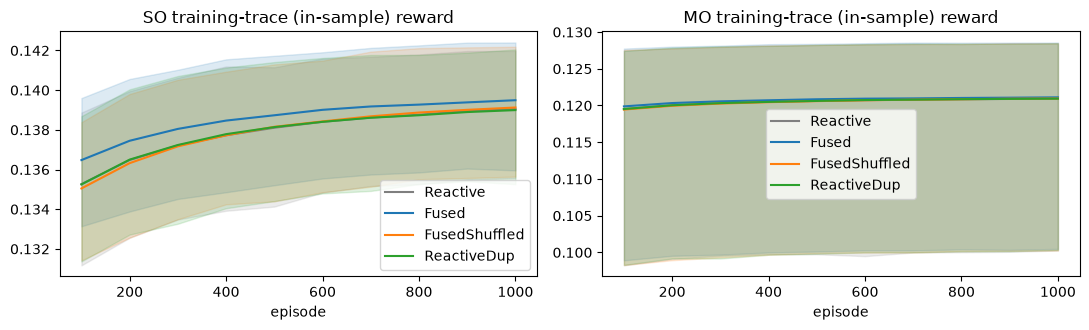

In [17]:
label="training-trace (in-sample)"
rows=[{"agent":f"{o} {g}","seed":s,"fold":int(s[1:s.index("s")]),"monitor_reward_final":z["curve"][-1][1],"monitor_dMbps_final":z["curve"][-1][2]} for (o,g,s),z in CK.items()]
display(pd.DataFrame(rows).groupby("agent")[["monitor_reward_final","monitor_dMbps_final"]].agg(["mean","std"]).round(4))
try:
    import matplotlib.pyplot as plt
    fig,ax=plt.subplots(1,2,figsize=(11,3.4)); col={"Reactive":"tab:gray","Fused":"tab:blue","FusedShuffled":"tab:orange","ReactiveDup":"tab:green"}
    for k,obj in enumerate(("SO","MO")):
        for reg in REGIMES:
            cs=np.array([[c[1] for c in CK[(obj,reg,s)]["curve"]] for s in [sid(f,sd) for f in range(N_FOLDS) for sd in RL_SEEDS]]); ep=[c[0] for c in CK[(obj,reg,sid(0,RL_SEEDS[0]))]["curve"]]
            ax[k].plot(ep,cs.mean(0),color=col[reg],label=reg); ax[k].fill_between(ep,cs.min(0),cs.max(0),color=col[reg],alpha=.15)
        ax[k].set_title(f"{obj} {label} reward"); ax[k].set_xlabel("episode"); ax[k].legend()
    plt.tight_layout(); plt.show()
except Exception as e:
    print("plot skipped:",e)

In [18]:
# Each fold's test traces are evaluated once, by that fold's own agents (which never trained on them).
FLAGS={}
for f in FOLDS:
    FL=FOLD_DIR[f["fold"]]/"rl_test_evaluated.json"
    if FL.exists():
        fl=json.load(open(FL))
        if fl["cfg_hash"]!=FOLD_HASH[f["fold"]]:
            print(f"WARNING fold {f['fold']}: test traces were already evaluated under config {fl['cfg_hash']} ({fl['time']}); this config is {FOLD_HASH[f['fold']]}. Not an untouched test set.")
        fl["evaluations"]=fl.get("evaluations",1)+1; json.dump(fl,open(FL,"w"))
    else:
        json.dump({"cfg_hash":FOLD_HASH[f["fold"]],"time":time.strftime("%Y-%m-%d %H:%M:%S"),"evaluations":1},open(FL,"w"))

CKPTS=("final",)
TEST=ALL_TEST; rows=[]; STEPD={}; ACT={}
for (obj,reg,agent_id),z in CK.items():
    fold=z["fold"]; seed=z["seed"]
    for which in CKPTS:
        ev=evaluate_agent(load_agent(z,which),FOLDS[fold]["test"],obj,reg)
        for tid,(d,r,a) in ev.items():
            STEPD[(obj,reg,seed,which,tid)]=d; ACT[(obj,reg,seed,which,tid)]=np.bincount(a,minlength=NA)/len(a)
            rows.append({"objective":obj,"regime":reg,"seed":seed,"fold":fold,"ckpt":which,"trace_id":tid,"dmbps":d.mean(),"reward":r.mean()})
RES=pd.DataFrame(rows); PRIMARY=CKPTS[0]
assert RES.groupby(["objective","regime","ckpt","trace_id"]).seed.nunique().eq(len(RL_SEEDS)).all(),"every trace must be tested by one agent per seed"

def block_boot_ci(diffs,block=20,n_boot=2000,seed=0):
    rng=np.random.default_rng(seed); m=[]
    for _ in range(n_boot):
        per=[]
        for d in diffs:
            nb=max(1,len(d)//block); st=rng.integers(0,max(1,len(d)-block+1),nb); per.append(np.mean([d[s:s+block].mean() for s in st]))
        m.append(np.mean(per))
    return float(np.percentile(m,2.5)),float(np.percentile(m,97.5))

def compare(obj,ckpt,a,b):
    tab=[]; diffs=[]
    for tid in TEST:
        r=RES[(RES.objective==obj)&(RES.trace_id==tid)&(RES.ckpt==ckpt)]
        x=r[r.regime==a].set_index("seed"); y=r[r.regime==b].set_index("seed")
        tab.append({"trace_id":tid,f"{a} dMbps":x.dmbps.mean(),f"{b} dMbps":y.dmbps.mean(),f"{b}-{a}":y.dmbps.mean()-x.dmbps.mean(),
                    f"seeds {b}>{a}":f"{int((y.dmbps>x.dmbps).sum())}/{len(y)}"})
        diffs.append(np.mean([STEPD[(obj,b,s,ckpt,tid)]-STEPD[(obj,a,s,ckpt,tid)] for s in RL_SEEDS],axis=0))
    T=pd.DataFrame(tab).set_index("trace_id"); lo,hi=block_boot_ci(diffs)
    return T,int((T[f"{b}-{a}"]>0).sum()),lo,hi

SUMMARY={}
for obj in ("SO","MO"):
    print(f"\n=== {obj}: cross-validated test traces ({len(TEST)}, each tested by agents that never saw it), {PRIMARY} policy, seeds {RL_SEEDS} ===")
    T,wins,lo,hi=compare(obj,PRIMARY,"Reactive","Fused"); display(T.round(4))
    print(f"Fused beats Reactive on {wins}/{len(T)} traces | mean Fused-Reactive {T['Fused-Reactive'].mean():.4f} Mbps, step-level block-bootstrap 95% CI [{lo:.4f}, {hi:.4f}]")
    SUMMARY[f"{obj}_Fused_vs_Reactive"]={"wins":wins,"n":len(T),"mean_diff":float(T['Fused-Reactive'].mean()),"ci95":[lo,hi]}
    if RUN_SHUFFLED_CONTROL:
        T2,w2,lo2,hi2=compare(obj,PRIMARY,"FusedShuffled","Fused")
        print(f"Fused vs shuffled-forecast control: Fused wins {w2}/{len(T2)} | mean Fused-Shuffled {T2['Fused-FusedShuffled'].mean():.4f} Mbps, CI [{lo2:.4f}, {hi2:.4f}]")
        SUMMARY[f"{obj}_Fused_vs_Shuffled"]={"wins":w2,"n":len(T2),"mean_diff":float(T2['Fused-FusedShuffled'].mean()),"ci95":[lo2,hi2]}
    if RUN_REACTIVE_DUP_CONTROL:
        T3,w3,lo3,hi3=compare(obj,PRIMARY,"ReactiveDup","Fused")
        print(f"Fused vs Reactive-8 control (same inputs as Reactive, last DL in the forecast slot): Fused wins {w3}/{len(T3)} | mean Fused-Reactive8 {T3['Fused-ReactiveDup'].mean():.4f} Mbps, CI [{lo3:.4f}, {hi3:.4f}]")
        SUMMARY[f"{obj}_Fused_vs_Reactive8"]={"wins":w3,"n":len(T3),"mean_diff":float(T3['Fused-ReactiveDup'].mean()),"ci95":[lo3,hi3]}
        T4,w4,lo4,hi4=compare(obj,PRIMARY,"Reactive","ReactiveDup")
        print(f"Reactive-8 vs Reactive (input-shape effect): mean {T4['ReactiveDup-Reactive'].mean():+.4f} Mbps, CI [{lo4:.4f}, {hi4:.4f}] | Reactive-8 wins {w4}/{len(T4)}")
        SUMMARY[f"{obj}_Reactive8_vs_Reactive"]={"wins":w4,"n":len(T4),"mean_diff":float(T4['ReactiveDup-Reactive'].mean()),"ci95":[lo4,hi4]}
    ps=RES[(RES.objective==obj)&(RES.ckpt==PRIMARY)].pivot_table(index="seed",columns="regime",values="dmbps"); print("Per-seed mean dMbps over test traces:"); display(ps.round(4))
    fx=fixed_policy_table(TEST,obj); ib=info_benchmarks(TEST,obj).mean()
    print("Fixed-action reference (dMbps):"," | ".join(f"{a} {v:.3f}" for a,v in fx.dMbps.items()))
    print(f"Reference policies (dMbps/step): best fixed {fx.dMbps.max():.3f} | greedy on last DL {ib.prev_dl_greedy:.3f} | greedy on forecast {ib.forecast_greedy:.3f} | oracle {ib.oracle:.3f}")
    print("Agents (mean over seeds and test traces):",", ".join(f"{g} {ps[g].mean():.3f}" for g in REGIMES))
    am=pd.DataFrame({g:np.mean([ACT[(obj,g,s,PRIMARY,t)] for s in RL_SEEDS for t in TEST],axis=0) for g in REGIMES},index=ACTIONS)
    print("Action mix of trained agents (share of test steps):"); display(am.round(3))

def _mat(res,obj,regime,ckpt=None):
    d=res[(res.objective==obj)&(res.regime==regime)]
    if ckpt is not None: d=d[d.ckpt==ckpt]
    return d.pivot(index="trace_id",columns="seed",values="dmbps").loc[TEST]

TWOLEVEL={}
print("\n=== Decision rule (fixed before the run) ===")
print("Effect SUPPORTED if the 95% interval of Fused - Reactive-8, pooled over the 20 cross-validated traces and resampling traces and seeds together, is above zero in both SO and MO; otherwise SUGGESTIVE (point estimate positive) or NOT SUPPORTED.")
for obj in ("SO","MO"):
    for ctrl,label in (("Reactive","Reactive"),("ReactiveDup","Reactive-8"),("FusedShuffled","shuffled forecast")):
        if ctrl not in REGIMES: continue
        pt,lo,hi,pg=two_level_ci(_mat(RES,obj,ctrl,PRIMARY),_mat(RES,obj,"Fused",PRIMARY))
        TWOLEVEL[f"{obj}_Fused_vs_{ctrl}"]={"mean_diff":pt,"ci95":[lo,hi],"share_above_zero":pg}
        print(f"  {obj}: Fused - {label:18s} {pt:+.3f} Mbps, traces x seeds 95% CI [{lo:+.3f}, {hi:+.3f}] ({len(RL_SEEDS)} seeds, {len(TEST)} traces)")
if "ReactiveDup" in REGIMES:
    ok=all(TWOLEVEL[f"{o}_Fused_vs_ReactiveDup"]["ci95"][0]>0 for o in ("SO","MO"))
    pts=[TWOLEVEL[f"{o}_Fused_vs_ReactiveDup"]["mean_diff"] for o in ("SO","MO")]
    print("VERDICT:","SUPPORTED" if ok else ("SUGGESTIVE (positive point estimates, but the interval includes zero in at least one objective)" if all(p>0 for p in pts) else "NOT SUPPORTED (a point estimate is not positive)"))
    print("\nPer-fold breakdown of Fused - Reactive-8 (mean over the fold's 5 traces and all seeds, Mbps):")
    _fb=[]
    for o in ("SO","MO"):
        for fo in range(N_FOLDS):
            ts=FOLDS[fo]["test"]; a=_mat(RES,o,"ReactiveDup",PRIMARY).loc[ts].mean().mean(); b=_mat(RES,o,"Fused",PRIMARY).loc[ts].mean().mean()
            r_=_mat(RES,o,"Reactive",PRIMARY).loc[ts].mean().mean()
            _fb.append({"objective":o,"fold":fo,"Fused-Reactive8":b-a,"Fused-Reactive":b-r_})
    FB=pd.DataFrame(_fb); display(FB.pivot(index="fold",columns="objective",values=["Fused-Reactive8","Fused-Reactive"]).round(3))
    for o in ("SO","MO"): print(f"  {o}: Fused ahead of Reactive-8 in {int((FB[FB.objective==o]['Fused-Reactive8']>0).sum())}/{N_FOLDS} folds, ahead of Reactive in {int((FB[FB.objective==o]['Fused-Reactive']>0).sum())}/{N_FOLDS} folds")
    TWOLEVEL["per_fold"]=FB.to_dict("records")

RES.to_csv(RL_OUT/"rl_test_results_long.csv",index=False)
json.dump({"cfg_hash":CFG_HASH,"fold_hash":FOLD_HASH,"folds":FOLDS,"cfg":CFG,"primary_ckpt":PRIMARY,"summary":SUMMARY,"all_seeds":RL_SEEDS,"twolevel":TWOLEVEL},open(RL_OUT/"rl_summary.json","w"),indent=2,default=str)
print("\nSaved results to",RL_OUT.resolve())
print("Test traces are the 20 eligible traces, each tested once by agents trained without it; the trace-level interval reflects variation across these 20 traces.")


=== SO: cross-validated test traces (20, each tested by agents that never saw it), final policy, seeds [42, 43, 44, 45, 46, 47, 48, 49, 50, 51] ===


,Reactive dMbps,Fused dMbps,Fused-Reactive,seeds Fused>Reactive
trace_id,,,,
Download_Driving_B_2020.02.14_12.58.17,4.8183,4.8446,0.0262,7/10
Download_Driving_B_2020.02.14_09.38.22,65.9795,66.2784,0.2989,8/10
Download_Driving_B_2020.02.27_20.35.57,45.9450,38.7969,-7.1481,0/10
Download_Static_B_2020.01.16_10.43.34,43.4035,45.6675,2.2640,10/10
Download_Driving_B_2019.12.16_14.23.32,39.0706,40.1855,1.1150,10/10
Download_Driving_B_2020.02.13_15.02.01,61.2850,62.9409,1.6558,7/10
Download_Driving_B_2019.12.16_12.27.05,57.8442,58.2020,0.3578,8/10
Download_Driving_B_2020.01.16_09.56.56,46.6544,46.3293,-0.3250,2/10
Download_Driving_B_2019.12.16_11.49.59,3.2709,3.1188,-0.1521,2/10


Fused beats Reactive on 16/20 traces | mean Fused-Reactive 0.5891 Mbps, step-level block-bootstrap 95% CI [0.4423, 0.8674]
Fused vs shuffled-forecast control: Fused wins 16/20 | mean Fused-Shuffled 1.4987 Mbps, CI [1.3520, 1.8257]
Fused vs Reactive-8 control (same inputs as Reactive, last DL in the forecast slot): Fused wins 17/20 | mean Fused-Reactive8 1.5684 Mbps, CI [1.4316, 1.8387]
Reactive-8 vs Reactive (input-shape effect): mean -0.9793 Mbps, CI [-1.2112, -0.7585] | Reactive-8 wins 6/20
Per-seed mean dMbps over test traces:


regime,Fused,FusedShuffled,Reactive,ReactiveDup
seed,,,,
42,37.6929,37.2668,37.0928,36.6696
43,37.5281,36.9450,37.0508,34.5344
44,37.7753,33.8126,36.7874,35.7303
45,37.8568,34.3565,36.9585,36.9159
46,37.7074,37.1422,36.7549,36.9343
47,37.7135,34.1496,35.7643,34.4120
48,37.8175,36.6026,37.1770,36.2145
49,35.9737,34.6205,36.9991,37.0563
50,37.7302,36.9544,36.7913,36.4576


Fixed-action reference (dMbps): Increase_TX_power 24.573 | Adjust_beamforming 27.039 | Optimise_MCS 5.199 | Reduce_interference 30.618 | Increase_bandwidth 5.019 | Load_balance 22.215
Reference policies (dMbps/step): best fixed 30.618 | greedy on last DL 37.887 | greedy on forecast 38.592 | oracle 39.741
Agents (mean over seeds and test traces): Reactive 36.796, Fused 37.385, FusedShuffled 35.887, ReactiveDup 35.817
Action mix of trained agents (share of test steps):


,Reactive,Fused,FusedShuffled,ReactiveDup
Increase_TX_power,0.202,0.209,0.203,0.203
Adjust_beamforming,0.188,0.208,0.189,0.172
Optimise_MCS,0.059,0.053,0.074,0.087
Reduce_interference,0.431,0.415,0.417,0.420
Increase_bandwidth,0.014,0.013,0.014,0.015
Load_balance,0.106,0.102,0.104,0.103


... (5 outputs left out)

,Reactive,Fused,FusedShuffled,ReactiveDup
Increase_TX_power,0.152,0.154,0.157,0.152
Adjust_beamforming,0.115,0.108,0.136,0.117
Optimise_MCS,0.047,0.038,0.040,0.061
Reduce_interference,0.617,0.628,0.595,0.584
Increase_bandwidth,0.010,0.009,0.009,0.016
Load_balance,0.058,0.062,0.063,0.071



=== Decision rule (fixed before the run) ===
Effect SUPPORTED if the 95% interval of Fused - Reactive-8, pooled over the 20 cross-validated traces and resampling traces and seeds together, is above zero in both SO and MO; otherwise SUGGESTIVE (point estimate positive) or NOT SUPPORTED.
  SO: Fused - Reactive           +0.589 Mbps, traces x seeds 95% CI [-0.851, +1.447] (10 seeds, 20 traces)
  SO: Fused - Reactive-8         +1.568 Mbps, traces x seeds 95% CI [+0.303, +3.437] (10 seeds, 20 traces)
  SO: Fused - shuffled forecast  +1.499 Mbps, traces x seeds 95% CI [-0.578, +4.704] (10 seeds, 20 traces)
  MO: Fused - Reactive           +0.632 Mbps, traces x seeds 95% CI [+0.171, +1.139] (10 seeds, 20 traces)
  MO: Fused - Reactive-8         +1.560 Mbps, traces x seeds 95% CI [+0.376, +3.789] (10 seeds, 20 traces)
  MO: Fused - shuffled forecast  +1.190 Mbps, traces x seeds 95% CI [+0.042, +3.726] (10 seeds, 20 traces)
VERDICT: SUPPORTED

Per-fold breakdown of Fused - Reactive-8 (mean ove

Fused-Reactive8        Fused-Reactive       
objective              MO     SO             MO     SO
fold                                                  
0                   2.381  1.453          0.889 -0.689
1                   2.327  2.206          0.210  0.775
2                   0.922  1.946          0.665  1.738
3                   0.611  0.668          0.765  0.532

  SO: Fused ahead of Reactive-8 in 4/4 folds, ahead of Reactive in 3/4 folds
  MO: Fused ahead of Reactive-8 in 4/4 folds, ahead of Reactive in 4/4 folds

Saved results to part3_cv4_run1_artifacts/leadtime_testbed
Test traces are the 20 eligible traces, each tested once by agents trained without it; the trace-level interval reflects variation across these 20 traces.


## 4. Held-out confirmation

Tests whether the Fused-over-Reactive gain transfers to traces that played no part in forecaster training, model selection, RL training or the cross-validated RL tests. Nothing is retrained or tuned: the frozen forecaster produces the forecasts, and the agents trained in section 3 are loaded as they were. Each regime is represented by all 40 agents (4 folds x 10 seeds); the "seed" dimension below indexes these 40 agents. They share training traces across folds, so treat the agent-level interval as descriptive and the trace-level interval as the inferential one.

**Confirmation traces.** Cleaned traces that failed the eligibility screen (zero DL above 5%), up to `CONFIRM_ZERO_MAX` (40%) and with enough holdout steps. They contain outages, so this is a transfer test in a harder regime, not a replay.

**Pre-declared criteria.** Confirmed if, in each of SO and MO, the trace-level bootstrap 95% CI of the Fused - Reactive difference is above zero, and Fused also beats the shuffled-forecast control the same way. The unit of inference is the trace, and a verdict is only issued with at least `MIN_CONF_TRACES` (8) traces; otherwise it is reported as INCONCLUSIVE. Fused vs Reactive-8 is the primary control and is reported with the same trace-level and traces-x-agents intervals.


In [19]:
# ---------------------------------------------------------------------------------------------
# Confirmation set: cleaned traces that failed the eligibility screen. They were never used for forecaster training,
# model selection, RL training or the earlier RL tests. Models and scaler are frozen; each trace is normalized from its own
# development portion (first 80%) and forecast on its holdout portion, exactly as for the eligible traces.
# ---------------------------------------------------------------------------------------------
CONFIRM_ZERO_MAX=0.40   # widened from 0.20, which yielded a single trace
MIN_CONF_TRACES=8
CONFIRM_MIN_ALIGNED=60
CONF_DIR=OUT/"confirmation"; CONF_DIR.mkdir(exist_ok=True)

excl=screen[~screen.eligible]
print("Excluded traces by zero-DL fraction:")
display(pd.cut(excl.zero_frac,[0.05,.10,.20,.40,1.0]).value_counts().sort_index().to_frame("traces"))

conf=[]
for t in all_traces:
    if not (0.05<t["zero_frac"]<=CONFIRM_ZERO_MAX): continue
    d=final_data(t)
    if len(d["Yte"])-(SEQ_LEN-1)>=CONFIRM_MIN_ALIGNED: conf.append(d)
assert not {d["id"] for d in conf}&{t["id"] for t in traces}, "confirmation traces must not overlap the eligible traces"
print(f"Confirmation traces: {len(conf)} (zero DL in (5%, {CONFIRM_ZERO_MAX:.0%}], at least {CONFIRM_MIN_ALIGNED} aligned holdout steps)")
print(f"  static {sum('Static' in d['id'] for d in conf)}, driving {sum('Driving' in d['id'] for d in conf)}")

Excluded traces by zero-DL fraction:


,traces
zero_frac,
"(0.05, 0.1]",1
"(0.1, 0.2]",0
"(0.2, 0.4]",20
"(0.4, 1.0]",42


Confirmation traces: 21 (zero DL in (5%, 40%], at least 60 aligned holdout steps)
  static 5, driving 16


In [20]:
if "models" not in globals():
    scaler=joblib.load(OUT/"feature_scaler.joblib"); models={}
    _cv=pd.read_csv(OUT/"cv_model_selection.csv"); top4=_cv.head(4).model.tolist()
    _w=1/_cv.head(4).cv_rmse_median.to_numpy(); weights=_w/_w.sum()
    for name in top4:
        safe=name.lower().replace(" ","_")
        if name in SEQ_MODELS:
            m=make_model(name,int(scaler.n_features_in_)); m.load_state_dict(torch.load(OUT/f"{safe}.pt")); m.eval()
        else: m=joblib.load(OUT/f"{safe}.joblib")
        models[name]=m
    print("Frozen models loaded from disk:",top4)

def ensemble_forecast(d):
    Xt=scaler.transform(d["Xte"]).astype(np.float32)
    pp=[]; oo=[]; ww=[]
    for name,wt in zip(top4,weights):
        p,off=predict(name,models[name],Xt); pp.append(p); oo.append(off); ww.append(wt)
    common=max(oo); aligned=[p[common-o:] for p,o in zip(pp,oo)]
    n=min([len(x) for x in aligned]+[len(d["Yte"])-common])
    W=np.asarray(ww); W=W/W.sum()
    ens=np.tensordot(W,np.stack([x[:n] for x in aligned]),axes=(0,0)).astype(np.float32)
    y=d["Yte"][common:common+n]; yt,yp=inv(y,d["p"]),inv(ens,d["p"])
    return {"y":y,"p":ens,"actual":yt,"forecast":yp,"off":common,"last":d["Xte"][common:common+n,0]}

rows=[]; couts={}
for d in conf:
    o=ensemble_forecast(d); couts[d["id"]]=o; a,f=o["actual"][:,0],o["forecast"][:,0]
    r=pearsonr(a,f)[0] if len(a)>2 and np.std(a)>0 and np.std(f)>0 else np.nan
    rows.append({"trace_id":d["id"],"n_holdout":len(a),"rmse_mbps":np.sqrt(mean_squared_error(o["actual"].ravel(),o["forecast"].ravel())),
                 "mae_mbps":mean_absolute_error(o["actual"].ravel(),o["forecast"].ravel()),"pearson_r_h1":r})
cres=pd.DataFrame(rows).sort_values("rmse_mbps"); cres.to_csv(CONF_DIR/"confirmation_forecast_results.csv",index=False)
print("Confirmation traces, frozen-ensemble holdout forecast accuracy (h=1..10 pooled):"); display(cres[["rmse_mbps","mae_mbps","pearson_r_h1"]].describe().round(3))

hz=[]
for h in range(HORIZON):
    er=[];pr=[];ea=[];pa=[]
    for d in conf:
        o=couts[d["id"]]; a=o["actual"][:,h]; f=o["forecast"][:,h]; p=inv(o["last"],d["p"])
        er.append(np.sqrt(np.mean((a-f)**2))); pr.append(np.sqrt(np.mean((a-p)**2))); ea.append(np.mean(np.abs(a-f))); pa.append(np.mean(np.abs(a-p)))
    hz.append({"horizon":h+1,"ensemble_rmse":np.mean(er),"persistence_rmse":np.mean(pr),"rmse_skill":1-np.mean(er)/np.mean(pr),
               "ensemble_mae":np.mean(ea),"persistence_mae":np.mean(pa),"mae_skill":1-np.mean(ea)/np.mean(pa),
               "traces_ensemble_better_rmse":int(np.sum(np.array(er)<np.array(pr)))})
hs=pd.DataFrame(hz).set_index("horizon"); hs.to_csv(CONF_DIR/"confirmation_horizon_skill.csv")
print("\nForecast skill vs naive persistence on confirmation traces (positive = ensemble better; Mbps):"); display(hs.round(3))

cb={}; cman=[]; caud=[]
for d in conf:
    o=couts[d["id"]]; off=o["off"]; n=len(o["actual"]); origins=d["origins"][off:off+n]; key=re.sub(r"[^A-Za-z0-9_]+","_",d["id"])
    cb[f"{key}__trace_id"]=np.array(d["id"]); cb[f"{key}__actual_norm"]=o["y"][:,0]; cb[f"{key}__forecast_norm"]=o["p"][:,0]
    cb[f"{key}__actual_mbps"]=o["actual"][:,0]; cb[f"{key}__forecast_mbps"]=o["forecast"][:,0]
    cb[f"{key}__covariates_raw"]=d["df"].iloc[origins][COVARIATES].to_numpy(np.float32); cb[f"{key}__origin_index"]=origins
    cb[f"{key}__actual_h_norm"]=o["y"].astype(np.float32); cb[f"{key}__forecast_h_norm"]=o["p"].astype(np.float32); cb[f"{key}__last_obs_norm"]=o["last"].astype(np.float32)
    cman.append({"key":key,"trace_id":d["id"],"n":n,"zero_frac":float((d["df"][TARGET].to_numpy()==0).mean())})
    row={"trace_id":d["id"],"split_row":d["split"]}
    for c in [TARGET]+COVARIATES:
        lo,hi=d["p"][c]; row[f"{c}_dev_min"]=lo; row[f"{c}_dev_max"]=hi
    caud.append(row)
np.savez_compressed(CONF_DIR/"confirmation_bundle.npz",**cb)
pd.DataFrame(cman).to_csv(CONF_DIR/"confirmation_manifest.csv",index=False); pd.DataFrame(caud).to_csv(CONF_DIR/"confirmation_audit.csv",index=False)
print("\nSaved confirmation bundle to",CONF_DIR.resolve(),"|",len(cman),"traces")

Confirmation traces, frozen-ensemble holdout forecast accuracy (h=1..10 pooled):


,rmse_mbps,mae_mbps,pearson_r_h1
count,21.000,21.000,21.000
mean,8.389,6.057,0.140
std,16.638,10.399,0.369
min,1.110,0.806,-0.380
25%,2.514,1.817,-0.173
50%,2.911,2.483,0.048
75%,8.600,6.270,0.485
max,78.970,49.284,0.827



Forecast skill vs naive persistence on confirmation traces (positive = ensemble better; Mbps):


,ensemble_rmse,persistence_rmse,rmse_skill,ensemble_mae,persistence_mae,mae_skill,traces_ensemble_better_rmse
horizon,,,,,,,
1,5.449,5.268,-0.034,3.629,3.061,-0.185,13
2,6.364,5.838,-0.090,4.391,2.795,-0.571,5
3,7.896,7.333,-0.077,5.720,4.068,-0.406,3
4,8.278,7.556,-0.096,6.124,3.932,-0.557,3
5,8.785,8.339,-0.053,6.479,4.650,-0.393,4
6,9.131,8.734,-0.046,6.751,4.882,-0.383,4
7,9.103,8.809,-0.033,6.807,4.810,-0.415,5
8,9.416,9.029,-0.043,7.033,5.131,-0.371,5
9,9.180,8.729,-0.052,6.868,4.621,-0.486,5



Saved confirmation bundle to part3_cv4_run1_artifacts/confirmation | 21 traces


In [21]:
CONF=OUT/"confirmation"
_sum=json.load(open(RL_OUT/"rl_summary.json")); TRAINED=_sum["cfg"]; TRAIN_HASH=_sum["cfg_hash"]; FOLD_HASH_S={int(k):v for k,v in _sum["fold_hash"].items()}
C_SEEDS=[f"f{f}s{sd}" for f in range(N_FOLDS) for sd in _sum["all_seeds"]]; C_REGIMES=list(TRAINED["regimes"]); N_BOOT=5000
assert int(TRAINED["lag"])==ACTION_LAG, f"ACTION_LAG is {ACTION_LAG} but the saved agents were trained with lead {TRAINED['lag']}"

c_manifest=pd.read_csv(CONF/"confirmation_manifest.csv")
c_audit=pd.read_csv(CONF/"confirmation_audit.csv").set_index("trace_id")
c_bundle=np.load(CONF/"confirmation_bundle.npz")

CREC={}
for _,r in c_manifest.iterrows():
    k,tid=r["key"],r["trace_id"]; a=c_audit.loc[tid]
    cov_raw=c_bundle[f"{k}__covariates_raw"].astype(np.float64); cov=np.zeros_like(cov_raw); rngs=np.ones(len(COVARIATES))
    for j,c in enumerate(COVARIATES):
        lo,hi=a[f"{c}_dev_min"],a[f"{c}_dev_max"]
        if hi>lo: cov[:,j]=(cov_raw[:,j]-lo)/(hi-lo); rngs[j]=hi-lo
    CREC[tid]=dict(y=c_bundle[f"{k}__actual_norm"].astype(np.float64),forecast=c_bundle[f"{k}__forecast_norm"].astype(np.float64),
                   fh=c_bundle[f"{k}__forecast_h_norm"].astype(np.float64),last=c_bundle[f"{k}__last_obs_norm"].astype(np.float64),
                   cov=cov,cov_raw=cov_raw,cov_rng=rngs,y_mbps=c_bundle[f"{k}__actual_mbps"].astype(np.float64),
                   lo=float(a["DL_Mbps_dev_min"]),hi=float(a["DL_Mbps_dev_max"]),zero_frac=float(r["zero_frac"]),
                   mobility="Static" if "Static" in tid else "Driving")
    assert len(CREC[tid]["y"])==len(CREC[tid]["forecast"])==len(cov)==len(CREC[tid]["fh"])>ACTION_LAG+STEPS,tid
CONF_IDS=list(CREC)
print(f"Confirmation traces: {len(CREC)} | aligned steps median {int(np.median([len(r['y']) for r in CREC.values()]))} | "
      f"static {sum(r['mobility']=='Static' for r in CREC.values())}, driving {sum(r['mobility']=='Driving' for r in CREC.values())} | "
      f"zero DL median {np.median([r['zero_frac'] for r in CREC.values()]):.1%}")
print(f"Frozen agents (config {TRAIN_HASH}): lead {ACTION_LAG}, {len(C_SEEDS)} agents per regime (4 folds x {len(_sum['all_seeds'])} seeds), regimes {C_REGIMES}")

def load_frozen(objective,regime,agent_id):
    fold=int(agent_id[1:agent_id.index("s")]); seed=int(agent_id[agent_id.index("s")+1:])
    z=torch.load(RL_OUT/f"fold{fold}"/f"rl_{objective}_{regime}_seed{seed}_{FOLD_HASH_S[fold]}.pt",weights_only=False)
    class _Shim: pass
    ag=_Shim(); ag.q=DQNNet(z["n_state"],z["n_action"]); ag.q.load_state_dict(z["final_state"]); ag.q.eval(); return ag


Confirmation traces: 21 | aligned steps median 344 | static 5, driving 16 | zero DL median 33.9%
Frozen agents (config 8e80425230): lead 3, 40 agents per regime (4 folds x 10 seeds), regimes ['Reactive', 'Fused', 'FusedShuffled', 'ReactiveDup']


In [22]:
mf=[];mp=[]; ef=[];ep=[]
for t in CONF_IDS:
    N,c,last,fc,y=lead_arrays(CREC[t],ACTION_LAG); s=CREC[t]["hi"]-CREC[t]["lo"]; ef.append((fc-y)*s); ep.append((last-y)*s)
pe=np.array([np.sqrt(np.mean(a**2)) for a in ef]); pp=np.array([np.sqrt(np.mean(a**2)) for a in ep])
ef=np.concatenate(ef); ep=np.concatenate(ep)
print(f"Lead {ACTION_LAG}, estimate of DL at the landing step on confirmation traces: MAE forecast {np.abs(ef).mean():.2f} vs last DL {np.abs(ep).mean():.2f} Mbps "
      f"({100*(1-np.abs(ef).mean()/np.abs(ep).mean()):+.1f}%); RMSE {np.sqrt((ef**2).mean()):.2f} vs {np.sqrt((ep**2).mean()):.2f} ({100*(1-np.sqrt((ef**2).mean())/np.sqrt((ep**2).mean())):+.1f}%); "
      f"forecast has lower RMSE on {int((pe<pp).sum())}/{len(pe)} traces")
for obj in ("SO","MO"):
    ib=info_benchmarks(CONF_IDS,obj,store=CREC).mean(); ft=fixed_policy_table(CONF_IDS,obj,store=CREC)
    print(f"{obj} reference policies on confirmation traces (dMbps/step): best fixed {ft.dMbps.max():.3f} | greedy on last DL {ib.prev_dl_greedy:.3f} | "
          f"greedy on forecast {ib.forecast_greedy:.3f} | oracle {ib.oracle:.3f} | information ceiling {ib.forecast_greedy-ib.prev_dl_greedy:+.3f}")

Lead 3, estimate of DL at the landing step on confirmation traces: MAE forecast 8.12 vs last DL 4.79 Mbps (-69.7%); RMSE 19.27 vs 22.24 (+13.4%); forecast has lower RMSE on 3/21 traces
SO reference policies on confirmation traces (dMbps/step): best fixed 10.047 | greedy on last DL 13.132 | greedy on forecast 13.174 | oracle 13.380 | information ceiling +0.042
MO reference policies on confirmation traces (dMbps/step): best fixed 10.047 | greedy on last DL 12.402 | greedy on forecast 12.362 | oracle 12.654 | information ceiling -0.040


In [23]:
CFLAG=CONF/"confirmation_evaluated.json"
if CFLAG.exists():
    fl=json.load(open(CFLAG)); fl["evaluations"]=fl.get("evaluations",1)+1; json.dump(fl,open(CFLAG,"w"))
    print(f"NOTE: this confirmation set was already evaluated at {fl['time']} (evaluation #{fl['evaluations']}). Do not change anything between evaluations.")
else:
    json.dump({"train_hash":TRAIN_HASH,"time":time.strftime("%Y-%m-%d %H:%M:%S"),"evaluations":1},open(CFLAG,"w"))

rows=[]; CACT={}
for obj in ("SO","MO"):
    for reg in C_REGIMES:
        for seed in C_SEEDS:
            ag=load_frozen(obj,reg,seed)
            for tid in CONF_IDS:
                d,r,a=run_episode(tid,obj,reg,lambda s:greedy_act(ag,s),CREC); CACT[(obj,reg,seed,tid)]=np.bincount(a,minlength=NA)/len(a)
                rows.append({"objective":obj,"regime":reg,"seed":seed,"trace_id":tid,"dmbps":d.mean(),"reward":r.mean()})
CRES=pd.DataFrame(rows); CRES.to_csv(CONF/"confirmation_rl_results_long.csv",index=False)

def trace_table(obj,a,b):
    p=CRES[CRES.objective==obj].groupby(["trace_id","regime"]).dmbps.mean().unstack()
    seeds=CRES[CRES.objective==obj].pivot_table(index=["trace_id","seed"],columns="regime",values="dmbps")
    T=pd.DataFrame({f"{a}":p[a],f"{b}":p[b],"diff":p[b]-p[a]})
    T["rel_%"]=100*T["diff"]/T[a].abs().clip(lower=1e-9)
    T["seeds_b_gt_a"]=[f"{int((seeds.loc[t][b]>seeds.loc[t][a]).sum())}/{len(C_SEEDS)}" for t in T.index]
    T["zero_frac"]=[CREC[t]["zero_frac"] for t in T.index]; T["mean_dl_mbps"]=[CREC[t]["y_mbps"].mean() for t in T.index]
    return T

def trace_ci(x,n=N_BOOT,seed=0):
    rng=np.random.default_rng(seed); x=np.asarray(x); m=[x[rng.integers(0,len(x),len(x))].mean() for _ in range(n)]
    return float(np.percentile(m,2.5)),float(np.percentile(m,97.5))

def wilcoxon_p(x):
    from scipy.stats import wilcoxon
    x=np.asarray(x)
    return float(wilcoxon(x).pvalue) if np.any(x!=0) else 1.0

def _cm(obj,regime):
    return CRES[(CRES.objective==obj)&(CRES.regime==regime)].pivot(index="trace_id",columns="seed",values="dmbps").loc[CONF_IDS]

VERDICT={}
for obj in ("SO","MO"):
    print(f"\n=== {obj}: confirmation traces ({len(CONF_IDS)}), frozen agents, {len(C_SEEDS)} agents (4 folds x seeds) ===")
    T=trace_table(obj,"Reactive","Fused"); display(T.round(3))
    lo,hi=trace_ci(T["diff"]); p=wilcoxon_p(T["diff"])
    print(f"Fused vs Reactive: mean diff {T['diff'].mean():+.3f} Mbps (trace-level bootstrap 95% CI [{lo:+.3f}, {hi:+.3f}]), median {T['diff'].median():+.3f}, "
          f"median relative {T['rel_%'].median():+.2f}% | Fused wins {int((T['diff']>0).sum())}/{len(T)} traces | Wilcoxon p={p:.3f}")
    ok1=lo>0
    ok2=None
    if "FusedShuffled" in C_REGIMES:
        T2=trace_table(obj,"FusedShuffled","Fused"); lo2,hi2=trace_ci(T2["diff"]); p2=wilcoxon_p(T2["diff"])
        print(f"Fused vs shuffled-forecast control: mean diff {T2['diff'].mean():+.3f} Mbps (CI [{lo2:+.3f}, {hi2:+.3f}]) | Fused wins {int((T2['diff']>0).sum())}/{len(T2)} | Wilcoxon p={p2:.3f}")
        ok2=lo2>0
    ok3=None; tl3=None
    if "ReactiveDup" in C_REGIMES:
        T3=trace_table(obj,"ReactiveDup","Fused"); lo3,hi3=trace_ci(T3["diff"]); p3=wilcoxon_p(T3["diff"])
        print(f"Fused vs Reactive-8 control (pre-declared primary control): mean diff {T3['diff'].mean():+.3f} Mbps (CI [{lo3:+.3f}, {hi3:+.3f}]) | Fused wins {int((T3['diff']>0).sum())}/{len(T3)} | Wilcoxon p={p3:.3f}")
        T4=trace_table(obj,"Reactive","ReactiveDup"); lo4,hi4=trace_ci(T4["diff"])
        print(f"Reactive-8 vs Reactive (input-shape effect): mean {T4['diff'].mean():+.3f} Mbps (CI [{lo4:+.3f}, {hi4:+.3f}]) | Reactive-8 wins {int((T4['diff']>0).sum())}/{len(T4)}")
        ok3=bool(lo3>0)
        pt2,lo2_,hi2_,_=two_level_ci(_cm(obj,"ReactiveDup"),_cm(obj,"Fused")); tl3=[lo2_,hi2_]
        print(f"  same comparison resampling traces and seeds: {pt2:+.3f} Mbps, 95% CI [{lo2_:+.3f}, {hi2_:+.3f}] ({len(C_SEEDS)} agents, {len(CONF_IDS)} traces)")
    per_seed=CRES[CRES.objective==obj].pivot_table(index="seed",columns="regime",values="dmbps"); print("Per-seed mean dMbps over confirmation traces:"); display(per_seed.round(3))
    VERDICT[obj]={"mean_diff":float(T["diff"].mean()),"ci":[lo,hi],"wins":int((T["diff"]>0).sum()),"n":len(T),"fused_gt_reactive_ci_excludes_0":bool(ok1),"fused_gt_shuffled_ci_excludes_0":ok2,"conclusive":bool(len(T)>=MIN_CONF_TRACES),"fused_gt_reactive8_ci_excludes_0":ok3,"reactive8_twolevel_ci":tl3}

print("\nPre-declared confirmation criteria: Fused beats Reactive with the trace-level CI above zero, and beats the shuffled-forecast control the same way; a verdict needs at least",MIN_CONF_TRACES,"traces.")
for obj,v in VERDICT.items():
    if not v["conclusive"]:
        print(f"  {obj}: INCONCLUSIVE ({v['n']} traces < {MIN_CONF_TRACES})"); continue
    print(f"  {obj}: vs Reactive {'MET' if v['fused_gt_reactive_ci_excludes_0'] else 'NOT MET'}"+(f" | vs shuffled {'MET' if v['fused_gt_shuffled_ci_excludes_0'] else 'NOT MET'}" if v['fused_gt_shuffled_ci_excludes_0'] is not None else ""))
json.dump(VERDICT,open(CONF/"confirmation_summary.json","w"),indent=2,default=str)
print("Saved to",CONF.resolve())


=== SO: confirmation traces (21), frozen agents, 40 agents (4 folds x seeds) ===


,Reactive,Fused,diff,rel_%,seeds_b_gt_a,zero_frac,mean_dl_mbps
trace_id,,,,,,,
Amazon_Prime_Driving_Season3-TheExpanse_B_2019.12.01_12.11.21,4.218,4.548,0.330,7.818,36/40,0.342,0.574
Amazon_Prime_Driving_Season3-TheExpanse_B_2019.12.01_13.05.00,3.964,5.796,1.832,46.206,29/40,0.339,0.427
Amazon_Prime_Driving_Season3-TheExpanse_B_2019.12.02_07.26.15,8.312,8.386,0.074,0.890,32/40,0.384,0.789
Amazon_Prime_Driving_Season3-TheExpanse_B_2019.12.02_12.41.17,13.725,14.193,0.467,3.406,22/40,0.328,0.598
Amazon_Prime_Driving_Season3-TheExpanse_B_2019.12.03_07.29.22,7.557,7.825,0.268,3.546,33/40,0.393,0.318
Amazon_Prime_Driving_Season3-TheExpanse_B_2019.12.03_10.42.14,14.619,14.771,0.151,1.034,26/40,0.332,0.521
Amazon_Prime_Driving_Season3-TheExpanse_B_2019.12.03_13.58.03,3.236,3.264,0.028,0.860,32/40,0.350,0.664
Amazon_Prime_Driving_Season3-TheExpanse_B_2019.12.04_07.26.30,6.007,6.057,0.050,0.833,35/40,0.376,0.663
Amazon_Prime_Driving_Season3-TheExpanse_B_2019.12.04_14.24.21,10.142,10.749,0.607,5.986,7/40,0.276,0.448


Fused vs Reactive: mean diff +0.763 Mbps (trace-level bootstrap 95% CI [+0.345, +1.326]), median +0.329, median relative +3.55% | Fused wins 21/21 traces | Wilcoxon p=0.000
Fused vs shuffled-forecast control: mean diff +0.417 Mbps (CI [+0.139, +0.792]) | Fused wins 19/21 | Wilcoxon p=0.000
Fused vs Reactive-8 control (pre-declared primary control): mean diff +0.740 Mbps (CI [+0.348, +1.222]) | Fused wins 20/21 | Wilcoxon p=0.000
Reactive-8 vs Reactive (input-shape effect): mean +0.022 Mbps (CI [-0.074, +0.145]) | Reactive-8 wins 8/21
  same comparison resampling traces and seeds: +0.740 Mbps, 95% CI [+0.336, +1.316] (40 agents, 21 traces)
Per-seed mean dMbps over confirmation traces:


regime,Fused,FusedShuffled,Reactive,ReactiveDup
seed,,,,
f0s42,12.884,12.498,12.311,12.468
f0s43,12.573,11.733,12.235,11.342
f0s44,13.013,12.445,12.459,12.310
f0s45,12.670,12.736,11.921,12.502
f0s46,12.678,11.610,12.525,11.696
f0s47,13.010,11.779,10.879,12.459
f0s48,12.395,12.016,12.132,11.801
f0s49,12.884,11.469,12.461,11.816
f0s50,12.493,12.437,12.158,12.339



=== MO: confirmation traces (21), frozen agents, 40 agents (4 folds x seeds) ===


,Reactive,Fused,diff,rel_%,seeds_b_gt_a,zero_frac,mean_dl_mbps
trace_id,,,,,,,
Amazon_Prime_Driving_Season3-TheExpanse_B_2019.12.01_12.11.21,4.319,4.508,0.189,4.376,36/40,0.342,0.574
Amazon_Prime_Driving_Season3-TheExpanse_B_2019.12.01_13.05.00,3.843,5.389,1.546,40.229,31/40,0.339,0.427
Amazon_Prime_Driving_Season3-TheExpanse_B_2019.12.02_07.26.15,8.189,8.319,0.130,1.593,32/40,0.384,0.789
Amazon_Prime_Driving_Season3-TheExpanse_B_2019.12.02_12.41.17,14.217,14.258,0.041,0.286,14/40,0.328,0.598
Amazon_Prime_Driving_Season3-TheExpanse_B_2019.12.03_07.29.22,7.517,7.659,0.142,1.892,26/40,0.393,0.318
Amazon_Prime_Driving_Season3-TheExpanse_B_2019.12.03_10.42.14,14.594,14.707,0.113,0.777,25/40,0.332,0.521
Amazon_Prime_Driving_Season3-TheExpanse_B_2019.12.03_13.58.03,3.194,3.199,0.005,0.160,19/40,0.350,0.664
Amazon_Prime_Driving_Season3-TheExpanse_B_2019.12.04_07.26.30,5.930,5.993,0.063,1.056,35/40,0.376,0.663
Amazon_Prime_Driving_Season3-TheExpanse_B_2019.12.04_14.24.21,10.376,10.322,-0.053,-0.514,3/40,0.276,0.448


Fused vs Reactive: mean diff +0.438 Mbps (trace-level bootstrap 95% CI [+0.159, +0.774]), median +0.130, median relative +1.77% | Fused wins 18/21 traces | Wilcoxon p=0.000
Fused vs shuffled-forecast control: mean diff +0.240 Mbps (CI [+0.030, +0.507]) | Fused wins 16/21 | Wilcoxon p=0.011
Fused vs Reactive-8 control (pre-declared primary control): mean diff +0.559 Mbps (CI [+0.217, +1.006]) | Fused wins 19/21 | Wilcoxon p=0.000
Reactive-8 vs Reactive (input-shape effect): mean -0.121 Mbps (CI [-0.251, -0.015]) | Reactive-8 wins 7/21
  same comparison resampling traces and seeds: +0.559 Mbps, 95% CI [+0.186, +1.077] (40 agents, 21 traces)
Per-seed mean dMbps over confirmation traces:


regime,Fused,FusedShuffled,Reactive,ReactiveDup
seed,,,,
f0s42,12.489,12.452,11.992,12.192
f0s43,12.732,12.374,12.448,11.819
f0s44,12.436,12.111,11.901,12.508
f0s45,12.430,12.191,11.666,11.699
f0s46,12.556,11.828,12.265,11.328
f0s47,12.217,11.932,11.874,12.241
f0s48,12.390,12.178,12.366,11.754
f0s49,12.450,11.918,12.315,11.542
f0s50,12.110,11.854,12.277,11.990



Pre-declared confirmation criteria: Fused beats Reactive with the trace-level CI above zero, and beats the shuffled-forecast control the same way; a verdict needs at least 8 traces.
  SO: vs Reactive MET | vs shuffled MET
  MO: vs Reactive MET | vs shuffled MET
Saved to part3_cv4_run1_artifacts/confirmation


## 4b. Does the Fused gain track forecast skill?

For every cross-validated test trace (section 3) and every confirmation trace, this compares the forecast's skill against last-observed DL at the action lead with the gain of the Fused agent over the shuffled-forecast control. If the forecast is what helps, the gain should be larger where the forecast is more skilful. The correlation is computed on all traces and on the confirmation traces alone; the per-trace table is saved to `<RUN_TAG>_artifacts/confirmation/skill_vs_gain_per_trace.csv`. With about 41 traces this is descriptive evidence, not a test of a pre-declared hypothesis.

Per-trace forecast skill at lead 3 (1 - RMSE forecast / RMSE last DL) vs the gain of Fused over the shuffled-forecast control.
rel_gain_% = (Fused - shuffled) / Reactive dMbps, so traces with different throughput scales are comparable.



,objective,set,n,spearman_rho,p_value,n_skill>0,mean_rel_gain_skill>0_%,n_skill<=0,mean_rel_gain_skill<=0_%
0,SO,all traces,41,0.047,0.771,19,1.905,22,5.549
1,SO,confirmation only,21,-0.047,0.841,3,0.618,18,4.726
2,MO,all traces,41,-0.053,0.740,19,0.912,22,2.768
3,MO,confirmation only,21,-0.209,0.363,3,-0.124,18,3.318



Same comparison against the Reactive-8 control (identical inputs and shape, no forecast information): rel_gain_reactive8_% = (Fused - Reactive-8) / Reactive


,objective,set,n,spearman_rho,p_value,mean_rel_gain_skill>0_%,mean_rel_gain_skill<=0_%
0,SO,all traces,41,-0.339,0.030,1.904,9.938
1,SO,confirmation only,21,-0.334,0.139,0.878,8.340
2,MO,all traces,41,-0.283,0.073,1.332,6.798
3,MO,confirmation only,21,-0.122,0.598,0.589,5.816


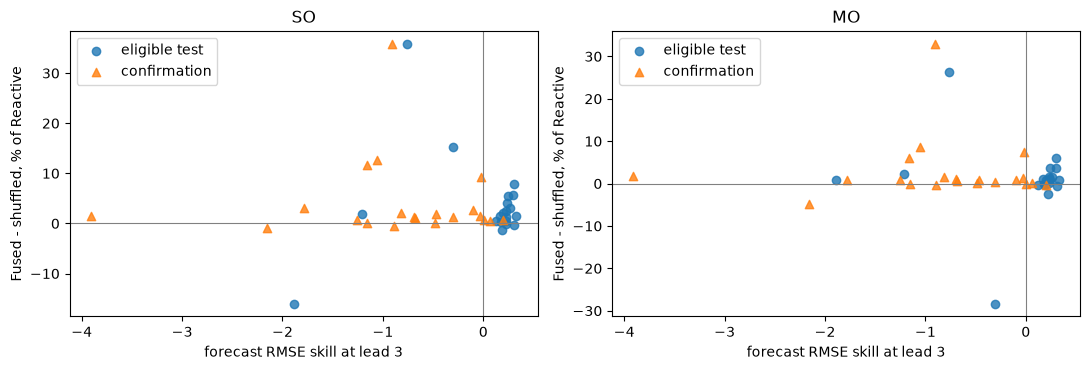

In [24]:
from scipy.stats import spearmanr

def trace_skill(rec,L):
    """RMSE skill of the forecast against last observed DL, for the DL at the landing step (unit-free, per trace)."""
    N,c,last,fc,y=lead_arrays(rec,L)
    den=np.sqrt(np.mean((last-y)**2))
    return float(1-np.sqrt(np.mean((fc-y)**2))/den) if den>1e-12 else np.nan

def regime_means(res,obj,ids):
    p=res[res.objective==obj].groupby(["trace_id","regime"]).dmbps.mean().unstack()
    return p.loc[ids,[c for c in ("Reactive","Fused","FusedShuffled","ReactiveDup") if c in p.columns]]

rows=[]
for obj in ("SO","MO"):
    for grp,res,ids,store in (("eligible test",RES[RES.ckpt==PRIMARY],ALL_TEST,REC),("confirmation",CRES,CONF_IDS,CREC)):
        g=regime_means(res,obj,ids)
        for tid in ids:
            f_s=g.loc[tid,"Fused"]-g.loc[tid,"FusedShuffled"]
            rows.append({"objective":obj,"group":grp,"trace_id":tid,"skill":trace_skill(store[tid],ACTION_LAG),
                         "fused_minus_shuffled":f_s,"rel_gain_%":100*f_s/max(abs(g.loc[tid,"Reactive"]),1e-9),
                         "rel_gain_reactive8_%":(100*(g.loc[tid,"Fused"]-g.loc[tid,"ReactiveDup"])/max(abs(g.loc[tid,"Reactive"]),1e-9)) if "ReactiveDup" in g.columns else np.nan})
SK=pd.DataFrame(rows).dropna(subset=["skill"]); SK.to_csv(CONF/"skill_vs_gain_per_trace.csv",index=False)

print(f"Per-trace forecast skill at lead {ACTION_LAG} (1 - RMSE forecast / RMSE last DL) vs the gain of Fused over the shuffled-forecast control.")
print("rel_gain_% = (Fused - shuffled) / Reactive dMbps, so traces with different throughput scales are comparable.\n")
out=[]
for obj in ("SO","MO"):
    for label,sub in (("all traces",SK[SK.objective==obj]),("confirmation only",SK[(SK.objective==obj)&(SK.group=="confirmation")])):
        rho,p=spearmanr(sub["skill"],sub["rel_gain_%"])
        pos=sub[sub.skill>0]["rel_gain_%"]; neg=sub[sub.skill<=0]["rel_gain_%"]
        out.append({"objective":obj,"set":label,"n":len(sub),"spearman_rho":rho,"p_value":p,
                    "n_skill>0":len(pos),"mean_rel_gain_skill>0_%":pos.mean() if len(pos) else np.nan,
                    "n_skill<=0":len(neg),"mean_rel_gain_skill<=0_%":neg.mean() if len(neg) else np.nan})
display(pd.DataFrame(out).round(3))

if SK["rel_gain_reactive8_%"].notna().any():
    print("\nSame comparison against the Reactive-8 control (identical inputs and shape, no forecast information): rel_gain_reactive8_% = (Fused - Reactive-8) / Reactive")
    o2=[]
    for obj in ("SO","MO"):
        for label,sub in (("all traces",SK[SK.objective==obj]),("confirmation only",SK[(SK.objective==obj)&(SK.group=="confirmation")])):
            rho,p=spearmanr(sub["skill"],sub["rel_gain_reactive8_%"]); o2.append({"objective":obj,"set":label,"n":len(sub),"spearman_rho":rho,"p_value":p,
                "mean_rel_gain_skill>0_%":sub[sub.skill>0]["rel_gain_reactive8_%"].mean(),"mean_rel_gain_skill<=0_%":sub[sub.skill<=0]["rel_gain_reactive8_%"].mean()})
    display(pd.DataFrame(o2).round(3))

try:
    import matplotlib.pyplot as plt
    fig,ax=plt.subplots(1,2,figsize=(11,3.8))
    for k,obj in enumerate(("SO","MO")):
        for grp,mk in (("eligible test","o"),("confirmation","^")):
            s=SK[(SK.objective==obj)&(SK.group==grp)]; ax[k].scatter(s.skill,s["rel_gain_%"],marker=mk,label=grp,alpha=.8)
        ax[k].axhline(0,color="grey",lw=.8); ax[k].axvline(0,color="grey",lw=.8)
        ax[k].set_xlabel(f"forecast RMSE skill at lead {ACTION_LAG}"); ax[k].set_ylabel("Fused - shuffled, % of Reactive"); ax[k].set_title(obj); ax[k].legend()
    plt.tight_layout(); plt.show()
except Exception as e:
    print("plot skipped:",e)

## 4c. Dose-response: how the frozen Fused agents behave as forecast quality is degraded

The correlation in 4b is confounded by trace type. This cell removes that confound by keeping the traces and the trained agents fixed and changing only the quality of the forecast fed to the Fused agents, for the cross-validated test traces (each scored by the agents of its own fold) and the confirmation traces. Two controlled degradations are used: blending the forecast toward the last observed DL (weight 1 = original forecast, 0 = last DL only) and adding noise scaled by each trace's own forecast RMSE. The measured forecast skill of each degraded input is reported, and the gain over the Reactive agent is tracked against it. If the agents use forecast content, the gain should rise with skill. The undegraded setting must reproduce the stored Fused results; the printed sanity check confirms it.

Reading it: both groups now have 20 or more traces, so the paired Wilcoxon can reach conventional significance. Agents were trained on the original forecast, so degraded inputs are also a distribution shift; blending toward the last DL is the milder of the two. Results are saved to `<RUN_TAG>_artifacts/confirmation/dose_response_*.csv`.

Sanity check, undegraded forecast vs stored Fused results: max abs difference 0.00e+00 Mbps

=== eligible test: frozen Fused agents fed forecasts of controlled quality (mean over traces and seeds) ===


,objective,scheme,level,mean_skill,fused_dMbps,gain_vs_reactive,gain_%_of_reactive,gain_vs_shuffled_ref,gain_vs_reactive8
20,MO,added noise (x forecast RMSE),0.00,-0.021,37.094,0.632,2.048,1.190,1.560
21,MO,added noise (x forecast RMSE),0.50,-0.152,36.896,0.434,1.492,1.190,1.362
22,MO,added noise (x forecast RMSE),1.00,-0.445,36.543,0.082,0.530,1.190,1.009
23,MO,added noise (x forecast RMSE),2.00,-1.318,35.688,-0.773,-1.811,1.190,0.154
24,MO,added noise (x forecast RMSE),4.00,-3.150,33.916,-2.546,-6.475,1.190,-1.618
25,MO,blend toward last DL,0.00,0.000,36.700,0.238,1.088,1.190,1.166
26,MO,blend toward last DL,0.25,0.067,36.775,0.314,1.350,1.190,1.241
27,MO,blend toward last DL,0.50,0.078,36.933,0.471,1.801,1.190,1.399
28,MO,blend toward last DL,0.75,0.046,37.019,0.557,1.878,1.190,1.485
29,MO,blend toward last DL,1.00,-0.021,37.094,0.632,2.048,1.190,1.560



=== confirmation: frozen Fused agents fed forecasts of controlled quality (mean over traces and seeds) ===


,objective,scheme,level,mean_skill,fused_dMbps,gain_vs_reactive,gain_%_of_reactive,gain_vs_shuffled_ref,gain_vs_reactive8
0,MO,added noise (x forecast RMSE),0.00,-0.838,12.542,0.438,4.567,0.240,0.559
1,MO,added noise (x forecast RMSE),0.50,-1.033,12.522,0.418,4.381,0.240,0.540
2,MO,added noise (x forecast RMSE),1.00,-1.604,12.430,0.326,3.704,0.240,0.447
3,MO,added noise (x forecast RMSE),2.00,-3.033,12.123,0.019,2.011,0.240,0.140
4,MO,added noise (x forecast RMSE),4.00,-6.499,11.542,-0.562,-1.883,0.240,-0.441
5,MO,blend toward last DL,0.00,0.000,12.613,0.509,5.163,0.240,0.630
6,MO,blend toward last DL,0.25,-0.050,12.605,0.501,5.085,0.240,0.622
7,MO,blend toward last DL,0.50,-0.247,12.589,0.485,4.960,0.240,0.606
8,MO,blend toward last DL,0.75,-0.521,12.564,0.460,4.765,0.240,0.582
9,MO,blend toward last DL,1.00,-0.838,12.542,0.438,4.567,0.240,0.559



Paired check per trace: highest vs lowest forecast skill setting, gain vs Reactive (Mbps)
  confirmation   MO added noise (x forecast RMSE)  gain(highest-skill setting) - gain(lowest-skill setting) +1.000 Mbps, better on 20/21 traces, Wilcoxon p=0.000 | across levels Spearman(skill, gain) +1.00
  confirmation   MO blend toward last DL           gain(highest-skill setting) - gain(lowest-skill setting) +0.071 Mbps, better on 18/21 traces, Wilcoxon p=0.001 | across levels Spearman(skill, gain) +1.00
  confirmation   SO added noise (x forecast RMSE)  gain(highest-skill setting) - gain(lowest-skill setting) +1.439 Mbps, better on 21/21 traces, Wilcoxon p=0.000 | across levels Spearman(skill, gain) +1.00
  confirmation   SO blend toward last DL           gain(highest-skill setting) - gain(lowest-skill setting) +0.061 Mbps, better on 14/21 traces, Wilcoxon p=0.014 | across levels Spearman(skill, gain) +0.90
  eligible test  MO added noise (x forecast RMSE)  gain(highest-skill setting) - gain

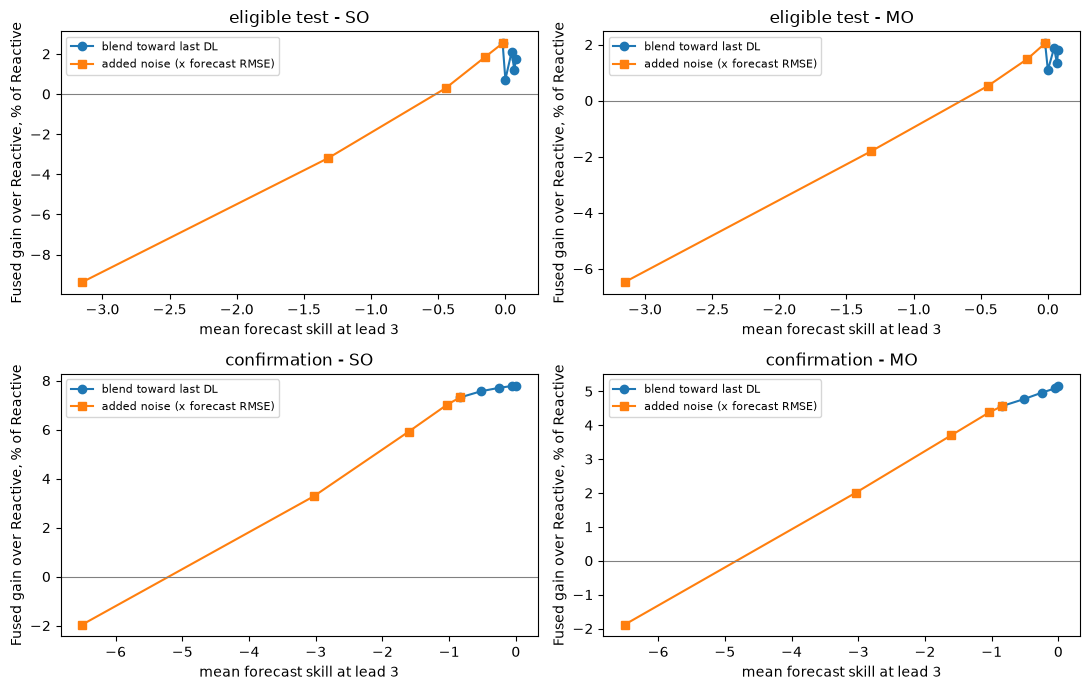

In [25]:
# Dose-response: feed the frozen Fused agents forecasts of controlled quality and measure how their gain changes.
from scipy.stats import wilcoxon, spearmanr
DEG_SCHEMES={"blend toward last DL":[1.0,.75,.5,.25,0.0],"added noise (x forecast RMSE)":[0.0,.5,1.0,2.0,4.0]}

def degraded_store(store,ids,scheme,level):
    out={}; L=ACTION_LAG
    for tid in ids:
        rec=dict(store[tid]); N,c,last,fc,y=lead_arrays(rec,L)
        if scheme.startswith("blend"): new=level*fc+(1-level)*last
        else:
            s=np.sqrt(np.mean((fc-y)**2)); rng=np.random.default_rng(sum(map(ord,tid))+int(level*100)); new=fc+level*s*rng.standard_normal(N)
        fh=rec["fh"].copy(); fh[:N,L]=new; rec["fh"]=fh; rec["_new"]=new; out[tid]=rec
    return out

def skill_of(new,last,y):
    den=np.sqrt(np.mean((last-y)**2)); return float(1-np.sqrt(np.mean((new-y)**2))/den) if den>1e-12 else np.nan

groups=(("eligible test",REC,ALL_TEST,RES[RES.ckpt==PRIMARY]),("confirmation",CREC,CONF_IDS,CRES))
AGENTS={}
def get_agent(obj,agent_id):
    if (obj,agent_id) not in AGENTS: AGENTS[(obj,agent_id)]=load_agent(CK[(obj,"Fused",agent_id)],"final")
    return AGENTS[(obj,agent_id)]
rows=[]; ref={}
for gname,store,ids,res in groups:
    for obj in ("SO","MO"):
        m=res[res.objective==obj].groupby(["trace_id","regime"]).dmbps.mean().unstack(); ref[(gname,obj)]=m.loc[ids]
        for scheme,levels in DEG_SCHEMES.items():
            for lev in levels:
                ds=degraded_store(store,ids,scheme,lev)
                sk={t:skill_of(ds[t]["_new"],lead_arrays(ds[t],ACTION_LAG)[2],lead_arrays(ds[t],ACTION_LAG)[4]) for t in ids}
                for seed in (RL_SEEDS if gname=="eligible test" else C_SEEDS):
                    for t in ids:
                        ag=get_agent(obj,sid(FOLD_OF[t],seed) if gname=="eligible test" else seed)
                        d,r,a=run_episode(t,obj,"Fused",lambda s:greedy_act(ag,s),ds)
                        rows.append({"group":gname,"objective":obj,"scheme":scheme,"level":lev,"seed":seed,"trace_id":t,"dmbps":d.mean(),"skill":sk[t]})
DR=pd.DataFrame(rows); DR.to_csv(CONF/"dose_response_long.csv",index=False)

# sanity: undegraded forecast must reproduce the stored Fused results
chk=[]
for gname,store,ids,res in groups:
    for obj in ("SO","MO"):
        a=DR[(DR.group==gname)&(DR.objective==obj)&(DR.scheme=="blend toward last DL")&(DR.level==1.0)].groupby("trace_id").dmbps.mean().loc[ids]
        chk.append(float(np.abs(a-ref[(gname,obj)]["Fused"]).max()))
print(f"Sanity check, undegraded forecast vs stored Fused results: max abs difference {max(chk):.2e} Mbps")

summ=[]
for (gname,obj,scheme,lev),g in DR.groupby(["group","objective","scheme","level"]):
    pt=g.groupby("trace_id").agg(f=("dmbps","mean"),sk=("skill","first")); r=ref[(gname,obj)]
    gain=pt.f-r.loc[pt.index,"Reactive"]
    g8=(pt.f-r.loc[pt.index,"ReactiveDup"]).mean() if "ReactiveDup" in r.columns else np.nan
    summ.append({"group":gname,"objective":obj,"scheme":scheme,"level":lev,"mean_skill":pt.sk.mean(),"fused_dMbps":pt.f.mean(),
                 "gain_vs_reactive":gain.mean(),"gain_%_of_reactive":100*(gain/r.loc[pt.index,"Reactive"].abs().clip(lower=1e-9)).mean(),
                 "gain_vs_shuffled_ref":(r["Fused"]-r["FusedShuffled"]).mean(),"gain_vs_reactive8":g8})
S=pd.DataFrame(summ); S.to_csv(CONF/"dose_response_summary.csv",index=False)
for gname in ("eligible test","confirmation"):
    print(f"\n=== {gname}: frozen Fused agents fed forecasts of controlled quality (mean over traces and seeds) ===")
    display(S[S.group==gname].drop(columns="group").round(3))

print("\nPaired check per trace: highest vs lowest forecast skill setting, gain vs Reactive (Mbps)")
for (gname,obj,scheme),g in S.groupby(["group","objective","scheme"]):
    gs=g.sort_values("mean_skill"); hi_l,lo_l=gs.level.iloc[-1],gs.level.iloc[0]
    d=DR[(DR.group==gname)&(DR.objective==obj)&(DR.scheme==scheme)]
    a=d[d.level==hi_l].groupby("trace_id").dmbps.mean(); b=d[d.level==lo_l].groupby("trace_id").dmbps.mean(); diff=(a-b)
    p=wilcoxon(diff).pvalue if np.any(diff!=0) and len(diff)>=5 else np.nan
    rho,pr=spearmanr(g.mean_skill,g.gain_vs_reactive)
    print(f"  {gname:14s} {obj} {scheme:30s} gain(highest-skill setting) - gain(lowest-skill setting) {diff.mean():+.3f} Mbps, better on {int((diff>0).sum())}/{len(diff)} traces, Wilcoxon p={p:.3f} | across levels Spearman(skill, gain) {rho:+.2f}")

try:
    import matplotlib.pyplot as plt
    fig,ax=plt.subplots(2,2,figsize=(11,7))
    for i,gname in enumerate(("eligible test","confirmation")):
        for j,obj in enumerate(("SO","MO")):
            for scheme,mk in zip(DEG_SCHEMES,("o","s")):
                g=S[(S.group==gname)&(S.objective==obj)&(S.scheme==scheme)].sort_values("mean_skill"); ax[i,j].plot(g.mean_skill,g["gain_%_of_reactive"],marker=mk,label=scheme)
            ax[i,j].axhline(0,color="grey",lw=.8)
            ax[i,j].set_title(f"{gname} - {obj}"); ax[i,j].set_xlabel(f"mean forecast skill at lead {ACTION_LAG}"); ax[i,j].set_ylabel("Fused gain over Reactive, % of Reactive"); ax[i,j].legend(fontsize=8)
    plt.tight_layout(); plt.show()
except Exception as e:
    print("plot skipped:",e)

## 5. Summary

In [26]:
print("=== Pipeline summary ===")
print("Selected models:",top4,"| weights",np.round(weights,3).tolist())
hs_=pd.read_csv(OUT/"horizon_skill_vs_persistence.csv").set_index("horizon")
print("Eligible-trace forecast skill vs persistence (RMSE / MAE), horizons 1, 3, 6, 10:")
display(hs_.loc[[1,3,6,10],["rmse_skill","mae_skill"]].round(3))
_r=json.load(open(RL_OUT/"rl_summary.json"))
print(f"\nRL testbed (lead {_r['cfg']['lag']}), 4-fold trace-level cross-validation (20 traces), {_r['primary_ckpt']} policy:")
for k,v in _r["summary"].items(): print(f"  {k}: diff {v['mean_diff']:+.3f} Mbps, CI [{v['ci95'][0]:+.3f}, {v['ci95'][1]:+.3f}], wins {v['wins']}/{v['n']}")
for k,v in {k:v for k,v in _r.get("twolevel",{}).items() if k!="per_fold"}.items(): print(f"  [traces x seeds] {k}: diff {v['mean_diff']:+.3f} Mbps, CI [{v['ci95'][0]:+.3f}, {v['ci95'][1]:+.3f}]")
for r_ in _r.get("twolevel",{}).get("per_fold",[]): print(f"  [fold {r_['fold']}] {r_['objective']}: Fused-Reactive8 {r_['Fused-Reactive8']:+.3f}, Fused-Reactive {r_['Fused-Reactive']:+.3f}")
_cf=CONF/"confirmation_summary.json"
if _cf.exists():
    print("\nHeld-out confirmation (trace-level):")
    for k,v in json.load(open(_cf)).items():
        print(f"  {k}: diff {v['mean_diff']:+.3f} Mbps, CI [{v['ci'][0]:+.3f}, {v['ci'][1]:+.3f}], wins {v['wins']}/{v['n']}; "
              +("INCONCLUSIVE (too few traces)" if not v.get("conclusive",False) else f"vs Reactive {'MET' if v['fused_gt_reactive_ci_excludes_0'] else 'NOT MET'}; vs shuffled {'MET' if v['fused_gt_shuffled_ci_excludes_0'] else 'NOT MET'}")+(f"; Fused vs Reactive-8 (pre-declared primary): CI {'above' if v['fused_gt_reactive8_ci_excludes_0'] else 'not above'} zero" if v.get("fused_gt_reactive8_ci_excludes_0") is not None else "")+(f" [traces x seeds CI {v['reactive8_twolevel_ci'][0]:+.3f}, {v['reactive8_twolevel_ci'][1]:+.3f}]" if v.get("reactive8_twolevel_ci") else ""))
else: print("\nConfirmation not run yet.")

=== Pipeline summary ===
Selected models: ['Transformer', 'Block RNN', 'Random Forest', 'LightGBM'] | weights [0.259, 0.253, 0.246, 0.242]
Eligible-trace forecast skill vs persistence (RMSE / MAE), horizons 1, 3, 6, 10:


,rmse_skill,mae_skill
horizon,,
1,0.040,-0.191
3,0.215,0.089
6,0.258,0.189
10,0.219,0.154



RL testbed (lead 3), 4-fold trace-level cross-validation (20 traces), final policy:
  SO_Fused_vs_Reactive: diff +0.589 Mbps, CI [+0.442, +0.867], wins 16/20
  SO_Fused_vs_Shuffled: diff +1.499 Mbps, CI [+1.352, +1.826], wins 16/20
  SO_Fused_vs_Reactive8: diff +1.568 Mbps, CI [+1.432, +1.839], wins 17/20
  SO_Reactive8_vs_Reactive: diff -0.979 Mbps, CI [-1.211, -0.758], wins 6/20
  MO_Fused_vs_Reactive: diff +0.632 Mbps, CI [+0.461, +0.761], wins 15/20
  MO_Fused_vs_Shuffled: diff +1.190 Mbps, CI [+1.036, +1.359], wins 15/20
  MO_Fused_vs_Reactive8: diff +1.560 Mbps, CI [+1.389, +1.747], wins 18/20
  MO_Reactive8_vs_Reactive: diff -0.928 Mbps, CI [-1.138, -0.774], wins 9/20
  [traces x seeds] SO_Fused_vs_Reactive: diff +0.589 Mbps, CI [-0.851, +1.447]
  [traces x seeds] SO_Fused_vs_ReactiveDup: diff +1.568 Mbps, CI [+0.303, +3.437]
  [traces x seeds] SO_Fused_vs_FusedShuffled: diff +1.499 Mbps, CI [-0.578, +4.704]
  [traces x seeds] MO_Fused_vs_Reactive: diff +0.632 Mbps, CI [+0.171,

## 6. Adaptivity test on synthetic changing environments

**Question.** Does the frozen, offline-trained policy select different and appropriate actions as the environment changes, and does forecast information improve that adaptation?

**Test set.** 100 synthetic traces (Good 34, Bad 33, Ugly 33; zero DL below 3%) generated from a documented, UCC-independent radio and load model (`synth_gen.py`, fixed seed, generator frozen before any evaluation). They are kept outside the UCC dataset folder so the 20-trace eligible set, the folds and the checkpoint hashes are untouched.

**Nothing is retrained or tuned.** The frozen ensemble forecaster produces the forecasts (each trace is normalised from its own first 80%, forecast on its last 20%); the 40 frozen agents per regime from section 3 (4 folds x 10 seeds) act on them. Every trace is evaluated by every agent once.

**Pre-declared analysis (fixed before the run).**
1. *Headline:* Fused vs Reactive-8 over all 100 traces, SO and MO separately, 95% interval resampling traces and agents together. SUPPORTED if both lower bounds are above zero; SUGGESTIVE if both point estimates are positive but an interval includes zero; otherwise NOT SUPPORTED. Fused vs Reactive and vs the shuffled-forecast control are reported alongside.
2. *Adaptivity evidence:* (a) does the best constant action differ across Good, Bad and Ugly; (b) do the agents' action mixes differ across tiers in the direction of the oracle's; (c) agreement with the oracle action compared with the best constant action; (d) behaviour around within-trace regime shifts (SNR level changes of at least 25% of the development range): does the agent change its action when the oracle action changes, and is the Fused gain larger just after a shift.
3. *Reporting:* results by tier and pooled; nothing is dropped after seeing results; the synthetic set is a controlled mechanism test with assumed action effects, not evidence about a real network.

In [27]:
# ---------------------------------------------------------------------------------------------
# 6.1 Load the synthetic traces and forecast them with the frozen ensemble (no refitting of anything).
# ---------------------------------------------------------------------------------------------
import re
SYN_DIR=Path("Synthetic_5G_100traces")      # keep this folder OUTSIDE 5G-production-dataset
SYN_OUT=OUT/"synthetic_test"; SYN_OUT.mkdir(exist_ok=True)
SYN_MIN_ALIGNED=60
assert SYN_DIR.exists(), f"{SYN_DIR} not found: unzip Synthetic_5G_100traces.zip next to the notebook"
assert SYN_DIR.resolve()!=DATA_FOLDER.resolve() and DATA_FOLDER.resolve() not in SYN_DIR.resolve().parents, "synthetic traces must not sit inside the UCC dataset folder"

if "models" not in globals():     # frozen models (loaded in section 4; reloaded here after a kernel restart)
    scaler=joblib.load(OUT/"feature_scaler.joblib"); models={}
    _cv=pd.read_csv(OUT/"cv_model_selection.csv"); top4=_cv.head(4).model.tolist()
    _w=1/_cv.head(4).cv_rmse_median.to_numpy(); weights=_w/_w.sum()
    for name in top4:
        safe=name.lower().replace(" ","_")
        if name in SEQ_MODELS:
            m=make_model(name,int(scaler.n_features_in_)); m.load_state_dict(torch.load(OUT/f"{safe}.pt")); m.eval()
        else: m=joblib.load(OUT/f"{safe}.joblib")
        models[name]=m
print("Frozen ensemble:",top4,"| weights",np.round(weights,3).tolist())

def syn_tier_of(tid):
    m=re.search(r"_(Good|Bad|Ugly)_",tid); return m.group(1) if m else "Other"

SREC={}; syn_manifest=[]
for tid,df in load_all(SYN_DIR):
    x=clean(df)
    if x is None or len(x)<=N_LAGS+HORIZON+20: continue
    d=final_data({"id":tid,"df":x,"zero_frac":float((x[TARGET].to_numpy()==0).mean())})
    if len(d["Yte"])-(SEQ_LEN-1)<SYN_MIN_ALIGNED: continue
    o=ensemble_forecast(d); off=o["off"]; n=len(o["actual"]); origins=d["origins"][off:off+n]
    cov_raw=d["df"].iloc[origins][COVARIATES].to_numpy(np.float64); cov=np.zeros_like(cov_raw); rngs=np.ones(len(COVARIATES))
    for j,c in enumerate(COVARIATES):
        lo,hi=d["p"][c]
        if hi>lo: cov[:,j]=(cov_raw[:,j]-lo)/(hi-lo); rngs[j]=hi-lo
    lo_dl,hi_dl=d["p"][TARGET]
    SREC[tid]=dict(y=o["y"][:,0].astype(np.float64),forecast=o["p"][:,0].astype(np.float64),fh=o["p"].astype(np.float64),
                   last=np.asarray(o["last"],dtype=np.float64),cov=cov,cov_raw=cov_raw,cov_rng=rngs,y_mbps=o["actual"][:,0].astype(np.float64),
                   lo=float(lo_dl),hi=float(hi_dl),zero_frac=float((x[TARGET]==0).mean()),
                   mobility="Static" if "Static" in tid else "Driving",tier=syn_tier_of(tid))
    assert len(SREC[tid]["y"])==len(SREC[tid]["forecast"])==len(cov)==len(SREC[tid]["fh"])>ACTION_LAG+STEPS,tid
    syn_manifest.append({"trace_id":tid,"tier":SREC[tid]["tier"],"mobility":SREC[tid]["mobility"],"aligned_steps":n,"zero_frac":SREC[tid]["zero_frac"],
                         "mean_dl_mbps":float(SREC[tid]["y_mbps"].mean()),"max_dl_mbps":float(SREC[tid]["y_mbps"].max())})
SYN_IDS=list(SREC); SYN_TIERS=[t for t in ("Good","Bad","Ugly") if any(SREC[i]["tier"]==t for i in SYN_IDS)]
assert not set(SYN_IDS)&{t["id"] for t in traces}, "synthetic traces must not overlap the eligible traces"
SM=pd.DataFrame(syn_manifest); SM.to_csv(SYN_OUT/"synthetic_manifest.csv",index=False)
print(f"Synthetic traces loaded: {len(SYN_IDS)} | "+" | ".join(f"{t} {sum(SREC[i]['tier']==t for i in SYN_IDS)}" for t in SYN_TIERS)
      +f" | static {sum(SREC[i]['mobility']=='Static' for i in SYN_IDS)}, driving {sum(SREC[i]['mobility']=='Driving' for i in SYN_IDS)}")
display(SM.groupby("tier").agg(traces=("trace_id","size"),aligned_median=("aligned_steps","median"),zero_max=("zero_frac","max"),
                               dl_mean_median=("mean_dl_mbps","median"),dl_max=("max_dl_mbps","max")).round(3))

# forecast skill against persistence at the decision lead, by tier
rows=[]
for t in SYN_IDS:
    N,c,last,fc,y=lead_arrays(SREC[t],ACTION_LAG); s=SREC[t]["hi"]-SREC[t]["lo"]
    ef=(fc-y)*s; ep=(last-y)*s
    rows.append({"tier":SREC[t]["tier"],"mae_fc":np.abs(ef).mean(),"mae_last":np.abs(ep).mean(),"rmse_fc":np.sqrt((ef**2).mean()),"rmse_last":np.sqrt((ep**2).mean())})
fk=pd.DataFrame(rows).groupby("tier").mean(); fk["mae_skill_%"]=100*(1-fk.mae_fc/fk.mae_last); fk["rmse_skill_%"]=100*(1-fk.rmse_fc/fk.rmse_last)
print(f"\nForecast skill vs last observed DL at lead {ACTION_LAG} (positive = forecast better), frozen ensemble:"); display(fk.round(3))

Frozen ensemble: ['Transformer', 'Block RNN', 'Random Forest', 'LightGBM'] | weights [0.259, 0.253, 0.246, 0.242]
Synthetic traces loaded: 100 | Good 34 | Bad 33 | Ugly 33 | static 38, driving 62


,traces,aligned_median,zero_max,dl_mean_median,dl_max
tier,,,,,
Bad,33,255.0,0.015,6.210,157.555
Good,34,270.0,0.005,149.737,499.967
Ugly,33,224.0,0.028,11.536,488.333



Forecast skill vs last observed DL at lead 3 (positive = forecast better), frozen ensemble:


,mae_fc,mae_last,rmse_fc,rmse_last,mae_skill_%,rmse_skill_%
tier,,,,,,
Bad,4.189,3.146,5.673,4.740,-33.143,-19.696
Good,70.661,20.918,77.271,29.911,-237.803,-158.338
Ugly,10.968,8.150,16.473,14.072,-34.580,-17.063


In [28]:
# ---------------------------------------------------------------------------------------------
# 6.2 Frozen agents act on every synthetic trace (evaluated once; nothing retrained or tuned).
# ---------------------------------------------------------------------------------------------
# Agents: taken from memory (CK, built by the training cell of this same run) when available; read from the saved checkpoints only after a kernel restart.
SYN_INMEM="CK" in globals() and len(CK)>0
if SYN_INMEM:
    SYN_TRAINED=CFG; SYN_TRAIN_HASH=CFG_HASH; SYN_SEEDS=list(RL_SEEDS); SYN_FOLD_HASH=dict(FOLD_HASH)
else:
    _sum=json.load(open(RL_OUT/"rl_summary.json")); SYN_TRAINED=_sum["cfg"]; SYN_TRAIN_HASH=_sum["cfg_hash"]; SYN_SEEDS=list(_sum["all_seeds"])
    SYN_FOLD_HASH={int(k):v for k,v in _sum["fold_hash"].items()}
assert int(SYN_TRAINED["lag"])==ACTION_LAG, f"ACTION_LAG is {ACTION_LAG} but the agents were trained with lead {SYN_TRAINED['lag']}"
SYN_AGENTS=[f"f{f}s{sd}" for f in range(N_FOLDS) for sd in SYN_SEEDS]; SYN_REGIMES=list(SYN_TRAINED["regimes"])
print(f"Agents: {'in memory (this run)' if SYN_INMEM else 'loaded from checkpoints'} | config {SYN_TRAIN_HASH} | {len(SYN_AGENTS)} per regime | regimes {SYN_REGIMES}")

SYN_FLAG=SYN_OUT/"synthetic_evaluated.json"
if SYN_FLAG.exists():
    _fl=json.load(open(SYN_FLAG)); _fl["evaluations"]=_fl.get("evaluations",1)+1; json.dump(_fl,open(SYN_FLAG,"w"))
    print(f"NOTE: the synthetic set was already evaluated at {_fl['time']} (evaluation #{_fl['evaluations']}). Do not change anything between evaluations.")
else:
    json.dump({"train_hash":SYN_TRAIN_HASH,"time":time.strftime("%Y-%m-%d %H:%M:%S"),"evaluations":1},open(SYN_FLAG,"w"))

def syn_load(objective,regime,agent_id):
    if SYN_INMEM: return load_agent(CK[(objective,regime,agent_id)],"final")
    fold=int(agent_id[1:agent_id.index("s")]); seed=int(agent_id[agent_id.index("s")+1:])
    z=torch.load(RL_OUT/f"fold{fold}"/f"rl_{objective}_{regime}_seed{seed}_{SYN_FOLD_HASH[fold]}.pt",weights_only=False)
    class _Shim: pass
    ag=_Shim(); ag.q=DQNNet(z["n_state"],z["n_action"]); ag.q.load_state_dict(z["final_state"]); ag.q.eval(); return ag

rows=[]; SYN_STEP={}; _t0=time.time(); _k=0
for obj in ("SO","MO"):
    for reg in SYN_REGIMES:
        for aid in SYN_AGENTS:
            ag=syn_load(obj,reg,aid)
            for tid in SYN_IDS:
                d,r,a=run_episode(tid,obj,reg,lambda s:greedy_act(ag,s),SREC)
                SYN_STEP[(obj,reg,aid,tid)]=(d.astype(np.float32),a.astype(np.int8))
                rows.append({"objective":obj,"regime":reg,"seed":aid,"trace_id":tid,"tier":SREC[tid]["tier"],"dmbps":float(d.mean()),"reward":float(r.mean())})
            _k+=1
        print(f"  {obj} {reg}: {len(SYN_AGENTS)} agents x {len(SYN_IDS)} traces done ({time.time()-_t0:.0f}s)",flush=True)
SYN=pd.DataFrame(rows); SYN.to_csv(SYN_OUT/"synthetic_rl_results_long.csv",index=False)
print("Episodes evaluated:",len(SYN))

Agents: in memory (this run) | config 8e80425230 | 40 per regime | regimes ['Reactive', 'Fused', 'FusedShuffled', 'ReactiveDup']
  SO Reactive: 40 agents x 100 traces done (18s)
  SO Fused: 40 agents x 100 traces done (36s)
  SO FusedShuffled: 40 agents x 100 traces done (54s)
  SO ReactiveDup: 40 agents x 100 traces done (72s)
  MO Reactive: 40 agents x 100 traces done (90s)
  MO Fused: 40 agents x 100 traces done (108s)
  MO FusedShuffled: 40 agents x 100 traces done (126s)
  MO ReactiveDup: 40 agents x 100 traces done (143s)
Episodes evaluated: 32000


In [29]:
# ---------------------------------------------------------------------------------------------
# 6.3 Pre-declared headline: Fused vs Reactive-8 (and vs Reactive, vs shuffled forecast), all traces and by tier.
# ---------------------------------------------------------------------------------------------
def syn_ci(x,n=5000,seed=0):
    rng=np.random.default_rng(seed); x=np.asarray(x,float); m=[x[rng.integers(0,len(x),len(x))].mean() for _ in range(n)]
    return float(np.percentile(m,2.5)),float(np.percentile(m,97.5))
def syn_wilcoxon(x):
    from scipy.stats import wilcoxon
    x=np.asarray(x,float); return float(wilcoxon(x).pvalue) if np.any(x!=0) else 1.0
def syn_mat(obj,regime):
    return SYN[(SYN.objective==obj)&(SYN.regime==regime)].pivot(index="trace_id",columns="seed",values="dmbps").loc[SYN_IDS]
def syn_two_level(A_df,B_df,n=5000,seed=0):
    A=A_df.to_numpy(float); B=B_df.loc[A_df.index].to_numpy(float); nt=A.shape[0]; rng=np.random.default_rng(seed); out=np.empty(n)
    for i in range(n):
        t=rng.integers(0,nt,nt); sa=rng.integers(0,A.shape[1],A.shape[1]); sb=rng.integers(0,B.shape[1],B.shape[1])
        out[i]=(B[np.ix_(t,sb)].mean(1)-A[np.ix_(t,sa)].mean(1)).mean()
    return float((B.mean(1)-A.mean(1)).mean()),float(np.percentile(out,2.5)),float(np.percentile(out,97.5))

def syn_pair(obj,a,b):
    A=syn_mat(obj,a); B=syn_mat(obj,b); diff=(B.mean(1)-A.mean(1))      # per-trace difference, b minus a
    pt,lo2,hi2=syn_two_level(A,B); lo,hi=syn_ci(diff)
    return diff,{"mean_diff":float(diff.mean()),"median_diff":float(diff.median()),"wins":int((diff>0).sum()),"n":len(diff),
                 "trace_ci":[lo,hi],"twolevel_ci":[lo2,hi2],"wilcoxon_p":syn_wilcoxon(diff)}

SYN_RESULT={}; SYN_DIFF={}
for obj in ("SO","MO"):
    print(f"\n=== {obj}: {len(SYN_IDS)} synthetic traces, {len(SYN_AGENTS)} frozen agents per regime ===")
    for name,(a,b) in {"Fused_vs_Reactive8":("ReactiveDup","Fused"),"Fused_vs_Reactive":("Reactive","Fused"),"Fused_vs_Shuffled":("FusedShuffled","Fused"),
                       "Reactive8_vs_Reactive":("Reactive","ReactiveDup")}.items():
        if a not in SYN_REGIMES or b not in SYN_REGIMES: continue
        diff,r=syn_pair(obj,a,b); SYN_RESULT[f"{obj}_{name}"]=r; SYN_DIFF[(obj,name)]=diff
        print(f"{name:24s} mean diff {r['mean_diff']:+.3f} Mbps | traces x agents 95% CI [{r['twolevel_ci'][0]:+.3f}, {r['twolevel_ci'][1]:+.3f}] | "
              f"trace-level CI [{r['trace_ci'][0]:+.3f}, {r['trace_ci'][1]:+.3f}] | wins {r['wins']}/{r['n']} | Wilcoxon p={r['wilcoxon_p']:.3g}")
    ps=SYN[SYN.objective==obj].pivot_table(index="seed",columns="regime",values="dmbps"); print("Per-agent mean dMbps over the synthetic traces (descriptive):"); display(ps.describe().loc[["mean","std","min","max"]].round(3))

print("\nBy tier (Fused - Reactive-8, mean over the tier's traces):")
rows=[]
for obj in ("SO","MO"):
    diff=SYN_DIFF[(obj,"Fused_vs_Reactive8")]
    for tier in SYN_TIERS:
        x=diff[[SREC[i]["tier"]==tier for i in diff.index]]; lo,hi=syn_ci(x)
        rows.append({"objective":obj,"tier":tier,"n":len(x),"mean_diff_Mbps":x.mean(),"ci_lo":lo,"ci_hi":hi,"wins":f"{int((x>0).sum())}/{len(x)}"})
display(pd.DataFrame(rows).round(3))

def syn_verdict(obj):
    r=SYN_RESULT[f"{obj}_Fused_vs_Reactive8"]; return r["twolevel_ci"][0]>0, r["mean_diff"]>0
v_so,v_mo=syn_verdict("SO"),syn_verdict("MO")
SYN_VERDICT="SUPPORTED" if v_so[0] and v_mo[0] else ("SUGGESTIVE" if v_so[1] and v_mo[1] else "NOT SUPPORTED")
print(f"\nPre-declared verdict (Fused vs Reactive-8, traces x agents interval, SO and MO): {SYN_VERDICT}")


=== SO: 100 synthetic traces, 40 frozen agents per regime ===
Fused_vs_Reactive8       mean diff -0.126 Mbps | traces x agents 95% CI [-0.742, +0.458] | trace-level CI [-0.484, +0.174] | wins 66/100 | Wilcoxon p=0.218
Fused_vs_Reactive        mean diff -0.241 Mbps | traces x agents 95% CI [-0.861, +0.307] | trace-level CI [-0.614, +0.048] | wins 68/100 | Wilcoxon p=0.142
Fused_vs_Shuffled        mean diff +0.078 Mbps | traces x agents 95% CI [-0.595, +0.845] | trace-level CI [-0.386, +0.593] | wins 61/100 | Wilcoxon p=0.564
Reactive8_vs_Reactive    mean diff -0.115 Mbps | traces x agents 95% CI [-0.708, +0.424] | trace-level CI [-0.249, -0.008] | wins 46/100 | Wilcoxon p=0.302
Per-agent mean dMbps over the synthetic traces (descriptive):


regime,Fused,FusedShuffled,Reactive,ReactiveDup
mean,21.943,21.865,22.185,22.070
std,0.984,1.333,1.132,1.204
min,19.657,18.243,19.510,19.548
max,23.789,23.638,23.682,24.136



=== MO: 100 synthetic traces, 40 frozen agents per regime ===
Fused_vs_Reactive8       mean diff -0.440 Mbps | traces x agents 95% CI [-1.083, +0.117] | trace-level CI [-0.905, -0.078] | wins 58/100 | Wilcoxon p=0.582
Fused_vs_Reactive        mean diff -0.196 Mbps | traces x agents 95% CI [-0.747, +0.348] | trace-level CI [-0.506, +0.057] | wins 61/100 | Wilcoxon p=0.368
Fused_vs_Shuffled        mean diff -0.198 Mbps | traces x agents 95% CI [-0.949, +0.546] | trace-level CI [-0.744, +0.304] | wins 61/100 | Wilcoxon p=0.682
Reactive8_vs_Reactive    mean diff +0.244 Mbps | traces x agents 95% CI [-0.300, +0.820] | trace-level CI [+0.097, +0.430] | wins 49/100 | Wilcoxon p=0.348
Per-agent mean dMbps over the synthetic traces (descriptive):


regime,Fused,FusedShuffled,Reactive,ReactiveDup
mean,20.727,20.925,20.923,21.167
std,0.788,1.334,1.166,1.057
min,19.082,17.802,18.001,18.594
max,22.713,23.476,22.725,23.147



By tier (Fused - Reactive-8, mean over the tier's traces):


,objective,tier,n,mean_diff_Mbps,ci_lo,ci_hi,wins
0,SO,Good,34,-0.446,-1.459,0.432,17/34
1,SO,Bad,33,0.061,-0.014,0.140,26/33
2,SO,Ugly,33,0.016,-0.103,0.128,23/33
3,MO,Good,34,-1.343,-2.591,-0.364,11/34
4,MO,Bad,33,0.074,-0.006,0.159,25/33
5,MO,Ugly,33,-0.024,-0.253,0.166,22/33



Pre-declared verdict (Fused vs Reactive-8, traces x agents interval, SO and MO): NOT SUPPORTED


Environments:


,traces,DL_median,DL_p95,zero_%
tier,,,,
Good,34,136.60,406.79,0.25
Bad,33,3.97,30.86,0.81
Ugly,33,8.16,96.13,1.86



=== SO: share of steps where each action is optimal (oracle), by environment ===


,Good,Bad,Ugly
Increase_TX_power,0.125,0.224,0.189
Adjust_beamforming,0.081,0.376,0.314
Optimise_MCS,0.549,0.131,0.144
Reduce_interference,0.139,0.076,0.062
Increase_bandwidth,0.002,0.018,0.004
Load_balance,0.104,0.175,0.287


SO: mean dMbps/step by environment (best_const = dMbps of the best constant action). 'gap_closed' = (agent - best constant action) / (oracle - best constant action)


,best_const_action,best_const,global_const_in_tier,greedy_last_DL,greedy_forecast,oracle,Reactive,ReactiveDup,Fused,FusedShuffled,ReactiveDup_gap_closed,Fused_gap_closed
tier,,,,,,,,,,,,
Good,Optimise_MCS,41.507,18.147,50.468,43.747,51.084,39.177,38.820,38.373,38.203,-0.281,-0.327
Bad,Adjust_beamforming,6.099,6.099,7.865,7.861,7.953,7.527,7.544,7.606,7.592,0.779,0.812
Ugly,Adjust_beamforming,13.919,13.919,20.192,20.100,20.561,19.335,19.337,19.353,19.304,0.816,0.818


Best constant action differs across environments: YES (Good: Optimise_MCS, Bad: Adjust_beamforming, Ugly: Adjust_beamforming)
Global best constant action: Adjust_beamforming | loss from using it in each tier vs that tier's best constant: Good -23.360, Bad +0.000, Ugly +0.000

=== MO: share of steps where each action is optimal (oracle), by environment ===


,Good,Bad,Ugly
Increase_TX_power,0.008,0.143,0.134
Adjust_beamforming,0.037,0.366,0.329
Optimise_MCS,0.310,0.112,0.134
Reduce_interference,0.645,0.183,0.111
Increase_bandwidth,0.000,0.012,0.003
Load_balance,0.000,0.184,0.290


MO: mean dMbps/step by environment (best_const = dMbps of the best constant action). 'gap_closed' = (agent - best constant action) / (oracle - best constant action)


,best_const_action,best_const,global_const_in_tier,greedy_last_DL,greedy_forecast,oracle,Reactive,ReactiveDup,Fused,FusedShuffled,ReactiveDup_gap_closed,Fused_gap_closed
tier,,,,,,,,,,,,
Good,Reduce_interference,22.447,22.447,44.930,27.130,45.338,36.173,36.843,35.500,36.206,0.629,0.570
Bad,Reduce_interference,4.876,4.876,7.781,7.727,7.872,7.293,7.284,7.358,7.332,0.804,0.828
Ugly,Reduce_interference,12.346,12.346,20.092,19.863,20.461,18.841,18.899,18.875,18.774,0.808,0.805


Best constant action differs across environments: NO (one constant action is best everywhere: Reduce_interference)
Global best constant action: Reduce_interference | loss from using it in each tier vs that tier's best constant: Good +0.000, Bad +0.000, Ugly +0.000


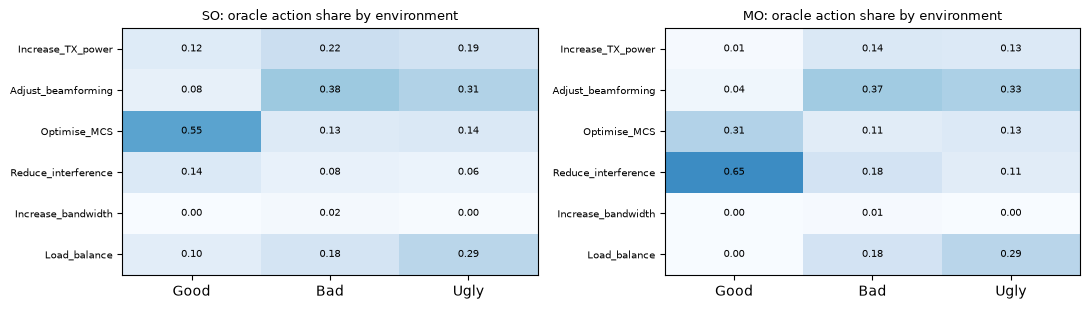

In [30]:
# ---------------------------------------------------------------------------------------------
# 6.4 Adaptivity evidence (a): does the best action depend on the environment, and how close do the agents get?
# 'Best constant action' = the single fixed action with the highest mean reward in that set of traces (reward is what the agents optimise); dMbps columns are its throughput gain.
# ---------------------------------------------------------------------------------------------
def syn_tier_ids(t): return [i for i in SYN_IDS if SREC[i]["tier"]==t]
def syn_oracle_actions(tid,obj):
    N,c,last,fc,y_land=lead_arrays(SREC[tid],ACTION_LAG)
    return reward_components(dl_effect(c,y_land),SREC[tid]["cov_rng"],obj).sum(2).argmax(1)

SYN_ORACLE={(obj,t):syn_oracle_actions(t,obj) for obj in ("SO","MO") for t in SYN_IDS}
SYN_ADAPT={}
env_rows=[]
for tier in SYN_TIERS:
    ids=syn_tier_ids(tier); ym=np.concatenate([SREC[i]["y_mbps"] for i in ids])
    env_rows.append({"tier":tier,"traces":len(ids),"DL_median":np.median(ym),"DL_p95":np.percentile(ym,95),"zero_%":100*np.mean([SREC[i]["zero_frac"] for i in ids])})
print("Environments:"); display(pd.DataFrame(env_rows).set_index("tier").round(2))

import matplotlib.pyplot as plt
fig,axs=plt.subplots(1,2,figsize=(11,3.2))
for k,obj in enumerate(("SO","MO")):
    ft_all=fixed_policy_table(SYN_IDS,obj,store=SREC); g_best=ft_all.reward.idxmax()      # best constant action = highest mean reward (the objective the agents optimise)
    share=pd.DataFrame({tier:np.bincount(np.concatenate([SYN_ORACLE[(obj,i)] for i in syn_tier_ids(tier)]),minlength=NA)/sum(len(SYN_ORACLE[(obj,i)]) for i in syn_tier_ids(tier)) for tier in SYN_TIERS},index=ACTIONS)
    SYN_ADAPT[f"{obj}_oracle_share"]=share
    print(f"\n=== {obj}: share of steps where each action is optimal (oracle), by environment ==="); display(share.round(3))
    rows=[]
    for tier in SYN_TIERS:
        ids=syn_tier_ids(tier); ft=fixed_policy_table(ids,obj,store=SREC); ib=info_benchmarks(ids,obj,store=SREC).mean()
        bc=ft.reward.idxmax(); row={"tier":tier,"best_const_action":bc,"best_const":ft.loc[bc,"dMbps"],"global_const_in_tier":ft.loc[g_best,"dMbps"],
             "greedy_last_DL":ib.prev_dl_greedy,"greedy_forecast":ib.forecast_greedy,"oracle":ib.oracle}
        for reg in ("Reactive","ReactiveDup","Fused","FusedShuffled"):
            if reg in SYN_REGIMES: row[reg]=SYN[(SYN.objective==obj)&(SYN.regime==reg)&(SYN.trace_id.isin(ids))].dmbps.mean()
        gap=row["oracle"]-row["best_const"]
        for reg in ("ReactiveDup","Fused"):
            if reg in row: row[f"{reg}_gap_closed"]=(row[reg]-row["best_const"])/gap if gap>1e-9 else np.nan
        rows.append(row)
    T=pd.DataFrame(rows).set_index("tier"); SYN_ADAPT[f"{obj}_table"]=T
    print(f"{obj}: mean dMbps/step by environment (best_const = dMbps of the best constant action). 'gap_closed' = (agent - best constant action) / (oracle - best constant action)"); display(T.round(3))
    differs=T.best_const_action.nunique()>1
    print(f"Best constant action differs across environments: {'YES ('+', '.join(f'{t}: {a}' for t,a in T.best_const_action.items())+')' if differs else 'NO (one constant action is best everywhere: '+T.best_const_action.iloc[0]+')'}")
    print(f"Global best constant action: {g_best} | loss from using it in each tier vs that tier's best constant: "+", ".join(f"{t} {T.loc[t,'global_const_in_tier']-T.loc[t,'best_const']:+.3f}" for t in SYN_TIERS))
    ax=axs[k]; im=ax.imshow(share.values,aspect="auto",cmap="Blues",vmin=0,vmax=1); ax.set_xticks(range(len(SYN_TIERS)),SYN_TIERS); ax.set_yticks(range(NA),ACTIONS,fontsize=7); ax.set_title(f"{obj}: oracle action share by environment",fontsize=9)
    for i in range(NA):
        for j in range(len(SYN_TIERS)): ax.text(j,i,f"{share.values[i,j]:.2f}",ha="center",va="center",fontsize=7)
plt.tight_layout(); plt.savefig(SYN_OUT/"oracle_action_share_by_environment.png",dpi=130); plt.show()


=== SO: total-variation distance between environments' action mixes (0 = identical mix, 1 = disjoint) ===


,TVD Good-Bad,TVD Good-Ugly,TVD Bad-Ugly
policy,,,
Oracle,0.482,0.483,0.125
Reactive,0.297,0.282,0.111
ReactiveDup,0.299,0.290,0.106
Fused,0.317,0.286,0.109


SO: share of steps where the action equals the oracle action (higher = better; compare with the best constant action):


,best_constant_agreement,Reactive_agreement,ReactiveDup_agreement,Fused_agreement
tier,,,,
Good,0.549,0.561,0.559,0.551
Bad,0.376,0.756,0.760,0.776
Ugly,0.314,0.777,0.777,0.786



=== MO: total-variation distance between environments' action mixes (0 = identical mix, 1 = disjoint) ===


,TVD Good-Bad,TVD Good-Ugly,TVD Bad-Ugly
policy,,,
Oracle,0.660,0.710,0.128
Reactive,0.280,0.329,0.090
ReactiveDup,0.275,0.335,0.098
Fused,0.289,0.339,0.096


MO: share of steps where the action equals the oracle action (higher = better; compare with the best constant action):


,best_constant_agreement,Reactive_agreement,ReactiveDup_agreement,Fused_agreement
tier,,,,
Good,0.645,0.487,0.487,0.476
Bad,0.183,0.681,0.672,0.688
Ugly,0.111,0.717,0.715,0.730


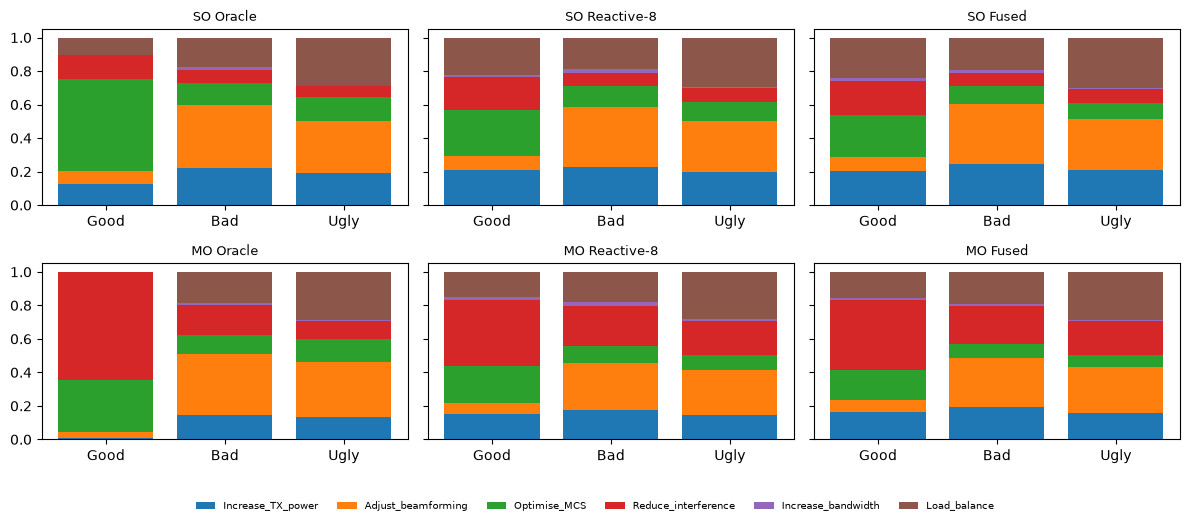

In [31]:
# ---------------------------------------------------------------------------------------------
# 6.5 Adaptivity evidence (b, c): do the agents' action mixes move with the environment, and how often do they pick the oracle action?
# ---------------------------------------------------------------------------------------------
def syn_mix(obj,reg,ids):
    return np.mean([np.bincount(SYN_STEP[(obj,reg,aid,t)][1],minlength=NA)/len(SYN_STEP[(obj,reg,aid,t)][1]) for aid in SYN_AGENTS for t in ids],0)
def tvd(p,q): return 0.5*float(np.abs(np.asarray(p)-np.asarray(q)).sum())

pairs=[(a,b) for i,a in enumerate(SYN_TIERS) for b in SYN_TIERS[i+1:]]
fig,axs=plt.subplots(2,3,figsize=(12,5.2),sharey=True); SYN_ADAPT["mix"]={}; SYN_ADAPT["agreement"]={}
for k,obj in enumerate(("SO","MO")):
    rows=[]; mixes={"Oracle":{t:np.bincount(np.concatenate([SYN_ORACLE[(obj,i)] for i in syn_tier_ids(t)]),minlength=NA)/sum(len(SYN_ORACLE[(obj,i)]) for i in syn_tier_ids(t)) for t in SYN_TIERS}}
    for reg in ("Reactive","ReactiveDup","Fused"):
        if reg in SYN_REGIMES: mixes[reg]={t:syn_mix(obj,reg,syn_tier_ids(t)) for t in SYN_TIERS}
    SYN_ADAPT["mix"][obj]=mixes
    for name,mx in mixes.items():
        row={"policy":name}
        for a,b in pairs: row[f"TVD {a}-{b}"]=tvd(mx[a],mx[b])
        rows.append(row)
    print(f"\n=== {obj}: total-variation distance between environments' action mixes (0 = identical mix, 1 = disjoint) ===")
    display(pd.DataFrame(rows).set_index("policy").round(3))
    # agreement with the oracle action, against the best constant action
    ft_all=fixed_policy_table(SYN_IDS,obj,store=SREC); rows=[]
    for tier in SYN_TIERS:
        ids=syn_tier_ids(tier); ft=fixed_policy_table(ids,obj,store=SREC); ca=ACTIONS.index(ft.reward.idxmax())
        orc=np.concatenate([SYN_ORACLE[(obj,i)] for i in ids]); row={"tier":tier,"best_constant_agreement":float(np.mean(orc==ca))}
        for reg in ("Reactive","ReactiveDup","Fused"):
            if reg in SYN_REGIMES:
                row[f"{reg}_agreement"]=float(np.mean([np.mean(SYN_STEP[(obj,reg,aid,t)][1]==SYN_ORACLE[(obj,t)]) for aid in SYN_AGENTS for t in ids]))
        rows.append(row)
    AG=pd.DataFrame(rows).set_index("tier"); SYN_ADAPT["agreement"][obj]=AG
    print(f"{obj}: share of steps where the action equals the oracle action (higher = better; compare with the best constant action):"); display(AG.round(3))
    for j,(name) in enumerate(("Oracle","ReactiveDup","Fused")):
        if name not in mixes: continue
        bottom=np.zeros(len(SYN_TIERS)); ax=axs[k,j]
        for ai,an in enumerate(ACTIONS):
            vals=np.array([mixes[name][t][ai] for t in SYN_TIERS]); ax.bar(SYN_TIERS,vals,bottom=bottom,label=an if (k==0 and j==0) else None); bottom+=vals
        ax.set_title(f"{obj} {'Reactive-8' if name=='ReactiveDup' else name}",fontsize=9)
h_,l_=axs[0,0].get_legend_handles_labels(); fig.legend(h_,l_,loc="lower center",ncol=NA,fontsize=7,frameon=False)
plt.tight_layout(rect=(0,0.07,1,1)); plt.savefig(SYN_OUT/"action_mix_by_environment.png",dpi=130); plt.show()

In [32]:
# ---------------------------------------------------------------------------------------------
# 6.6 Adaptivity evidence (d): behaviour around within-trace regime shifts.
# A shift = the SNR level (mean of 10 steps after vs 10 steps before, normalised to the trace's development range) changes by >= SYN_SHIFT_THR.
# ---------------------------------------------------------------------------------------------
SYN_SHIFT_THR=0.25; SYN_WIN=20; SYN_PRE=10
def syn_shifts(tid):
    s=SREC[tid]["cov"][:,COV_IDX["SNR"]]; N=len(SREC[tid]["y"])-ACTION_LAG; ev=[]; t=SYN_PRE
    while t<N-SYN_WIN:
        if abs(s[t:t+SYN_PRE].mean()-s[t-SYN_PRE:t].mean())>=SYN_SHIFT_THR: ev.append(t); t+=SYN_WIN
        else: t+=1
    return ev
SYN_EV={t:syn_shifts(t) for t in SYN_IDS}
n_ev=sum(len(v) for v in SYN_EV.values())
print(f"Regime shifts found: {n_ev} in {sum(1 for v in SYN_EV.values() if v)}/{len(SYN_IDS)} traces | by tier: "+", ".join(f"{t} {sum(len(SYN_EV[i]) for i in syn_tier_ids(t))}" for t in SYN_TIERS))
mode=lambda a:int(np.bincount(a,minlength=NA).argmax())

SYN_SHIFT={}
for obj in ("SO","MO"):
    print(f"\n=== {obj}: around regime shifts ===")
    # gain of Fused over Reactive-8 inside the post-shift window vs elsewhere (per-trace means, traces with at least one shift)
    rows=[]
    for tid in SYN_IDS:
        if not SYN_EV[tid]: continue
        N=len(SYN_ORACLE[(obj,tid)]); post=np.zeros(N,bool)
        for t0 in SYN_EV[tid]: post[t0:t0+SYN_WIN]=True
        gF=np.mean([SYN_STEP[(obj,"Fused",aid,tid)][0] for aid in SYN_AGENTS],0); gR=np.mean([SYN_STEP[(obj,"ReactiveDup",aid,tid)][0] for aid in SYN_AGENTS],0)
        rows.append({"trace_id":tid,"tier":SREC[tid]["tier"],"gain_post_shift":float((gF-gR)[post].mean()),"gain_elsewhere":float((gF-gR)[~post].mean()) if (~post).any() else np.nan})
    G=pd.DataFrame(rows).dropna(); G["post_minus_elsewhere"]=G.gain_post_shift-G.gain_elsewhere
    lo,hi=syn_ci(G.post_minus_elsewhere)
    print(f"Fused - Reactive-8 gain (Mbps/step): within {SYN_WIN} steps after a shift {G.gain_post_shift.mean():+.3f} vs elsewhere {G.gain_elsewhere.mean():+.3f} | difference {G.post_minus_elsewhere.mean():+.3f}, trace-level 95% CI [{lo:+.3f}, {hi:+.3f}] ({len(G)} traces)")
    display(G.groupby("tier")[["gain_post_shift","gain_elsewhere","post_minus_elsewhere"]].mean().round(3))
    # does the agent change its dominant action when the oracle's dominant action changes?
    rows=[]
    for reg in ("Reactive","ReactiveDup","Fused"):
        if reg not in SYN_REGIMES: continue
        oc=ac=ac_right=nc=nc_ac=0
        for tid in SYN_IDS:
            orc=SYN_ORACLE[(obj,tid)]
            for t0 in SYN_EV[tid]:
                o_pre,o_post=mode(orc[t0-SYN_PRE:t0]),mode(orc[t0:t0+SYN_PRE]); oracle_changes=o_pre!=o_post
                for aid in SYN_AGENTS:
                    a=SYN_STEP[(obj,reg,aid,tid)][1]; a_pre,a_post=mode(a[t0-SYN_PRE:t0]),mode(a[t0:t0+SYN_PRE]); ch=a_pre!=a_post
                    if oracle_changes: oc+=1; ac+=ch; ac_right+=(a_post==o_post)
                    else: nc+=1; nc_ac+=ch
        rows.append({"policy":"Reactive-8" if reg=="ReactiveDup" else reg,"P(agent changes | oracle changes)":ac/max(oc,1),"P(moves to oracle's new action | oracle changes)":ac_right/max(oc,1),
                     "P(agent changes | oracle does not)":nc_ac/max(nc,1),"shift-agent pairs (oracle changes / not)":f"{oc} / {nc}"})
    R=pd.DataFrame(rows).set_index("policy"); SYN_SHIFT[obj]={"gain_table":G,"adaptation":R}
    print(f"{obj}: adaptation at shifts (a policy that adapts changes when the oracle changes and stays when it does not):"); display(R.round(3))

Regime shifts found: 97 in 53/100 traces | by tier: Good 16, Bad 35, Ugly 46

=== SO: around regime shifts ===
Fused - Reactive-8 gain (Mbps/step): within 20 steps after a shift -0.607 vs elsewhere -0.386 | difference -0.221, trace-level 95% CI [-0.712, +0.153] (53 traces)


,gain_post_shift,gain_elsewhere,post_minus_elsewhere
tier,,,
Bad,0.043,0.016,0.028
Good,-2.250,-1.807,-0.442
Ugly,-0.247,0.039,-0.287


SO: adaptation at shifts (a policy that adapts changes when the oracle changes and stays when it does not):


,P(agent changes | oracle changes),P(moves to oracle's new action | oracle changes),P(agent changes | oracle does not),shift-agent pairs (oracle changes / not)
policy,,,,
Reactive,0.742,0.769,0.364,2200 / 1680
Reactive-8,0.735,0.747,0.367,2200 / 1680
Fused,0.720,0.765,0.370,2200 / 1680



=== MO: around regime shifts ===
Fused - Reactive-8 gain (Mbps/step): within 20 steps after a shift -0.751 vs elsewhere -0.699 | difference -0.051, trace-level 95% CI [-0.652, +0.397] (53 traces)


,gain_post_shift,gain_elsewhere,post_minus_elsewhere
tier,,,
Bad,0.050,0.028,0.021
Good,-2.439,-3.190,0.751
Ugly,-0.473,0.031,-0.504


MO: adaptation at shifts (a policy that adapts changes when the oracle changes and stays when it does not):


,P(agent changes | oracle changes),P(moves to oracle's new action | oracle changes),P(agent changes | oracle does not),shift-agent pairs (oracle changes / not)
policy,,,,
Reactive,0.716,0.642,0.383,2640 / 1240
Reactive-8,0.714,0.647,0.376,2640 / 1240
Fused,0.694,0.648,0.402,2640 / 1240


In [33]:
# ---------------------------------------------------------------------------------------------
# 6.7 Summary of the synthetic adaptivity test (saved with the other artifacts).
# ---------------------------------------------------------------------------------------------
print("=== Synthetic adaptivity test: summary ===")
print(f"{len(SYN_IDS)} synthetic traces ({', '.join(f'{t} {len(syn_tier_ids(t))}' for t in SYN_TIERS)}); frozen forecaster and {len(SYN_AGENTS)} frozen agents per regime; generator frozen before evaluation.")
for obj in ("SO","MO"):
    r=SYN_RESULT[f"{obj}_Fused_vs_Reactive8"]
    print(f"{obj}: Fused - Reactive-8 {r['mean_diff']:+.3f} Mbps/step, 95% CI [{r['twolevel_ci'][0]:+.3f}, {r['twolevel_ci'][1]:+.3f}] (traces x agents), wins {r['wins']}/{r['n']} traces")
    T=SYN_ADAPT[f"{obj}_table"]
    print(f"    best constant action by environment: "+", ".join(f"{t} = {a}" for t,a in T.best_const_action.items())+" | Fused closes "+", ".join(f"{t} {T.loc[t,'Fused_gap_closed']:.0%}" for t in SYN_TIERS)+" of the oracle gap above the best constant")
print(f"Pre-declared verdict: {SYN_VERDICT}")
json.dump({"n_traces":len(SYN_IDS),"tiers":{t:len(syn_tier_ids(t)) for t in SYN_TIERS},"n_agents":len(SYN_AGENTS),"verdict":SYN_VERDICT,"results":SYN_RESULT,
           "n_shifts":int(n_ev),"shift_threshold":SYN_SHIFT_THR,"window":SYN_WIN},open(SYN_OUT/"synthetic_summary.json","w"),indent=2,default=str)
print("Saved to",SYN_OUT.resolve())

=== Synthetic adaptivity test: summary ===
100 synthetic traces (Good 34, Bad 33, Ugly 33); frozen forecaster and 40 frozen agents per regime; generator frozen before evaluation.
SO: Fused - Reactive-8 -0.126 Mbps/step, 95% CI [-0.742, +0.458] (traces x agents), wins 66/100 traces
    best constant action by environment: Good = Optimise_MCS, Bad = Adjust_beamforming, Ugly = Adjust_beamforming | Fused closes Good -33%, Bad 81%, Ugly 82% of the oracle gap above the best constant
MO: Fused - Reactive-8 -0.440 Mbps/step, 95% CI [-1.083, +0.117] (traces x agents), wins 58/100 traces
    best constant action by environment: Good = Reduce_interference, Bad = Reduce_interference, Ugly = Reduce_interference | Fused closes Good 57%, Bad 83%, Ugly 80% of the oracle gap above the best constant
Pre-declared verdict: NOT SUPPORTED
Saved to part3_cv4_run1_artifacts/synthetic_test


In [34]:
# ---------------------------------------------------------------------------------------------
# 6.7b Same results split by mobility (Static / Driving) within each environment tier. Descriptive: cells hold few traces.
# ---------------------------------------------------------------------------------------------
SYN_MOB=["Static","Driving"]
def syn_ids_tm(t,m): return [i for i in SYN_IDS if SREC[i]["tier"]==t and SREC[i]["mobility"]==m]
print("Traces per tier x mobility:"); display(pd.crosstab(SM.tier,SM.mobility))
rows=[]
for obj in ("SO","MO"):
    diff=SYN_DIFF[(obj,"Fused_vs_Reactive8")]; ft_all=fixed_policy_table(SYN_IDS,obj,store=SREC)
    for tier in SYN_TIERS:
        for mob in SYN_MOB:
            ids=syn_ids_tm(tier,mob)
            if len(ids)<2: continue
            x=diff.loc[ids]; lo,hi=syn_ci(x); ft=fixed_policy_table(ids,obj,store=SREC); ib=info_benchmarks(ids,obj,store=SREC).mean()
            orc=np.concatenate([SYN_ORACLE[(obj,i)] for i in ids]); top=int(np.bincount(orc,minlength=NA).argmax())
            ag=lambda reg:float(np.mean([np.mean(SYN_STEP[(obj,reg,aid,t)][1]==SYN_ORACLE[(obj,t)]) for aid in SYN_AGENTS for t in ids]))
            rows.append({"objective":obj,"tier":tier,"mobility":mob,"n":len(ids),"DL_median":float(np.median(np.concatenate([SREC[i]["y_mbps"] for i in ids]))),
                         "Fused-Reactive8":x.mean(),"ci_lo":lo,"ci_hi":hi,"wins":f"{int((x>0).sum())}/{len(x)}",
                         "best_const_action":ft.reward.idxmax(),"oracle_top_action":ACTIONS[top],"oracle_top_share":float(np.mean(orc==top)),
                         "Reactive8_agree":ag("ReactiveDup"),"Fused_agree":ag("Fused"),"oracle_dMbps":ib.oracle})
SYN_MOBTAB=pd.DataFrame(rows); SYN_MOBTAB.to_csv(SYN_OUT/"synthetic_by_tier_and_mobility.csv",index=False)
display(SYN_MOBTAB.round(3))


Traces per tier x mobility:


mobility,Driving,Static
tier,,
Bad,21,12
Good,21,13
Ugly,20,13


,objective,tier,mobility,n,DL_median,Fused-Reactive8,ci_lo,ci_hi,wins,best_const_action,oracle_top_action,oracle_top_share,Reactive8_agree,Fused_agree,oracle_dMbps
0,SO,Good,Static,13,149.389,0.015,-1.245,1.158,8/13,Optimise_MCS,Optimise_MCS,0.676,0.521,0.521,54.605
1,SO,Good,Driving,21,125.960,-0.731,-2.200,0.401,9/21,Optimise_MCS,Optimise_MCS,0.463,0.583,0.570,48.904
2,SO,Bad,Static,12,3.904,-0.041,-0.124,0.018,9/12,Adjust_beamforming,Adjust_beamforming,0.343,0.776,0.781,5.378
3,SO,Bad,Driving,21,3.994,0.120,0.022,0.226,17/21,Adjust_beamforming,Adjust_beamforming,0.393,0.750,0.772,9.425
4,SO,Ugly,Static,13,7.048,0.018,-0.174,0.156,10/13,Adjust_beamforming,Adjust_beamforming,0.369,0.817,0.833,23.735
5,SO,Ugly,Driving,20,8.803,0.014,-0.142,0.168,13/20,Load_balance,Adjust_beamforming,0.277,0.751,0.756,18.497
6,MO,Good,Static,13,149.389,-1.030,-2.328,0.238,3/13,Reduce_interference,Reduce_interference,0.510,0.517,0.508,49.836
7,MO,Good,Driving,21,125.960,-1.537,-3.429,-0.278,8/21,Reduce_interference,Reduce_interference,0.736,0.469,0.456,42.553
8,MO,Bad,Static,12,3.904,-0.018,-0.091,0.039,9/12,Reduce_interference,Adjust_beamforming,0.308,0.708,0.724,5.333
9,MO,Bad,Driving,21,3.994,0.127,0.015,0.246,16/21,Adjust_beamforming,Adjust_beamforming,0.396,0.651,0.668,9.324


## 7. Experiment B: in-domain forecaster on the synthetic traces

**Why.** In section 6 the frozen UCC-trained forecaster had *negative* skill against last observed DL on every synthetic tier (6.1), so section 6 could not test whether forecast-informed control helps; it tested transfer of a forecaster. Experiment B removes that confound: the same ensemble recipe is **refitted on each synthetic trace's own first 80%** and forecasts that trace's last 20%.

**Status.** Experiment B was designed *after* the section 6 results were seen. It is a diagnostic that changes one thing, the forecaster; it does not replace or re-score the pre-declared section 6 verdict, and both are reported.

**What is identical to section 6.** The same 100 traces, the same 80/20 split and per-trace dev-only normalisation, the same decision lead (3), the same environment and rewards, the same 40 frozen agents per regime (trained on UCC only, never retrained or tuned on synthetic data). Reactive and Reactive-8 do not use the forecast, so their section 6 results are reused unchanged (alignment is asserted). Only Fused and the shuffled-forecast control are re-run.

**What changes.** The forecast slot now holds a forecast from a model fitted on that trace's own development portion: same four model types, same hyperparameters, same ensemble weights as the UCC ensemble (no model selection on synthetic data). The agents were trained on UCC forecasts, so they still see a forecast distribution they were not trained on; that is part of the test.

**Analysis (fixed before the run).**
1. *Skill check:* forecast skill against last observed DL at lead 3, by tier. If skill is still not positive, the experiment cannot test forecast-informed control and the result is reported as such.
2. *Headline:* Fused vs Reactive-8, traces x agents 95% interval, SO and MO, same SUPPORTED / SUGGESTIVE / NOT SUPPORTED rule; Fused vs shuffled and vs Reactive alongside; by tier.
3. *Dose-response across traces:* Spearman correlation between a trace's forecast skill and its Fused gain (over Reactive-8 and over the shuffled control), pooled and by tier.

In [35]:
# ---------------------------------------------------------------------------------------------
# 7.1 Refit the forecaster on each synthetic trace's own development portion (first 80%) and forecast its last 20%.
# Same model types, hyperparameters and ensemble weights as the UCC ensemble; nothing selected on synthetic data.
# ---------------------------------------------------------------------------------------------
SYNB_FILE=SYN_OUT/"refit_forecasts.npz"
SYNB_CACHE=dict(np.load(SYNB_FILE)) if SYNB_FILE.exists() else {}
print(f"Refit forecasts found in cache for {len(SYNB_CACHE)} traces" if SYNB_CACHE else "No cache: refitting from scratch")

def synb_refit(d):
    sc=StandardScaler().fit(d["Xtr"]); Xs=sc.transform(d["Xtr"]).astype(np.float32); Xt=sc.transform(d["Xte"]).astype(np.float32)
    pp=[]; oo=[]
    for name in top4:
        np.random.seed(SEED); torch.manual_seed(SEED)
        m=fit_model(name,make_model(name,Xs.shape[1]),Xs,d["Ytr"])
        p,off=predict(name,m,Xt); pp.append(p); oo.append(off)
    common=max(oo); aligned=[p[common-o:] for p,o in zip(pp,oo)]
    n=min([len(x) for x in aligned]+[len(d["Yte"])-common]); W=np.asarray(weights); W=W/W.sum()
    ens=np.tensordot(W,np.stack([x[:n] for x in aligned]),axes=(0,0)).astype(np.float32)
    y=d["Yte"][common:common+n]; yt,yp=inv(y,d["p"]),inv(ens,d["p"])
    return {"y":y,"p":ens,"actual":yt,"forecast":yp,"off":common,"last":d["Xte"][common:common+n,0]}

SREC_B={}; _t0=time.time(); _k=0
for tid,df in load_all(SYN_DIR):
    if tid not in SREC: continue
    x=clean(df); d=final_data({"id":tid,"df":x,"zero_frac":float((x[TARGET].to_numpy()==0).mean())})
    if f"{tid}__fh" in SYNB_CACHE:
        o={"y":d["Yte"][SEQ_LEN-1:SEQ_LEN-1+len(SYNB_CACHE[f'{tid}__fh'])],"p":SYNB_CACHE[f"{tid}__fh"],"off":SEQ_LEN-1}
        n=len(o["p"]); o["actual"]=inv(o["y"],d["p"]); o["forecast"]=inv(o["p"],d["p"]); o["last"]=d["Xte"][o["off"]:o["off"]+n,0]
    else:
        o=synb_refit(d); SYNB_CACHE[f"{tid}__fh"]=o["p"]; _k+=1
        if _k%10==0: np.savez_compressed(SYNB_FILE,**SYNB_CACHE); print(f"  refit {_k} traces ({time.time()-_t0:.0f}s)",flush=True)
    off=o["off"]; n=len(o["actual"]); origins=d["origins"][off:off+n]
    cov_raw=d["df"].iloc[origins][COVARIATES].to_numpy(np.float64); cov=np.zeros_like(cov_raw); rngs=np.ones(len(COVARIATES))
    for j,c in enumerate(COVARIATES):
        lo,hi=d["p"][c]
        if hi>lo: cov[:,j]=(cov_raw[:,j]-lo)/(hi-lo); rngs[j]=hi-lo
    lo_dl,hi_dl=d["p"][TARGET]
    SREC_B[tid]=dict(y=o["y"][:,0].astype(np.float64),forecast=o["p"][:,0].astype(np.float64),fh=o["p"].astype(np.float64),
                     last=np.asarray(o["last"],dtype=np.float64),cov=cov,cov_raw=cov_raw,cov_rng=rngs,y_mbps=o["actual"][:,0].astype(np.float64),
                     lo=float(lo_dl),hi=float(hi_dl),zero_frac=SREC[tid]["zero_frac"],mobility=SREC[tid]["mobility"],tier=SREC[tid]["tier"])
    # everything except the forecast must be identical to section 6, so that Reactive / Reactive-8 results can be reused
    for k in ("y","last","cov","y_mbps"): assert np.allclose(SREC_B[tid][k],SREC[tid][k]),(tid,k)
np.savez_compressed(SYNB_FILE,**SYNB_CACHE)
assert list(SREC_B)==SYN_IDS or set(SREC_B)==set(SYN_IDS)
print(f"Refitted forecasts for {len(SREC_B)} traces ({time.time()-_t0:.0f}s); observations, targets and covariates identical to section 6.")

rows=[]
for t in SYN_IDS:
    for tag,S in (("frozen UCC (section 6)",SREC),("refit per trace (B)",SREC_B)):
        N,c,last,fc,y=lead_arrays(S[t],ACTION_LAG); s=S[t]["hi"]-S[t]["lo"]; ef=(fc-y)*s; ep=(last-y)*s
        rows.append({"forecaster":tag,"tier":S[t]["tier"],"mae_fc":np.abs(ef).mean(),"mae_last":np.abs(ep).mean(),"rmse_fc":np.sqrt((ef**2).mean()),"rmse_last":np.sqrt((ep**2).mean())})
FKB=pd.DataFrame(rows).groupby(["forecaster","tier"]).mean(); FKB["mae_skill_%"]=100*(1-FKB.mae_fc/FKB.mae_last); FKB["rmse_skill_%"]=100*(1-FKB.rmse_fc/FKB.rmse_last)
print(f"\nForecast skill vs last observed DL at lead {ACTION_LAG} (positive = forecast better):"); display(FKB.round(3))
def trace_skill(S,t):
    N,c,last,fc,y=lead_arrays(S[t],ACTION_LAG); sc_=S[t]["hi"]-S[t]["lo"]
    return 1-np.sqrt((((fc-y)*sc_)**2).mean())/np.sqrt((((last-y)*sc_)**2).mean())
SYNB_SKILL={t:float(np.median([trace_skill(SREC_B,i) for i in SYN_IDS if SREC_B[i]["tier"]==t])) for t in SYN_TIERS}
print("Median per-trace RMSE skill (refit forecaster):",{t:round(v,3) for t,v in SYNB_SKILL.items()})

No cache: refitting from scratch
  refit 10 traces (38s)
  refit 20 traces (78s)
  refit 30 traces (112s)
  refit 40 traces (146s)
  refit 50 traces (183s)
  refit 60 traces (221s)
  refit 70 traces (257s)
  refit 80 traces (295s)
  refit 90 traces (333s)
  refit 100 traces (374s)
Refitted forecasts for 100 traces (374s); observations, targets and covariates identical to section 6.

Forecast skill vs last observed DL at lead 3 (positive = forecast better):


mae_fc  mae_last  rmse_fc  rmse_last  \
forecaster             tier                                         
frozen UCC (section 6) Bad    4.189     3.146    5.673      4.740   
                       Good  70.661    20.918   77.271     29.911   
                       Ugly  10.968     8.150   16.473     14.072   
refit per trace (B)    Bad    9.196     3.146   10.140      4.740   
                       Good  30.002    20.918   36.901     29.911   
                       Ugly  23.696     8.150   25.537     14.072   

                             mae_skill_%  rmse_skill_%  
forecaster             tier                             
frozen UCC (section 6) Bad       -33.143       -19.696  
                       Good     -237.803      -158.338  
                       Ugly      -34.580       -17.063  
refit per trace (B)    Bad      -192.294      -113.930  
                       Good      -43.431       -23.371  
                       Ugly     -190.755       -81.479

Median per-trace RMSE skill (refit forecaster): {'Good': -0.161, 'Bad': -0.903, 'Ugly': -0.648}


In [36]:
# ---------------------------------------------------------------------------------------------
# 7.2 Frozen agents on the refit forecasts: Fused and shuffled control re-run; Reactive / Reactive-8 reused from section 6.
# ---------------------------------------------------------------------------------------------
SYNB_FLAG=SYN_OUT/"synthetic_B_evaluated.json"
if SYNB_FLAG.exists():
    _fl=json.load(open(SYNB_FLAG)); _fl["evaluations"]=_fl.get("evaluations",1)+1; json.dump(_fl,open(SYNB_FLAG,"w"))
    print(f"NOTE: experiment B was already evaluated at {_fl['time']} (evaluation #{_fl['evaluations']}). Do not change anything between evaluations.")
else: json.dump({"train_hash":SYN_TRAIN_HASH,"time":time.strftime("%Y-%m-%d %H:%M:%S"),"evaluations":1},open(SYNB_FLAG,"w"))

rows=[]; SYNB_STEP={}; _t0=time.time()
for obj in ("SO","MO"):
    for reg in ("Fused","FusedShuffled"):
        for aid in SYN_AGENTS:
            ag=syn_load(obj,reg,aid)
            for tid in SYN_IDS:
                d_,r_,a_=run_episode(tid,obj,reg,lambda s:greedy_act(ag,s),SREC_B)
                SYNB_STEP[(obj,reg,aid,tid)]=(d_.astype(np.float32),a_.astype(np.int8))
                rows.append({"objective":obj,"regime":reg,"seed":aid,"trace_id":tid,"tier":SREC_B[tid]["tier"],"dmbps":float(d_.mean()),"reward":float(r_.mean())})
        print(f"  {obj} {reg}: done ({time.time()-_t0:.0f}s)",flush=True)
SYNB_NEW=pd.DataFrame(rows)
SYN_B=pd.concat([SYN[SYN.regime.isin(["Reactive","ReactiveDup"])],SYNB_NEW],ignore_index=True); SYN_B.to_csv(SYN_OUT/"synthetic_B_results_long.csv",index=False)
print("Episodes evaluated:",len(SYNB_NEW))

  SO Fused: done (18s)
  SO FusedShuffled: done (36s)
  MO Fused: done (55s)
  MO FusedShuffled: done (73s)
Episodes evaluated: 16000


In [37]:
# ---------------------------------------------------------------------------------------------
# 7.3 Experiment B headline (same rule as 6.3), by tier, and information ceiling with the refit forecast.
# ---------------------------------------------------------------------------------------------
def synb_mat(obj,regime): return SYN_B[(SYN_B.objective==obj)&(SYN_B.regime==regime)].pivot(index="trace_id",columns="seed",values="dmbps").loc[SYN_IDS]
def synb_pair(obj,a,b):
    A=synb_mat(obj,a); B=synb_mat(obj,b); diff=B.mean(1)-A.mean(1); pt,lo2,hi2=syn_two_level(A,B); lo,hi=syn_ci(diff)
    return diff,{"mean_diff":float(diff.mean()),"median_diff":float(diff.median()),"wins":int((diff>0).sum()),"n":len(diff),"trace_ci":[lo,hi],"twolevel_ci":[lo2,hi2],"wilcoxon_p":syn_wilcoxon(diff)}
SYNB_RESULT={}; SYNB_DIFF={}
for obj in ("SO","MO"):
    print(f"\n=== Experiment B, {obj}: refit forecaster, {len(SYN_IDS)} traces, {len(SYN_AGENTS)} frozen agents per regime ===")
    for name,(a,b) in {"Fused_vs_Reactive8":("ReactiveDup","Fused"),"Fused_vs_Reactive":("Reactive","Fused"),"Fused_vs_Shuffled":("FusedShuffled","Fused")}.items():
        diff,r=synb_pair(obj,a,b); SYNB_RESULT[f"{obj}_{name}"]=r; SYNB_DIFF[(obj,name)]=diff
        refA=SYN_RESULT.get(f"{obj}_{name}",{}).get("mean_diff",float("nan"))
        print(f"{name:20s} mean diff {r['mean_diff']:+.3f} Mbps (section 6: {refA:+.3f}) | traces x agents 95% CI [{r['twolevel_ci'][0]:+.3f}, {r['twolevel_ci'][1]:+.3f}] | trace-level CI [{r['trace_ci'][0]:+.3f}, {r['trace_ci'][1]:+.3f}] | wins {r['wins']}/{r['n']} | Wilcoxon p={r['wilcoxon_p']:.3g}")
print("\nBy tier (Fused - Reactive-8):")
rows=[]
for obj in ("SO","MO"):
    for tier in SYN_TIERS:
        x=SYNB_DIFF[(obj,"Fused_vs_Reactive8")]; x=x[[SREC_B[i]["tier"]==tier for i in x.index]]; lo,hi=syn_ci(x)
        rows.append({"objective":obj,"tier":tier,"n":len(x),"mean_diff_Mbps":x.mean(),"ci_lo":lo,"ci_hi":hi,"wins":f"{int((x>0).sum())}/{len(x)}"})
display(pd.DataFrame(rows).round(3))
print("\nInformation ceiling with the refit forecast (greedy on forecast minus greedy on last DL, dMbps/step) vs frozen forecaster:")
rows=[]
for obj in ("SO","MO"):
    for tier in SYN_TIERS:
        ids=syn_tier_ids(tier); a=info_benchmarks(ids,obj,store=SREC).mean(); b=info_benchmarks(ids,obj,store=SREC_B).mean()
        rows.append({"objective":obj,"tier":tier,"greedy_last_DL":b.prev_dl_greedy,"greedy_forecast_frozen":a.forecast_greedy,"greedy_forecast_refit":b.forecast_greedy,"ceiling_frozen":a.forecast_greedy-a.prev_dl_greedy,"ceiling_refit":b.forecast_greedy-b.prev_dl_greedy})
display(pd.DataFrame(rows).round(3))
def synb_verdict(obj):
    r=SYNB_RESULT[f"{obj}_Fused_vs_Reactive8"]; return r["twolevel_ci"][0]>0, r["mean_diff"]>0
vb_so,vb_mo=synb_verdict("SO"),synb_verdict("MO")
SYNB_VERDICT="SUPPORTED" if vb_so[0] and vb_mo[0] else ("SUGGESTIVE" if vb_so[1] and vb_mo[1] else "NOT SUPPORTED")
print(f"\nExperiment B verdict (Fused vs Reactive-8, traces x agents interval, SO and MO): {SYNB_VERDICT}   [section 6 verdict, unchanged: {SYN_VERDICT}]")


=== Experiment B, SO: refit forecaster, 100 traces, 40 frozen agents per regime ===
Fused_vs_Reactive8   mean diff +2.205 Mbps (section 6: -0.126) | traces x agents 95% CI [+1.090, +3.599] | trace-level CI [+1.127, +3.414] | wins 47/100 | Wilcoxon p=0.0819
Fused_vs_Reactive    mean diff +2.090 Mbps (section 6: -0.241) | traces x agents 95% CI [+1.054, +3.367] | trace-level CI [+1.083, +3.205] | wins 48/100 | Wilcoxon p=0.0888
Fused_vs_Shuffled    mean diff +2.739 Mbps (section 6: +0.078) | traces x agents 95% CI [+1.259, +4.556] | trace-level CI [+1.329, +4.417] | wins 47/100 | Wilcoxon p=0.0901

=== Experiment B, MO: refit forecaster, 100 traces, 40 frozen agents per regime ===
Fused_vs_Reactive8   mean diff +2.101 Mbps (section 6: -0.440) | traces x agents 95% CI [+0.971, +3.465] | trace-level CI [+1.042, +3.328] | wins 48/100 | Wilcoxon p=0.179
Fused_vs_Reactive    mean diff +2.345 Mbps (section 6: -0.196) | traces x agents 95% CI [+1.143, +3.794] | trace-level CI [+1.202, +3.628] 

,objective,tier,n,mean_diff_Mbps,ci_lo,ci_hi,wins
0,SO,Good,34,6.696,4.030,9.728,27/34
1,SO,Bad,33,0.007,-0.064,0.097,11/33
2,SO,Ugly,33,-0.223,-0.611,0.150,9/33
3,MO,Good,34,6.320,3.606,9.480,26/34
4,MO,Bad,33,0.008,-0.095,0.159,13/33
5,MO,Ugly,33,-0.153,-0.470,0.162,9/33



Information ceiling with the refit forecast (greedy on forecast minus greedy on last DL, dMbps/step) vs frozen forecaster:


,objective,tier,greedy_last_DL,greedy_forecast_frozen,greedy_forecast_refit,ceiling_frozen,ceiling_refit
0,SO,Good,50.468,43.747,50.576,-6.721,0.108
1,SO,Bad,7.865,7.861,7.822,-0.004,-0.043
2,SO,Ugly,20.192,20.100,20.152,-0.093,-0.041
3,MO,Good,44.930,27.130,42.678,-17.800,-2.251
4,MO,Bad,7.781,7.727,7.673,-0.054,-0.108
5,MO,Ugly,20.092,19.863,19.979,-0.229,-0.112



Experiment B verdict (Fused vs Reactive-8, traces x agents interval, SO and MO): SUPPORTED   [section 6 verdict, unchanged: NOT SUPPORTED]


In [38]:
# ---------------------------------------------------------------------------------------------
# 7.4 Dose-response across the 100 traces: does the Fused gain track the trace's forecast skill?
# ---------------------------------------------------------------------------------------------
from scipy.stats import spearmanr
SK=pd.DataFrame({"tier":[SREC_B[t]["tier"] for t in SYN_IDS],"mobility":[SREC_B[t]["mobility"] for t in SYN_IDS],
                 "skill_frozen":[trace_skill(SREC,t) for t in SYN_IDS],"skill_refit":[trace_skill(SREC_B,t) for t in SYN_IDS]},index=SYN_IDS)
for obj in ("SO","MO"):
    SK[f"{obj}_gain_vs_R8"]=SYNB_DIFF[(obj,"Fused_vs_Reactive8")]; SK[f"{obj}_gain_vs_shuffled"]=SYNB_DIFF[(obj,"Fused_vs_Shuffled")]
SK.to_csv(SYN_OUT/"synthetic_B_skill_vs_gain.csv")
print(f"Traces with positive refit-forecast skill at lead {ACTION_LAG}: {int((SK.skill_refit>0).sum())}/{len(SK)} | by tier: "+", ".join(f"{t} {int((SK[SK.tier==t].skill_refit>0).sum())}/{int((SK.tier==t).sum())}" for t in SYN_TIERS))
rows=[]
for obj in ("SO","MO"):
    for tgt in ("gain_vs_R8","gain_vs_shuffled"):
        for grp,sub in [("all",SK)]+[(t,SK[SK.tier==t]) for t in SYN_TIERS]:
            if len(sub)>=8 and sub.skill_refit.nunique()>1:
                r,p=spearmanr(sub.skill_refit,sub[f"{obj}_{tgt}"]); rows.append({"objective":obj,"gain":tgt,"group":grp,"n":len(sub),"spearman_rho":r,"p":p})
display(pd.DataFrame(rows).round(3))
pos=SK[SK.skill_refit>0]
if len(pos)>=5:
    print(f"\nTraces with positive refit skill only (n={len(pos)}): mean Fused gain vs Reactive-8 SO {pos.SO_gain_vs_R8.mean():+.3f} (CI {syn_ci(pos.SO_gain_vs_R8)[0]:+.3f}, {syn_ci(pos.SO_gain_vs_R8)[1]:+.3f}), MO {pos.MO_gain_vs_R8.mean():+.3f} (CI {syn_ci(pos.MO_gain_vs_R8)[0]:+.3f}, {syn_ci(pos.MO_gain_vs_R8)[1]:+.3f})  [descriptive: subset chosen on skill]")
json.dump({"experiment":"B: forecaster refit on each synthetic trace's first 80%","verdict":SYNB_VERDICT,"section6_verdict":SYN_VERDICT,"results":SYNB_RESULT,
           "mean_refit_rmse_skill_by_tier":SYNB_SKILL},open(SYN_OUT/"synthetic_B_summary.json","w"),indent=2,default=str)
print("Saved to",SYN_OUT.resolve())

Traces with positive refit-forecast skill at lead 3: 15/100 | by tier: Good 9/34, Bad 4/33, Ugly 2/33


,objective,gain,group,n,spearman_rho,p
0,SO,gain_vs_R8,all,100,0.491,0.000
1,SO,gain_vs_R8,Good,34,0.272,0.120
2,SO,gain_vs_R8,Bad,33,0.134,0.457
3,SO,gain_vs_R8,Ugly,33,0.298,0.092
4,SO,gain_vs_shuffled,all,100,0.503,0.000
5,SO,gain_vs_shuffled,Good,34,0.285,0.103
6,SO,gain_vs_shuffled,Bad,33,0.328,0.062
7,SO,gain_vs_shuffled,Ugly,33,0.290,0.101
8,MO,gain_vs_R8,all,100,0.480,0.000
9,MO,gain_vs_R8,Good,34,0.305,0.080



Traces with positive refit skill only (n=15): mean Fused gain vs Reactive-8 SO +4.679 (CI +2.301, +7.537), MO +4.205 (CI +2.205, +6.512)  [descriptive: subset chosen on skill]
Saved to part3_cv4_run1_artifacts/synthetic_test


## 8. Experiment C: persistent-configuration testbed

**Why.** In sections 3-7 the trace is replayed and an action only changes the reward of its own step. Here the network configuration **persists until replaced** and what the agent observes next **carries the effect of its own earlier actions**. This addresses the objection that observations evolve independently of actions.

**Declared design (RF-engineering assumptions; fixed before any run; not tuned).**
1. *One active configuration.* The most recent action that has taken effect (decision lead `ACTION_LAG` = 3) is the active configuration. Choosing the same action again keeps it; choosing another action replaces it.
2. *Persistent effect.* While a configuration is active it keeps producing its state-dependent DL gain (same effect model as before) and, for the KPI side, its covariate shifts (`MO_DELTAS`).
3. *Switching cost.* Changing configuration costs `SW_COST` (10%) of the DL at the step where the new setting takes effect (reconfiguration transient). Holding costs nothing. First action of an episode carries no cost.
4. *Carried-over state.* The observation contains the covariates **including the active configuration's shifts**, the last observed DL **including the realised gain and switching dip**, the forecast of the baseline DL (Fused only; the baseline is not changed by actions), and the last `ACTION_LAG` actions as one-hot vectors (so pending and active settings are visible: the state is Markov).
5. *Return.* `gamma = 0.9`, because an action now changes the cost and observation of later steps.
6. *Everything else as before:* the same 20 eligible UCC traces and the same 4 folds, split-first normalisation, forecasts from the frozen ensemble, 10 seeds, 1000 episodes x 50 steps, DQN unchanged, four regimes (Reactive, Reactive-8, Fused, shuffled forecast) x SO/MO. **All agents are retrained in this environment** (new folder; section 3 checkpoints untouched).

**Reference policies (analytic, computed by simulation).** Best constant action; myopic oracle (best one-step reward, ignoring switching costs); **dynamic-programming oracle** (Viterbi, exact optimum with switching costs, full knowledge of the true DL); and information-limited planners using last DL or the forecast in place of the true DL.

**Pre-declared analysis.** (a) Cross-validated test: Fused vs Reactive-8, traces x seeds 95% interval, SUPPORTED / SUGGESTIVE / NOT SUPPORTED as in section 3, with Reactive and shuffled alongside and per-fold wins. (b) Synthetic test with the frozen agents of this section: reported separately for the frozen UCC forecaster and for the per-trace refit forecaster (Experiment B), each with its own verdict, by tier, together with the reference policies and the switching rate. Experiment C results are reported next to, not instead of, the one-step results.

In [39]:
# ---------------------------------------------------------------------------------------------
# 8.1 Persistent-configuration environment, episode runners and analytic reference policies.
# ---------------------------------------------------------------------------------------------
import hashlib
SW_COST=0.10        # fraction of the DL lost, at the step a new setting takes effect, when the configuration is changed
GAMMA_C=0.90
C_HASH=hashlib.sha1(json.dumps({"sw":SW_COST,"gamma":GAMMA_C,"lag":ACTION_LAG,"episodes":EPISODES,"steps":STEPS,"folds":FOLD_HASH,"v":1},sort_keys=True).encode()).hexdigest()[:10]
RL_OUT_C=OUT/"persistent_testbed"; RL_OUT_C.mkdir(exist_ok=True)
FOLD_DIR_C={f["fold"]:RL_OUT_C/f"fold{f['fold']}" for f in FOLDS}
for _d in FOLD_DIR_C.values(): _d.mkdir(exist_ok=True)
print(f"Persistent testbed: switching cost {SW_COST:.0%}, gamma {GAMMA_C}, config {C_HASH}, checkpoints in {RL_OUT_C}")

class SDEnvPersist:
    N_ACT=NA
    def __init__(self,rec,objective,regime,tid=""):
        L=ACTION_LAG; n=len(rec["y"]); N=n-L; self.N=N; self.L=L; self.lo,self.hi=rec["lo"],rec["hi"]; self.scale=self.hi-self.lo
        y_land=rec["y"][L:]; c=np.clip(rec["cov"][:N],0.,1.)
        self.G=dl_effect(c,y_land)                                             # DL gain of the decision at i, realised at i+L (normalised)
        self.R=reward_components(self.G,rec["cov_rng"],objective).sum(2)       # per-step reward of each action (state-dependent)
        wdl=1.0 if objective=="SO" else MO_W["DL"]
        self.Pd=SW_COST*np.clip(y_land,0.,None); self.P=wdl*self.Pd           # switching dip (DL units / reward units)
        sh=np.zeros((NA,6))
        for k,col in enumerate(MO_COLS): sh[:,COV_IDX[col]]=MO_DELTAS[:,k]/rec["cov_rng"][COV_IDX[col]]
        self.shift=sh
        fc=rec["fh"][:N,L].copy()
        if regime=="FusedShuffled": fc=fc[np.random.default_rng(sum(map(ord,tid))).permutation(N)]
        self.cov=rec["cov"][:N]; self.last=rec["last"][:N]; self.regime=regime
        self.extra=None if regime=="Reactive" else (self.last if regime=="ReactiveDup" else fc)
        self.pre=y_land*self.scale+self.lo; self.idx=0; self.start=0; self.acts=[]
    def _obs(self):
        i=self.idx; L=self.L; k=i-self.start; acts=self.acts
        cov=self.cov[i].copy(); last=float(self.last[i])
        if k>=L: cov=cov+self.shift[acts[k-L]]                                  # active configuration = decision taken L steps ago
        j=k-1-L                                                                 # DL observed at i-1 reflects the setting active then
        if j>=0:
            a=acts[j]; sw=(j>0 and acts[j-1]!=a); last+=self.G[self.start+j,a]-(self.Pd[self.start+j] if sw else 0.)
        hist=np.zeros((L,NA),np.float32)
        for m in range(L):
            q=k-L+m
            if q>=0: hist[m,acts[q]]=1.
        parts=[cov,[last]]+([] if self.extra is None else [[float(self.extra[i])]])
        base=np.clip(np.concatenate(parts),*STATE_CLIP).astype(np.float32)
        return np.concatenate([base,hist.ravel()]).astype(np.float32)
    def reset(self,random_start=True):
        self.idx=int(np.random.randint(0,max(1,self.N-STEPS))) if random_start else 0
        self.start=self.idx; self.acts=[]; return self._obs()
    def step(self,a):
        i=self.idx; k=i-self.start; sw=(k>0 and self.acts[-1]!=a)
        r=float(self.R[i,a]-(self.P[i] if sw else 0.)); d=float((self.G[i,a]-(self.Pd[i] if sw else 0.))*self.scale)
        self.acts.append(int(a)); self.idx+=1; done=self.idx>=self.N
        return (None if done else self._obs()),r,done,{"DL_Mbps_pre":float(self.pre[i]),"DL_Mbps_post":float(self.pre[i]+d)}

def make_env_c(tid,objective,regime,store=None): return SDEnvPersist((REC if store is None else store)[tid],objective,regime,tid)

def run_episode_c(tid,objective,regime,act_fn,store=None):
    env=make_env_c(tid,objective,regime,store); s=env.reset(random_start=False); dm=[]; rw=[]; ac=[]
    while True:
        a=act_fn(s); ns,r,done,info=env.step(a); dm.append(info["DL_Mbps_post"]-info["DL_Mbps_pre"]); rw.append(r); ac.append(a)
        if done: break
        s=ns
    return np.array(dm),np.array(rw),np.array(ac)

# ---- analytic reference policies (open loop; exact same arithmetic as env.step) -------------------------
def open_loop(env,acts):
    acts=np.asarray(acts); N=len(acts); r_=np.arange(N); sw=np.r_[False,acts[1:]!=acts[:-1]]
    return (env.G[r_,acts]-env.Pd*sw)*env.scale,env.R[r_,acts]-env.P*sw,acts
def viterbi(R,P):
    N,A=R.shape; V=np.zeros((N,A)); B=np.zeros((N,A),int); V[0]=R[0]
    for i in range(1,N):
        sw=V[i-1].max()-P[i]; stay=V[i-1]>=sw; V[i]=R[i]+np.where(stay,V[i-1],sw); B[i]=np.where(stay,np.arange(A),V[i-1].argmax())
    a=np.zeros(N,int); a[-1]=V[-1].argmax()
    for i in range(N-1,0,-1): a[i-1]=B[i,a[i]]
    return a
def planner_actions(env,rec,objective,proxy=None):
    if proxy is None: return viterbi(env.R,env.P)
    N,c,last,fc,y_land=lead_arrays(rec,ACTION_LAG); wdl=1.0 if objective=="SO" else MO_W["DL"]
    Rp=reward_components(dl_effect(c,proxy(last,fc,y_land)),rec["cov_rng"],objective).sum(2); Pp=wdl*SW_COST*np.clip(proxy(last,fc,y_land),0,None)
    return viterbi(Rp,Pp)

def c_refs(ids,objective,store=None):
    S=REC if store is None else store; acc={k:[] for k in ("best_constant","myopic_oracle","DP_oracle","DP_planner_forecast","DP_planner_lastDL")}
    cons={a:[] for a in range(NA)}
    for t in ids:
        env=SDEnvPersist(S[t],objective,"Reactive",t); N=env.N
        for a in range(NA): d,r,_=open_loop(env,np.full(N,a)); cons[a].append((d.mean(),r.mean()))
        for k,acts in (("myopic_oracle",env.R.argmax(1)),("DP_oracle",planner_actions(env,S[t],objective)),
                       ("DP_planner_forecast",planner_actions(env,S[t],objective,lambda l,f,y:f)),("DP_planner_lastDL",planner_actions(env,S[t],objective,lambda l,f,y:l))):
            d,r,a=open_loop(env,acts); acc[k].append((d.mean(),r.mean(),float((a[1:]!=a[:-1]).mean())))
    bc=max(range(NA),key=lambda a:np.mean([x[1] for x in cons[a]]))
    rows=[{"policy":f"best constant ({ACTIONS[bc]})","dMbps":np.mean([x[0] for x in cons[bc]]),"reward":np.mean([x[1] for x in cons[bc]]),"switch_rate":0.0}]
    for k in ("myopic_oracle","DP_planner_lastDL","DP_planner_forecast","DP_oracle"):
        rows.append({"policy":k,"dMbps":np.mean([x[0] for x in acc[k]]),"reward":np.mean([x[1] for x in acc[k]]),"switch_rate":np.mean([x[2] for x in acc[k]])})
    return pd.DataFrame(rows).set_index("policy")

# self-check: the open-loop arithmetic equals the environment's own step function
_t=list(REC)[0]; _e=SDEnvPersist(REC[_t],"MO","Reactive",_t); _a=np.random.default_rng(0).integers(0,NA,_e.N)
_d,_r,_ = open_loop(_e,_a); _d2,_r2,_ = run_episode_c(_t,"MO","Reactive",lambda s,it=iter(_a):next(it))
assert np.allclose(_d,_d2) and np.allclose(_r,_r2), "open-loop reference does not match the environment"
print("Self-check passed: reference policies use the same arithmetic as the environment.")

# statistics helpers (self-contained)
def c_ci(x,n=5000,seed=0):
    rng=np.random.default_rng(seed); x=np.asarray(x,float); m=[x[rng.integers(0,len(x),len(x))].mean() for _ in range(n)]
    return float(np.percentile(m,2.5)),float(np.percentile(m,97.5))
def c_two_level(A_df,B_df,n=5000,seed=0):
    A=A_df.to_numpy(float); B=B_df.loc[A_df.index].to_numpy(float); nt=A.shape[0]; rng=np.random.default_rng(seed); out=np.empty(n)
    for i in range(n):
        t=rng.integers(0,nt,nt); sa=rng.integers(0,A.shape[1],A.shape[1]); sb=rng.integers(0,B.shape[1],B.shape[1]); out[i]=(B[np.ix_(t,sb)].mean(1)-A[np.ix_(t,sa)].mean(1)).mean()
    return float((B.mean(1)-A.mean(1)).mean()),float(np.percentile(out,2.5)),float(np.percentile(out,97.5))
def c_wilcoxon(x):
    from scipy.stats import wilcoxon
    x=np.asarray(x,float); return float(wilcoxon(x).pvalue) if np.any(x!=0) else 1.0

Persistent testbed: switching cost 10%, gamma 0.9, config 1e4920e316, checkpoints in part3_cv4_run1_artifacts/persistent_testbed
Self-check passed: reference policies use the same arithmetic as the environment.


In [40]:
# ---------------------------------------------------------------------------------------------
# 8.2 Train every agent from scratch in the persistent environment (checkpoints are saved per agent, so an interrupted run resumes).
# ---------------------------------------------------------------------------------------------
def monitor_score_c(agent,objective,regime,ids):
    st=np.random.get_state(); out=[run_episode_c(t,objective,regime,lambda s:greedy_act(agent,s)) for t in ids]; np.random.set_state(st)
    return float(np.mean([o[1].mean() for o in out])),float(np.mean([o[0].mean() for o in out]))

def train_agent_c(fold,objective,regime,seed,mon_ids):
    ck=FOLD_DIR_C[fold]/f"rlc_{objective}_{regime}_seed{seed}_{C_HASH}.pt"
    if ck.exists(): return torch.load(ck,weights_only=False)
    train_ids=FOLDS[fold]["train"]; rng=np.random.default_rng(seed)
    agent=DQNAgent(make_env_c(train_ids[0],objective,regime),seed=seed,gamma=GAMMA_C)
    rewards=[]; curve=[]; t0=time.time(); order=[]
    for ep in range(EPISODES):
        if ep%len(train_ids)==0: order=rng.permutation(train_ids).tolist()
        env=make_env_c(order[ep%len(train_ids)],objective,regime); s=env.reset(random_start=True); total=0.; eps=max(.05,1.0-(.95*ep/(EPISODES*.80)))
        for _ in range(min(STEPS,env.N-env.idx)):
            a=agent.choose(s,eps); ns,r,done,_=env.step(a); agent.update(s,a,r,ns,done); total+=r
            if done: break
            s=ns
        rewards.append(total)
        if (ep+1)%EVAL_EVERY==0:
            v,d=monitor_score_c(agent,objective,regime,mon_ids); curve.append((ep+1,v,d))
            print(f"  fold {fold} {objective}_{regime} seed {seed} ep {ep+1:4d} eps={eps:.3f} train100={np.mean(rewards[-100:]):.3f} | train-trace reward {v:.4f}, dMbps {d:.3f} | {time.time()-t0:.0f}s",flush=True)
    final=copy.deepcopy(agent.q.state_dict())
    z={"best_state":final,"final_state":final,"best_ep":EPISODES,"curve":curve,"n_state":agent.n_state,"n_action":agent.n_action,"objective":objective,"regime":regime,"seed":seed,"fold":fold}
    torch.save(z,ck); del agent; gc.collect(); return z

CKC={}
for f in FOLDS:
    print(f"\n===== Persistent testbed, fold {f['fold']}: train on {len(f['train'])} traces, test on {len(f['test'])} =====")
    for seed in RL_SEEDS:
        for objective,regime in AGENT_SPECS:
            CKC[(objective,regime,sid(f["fold"],seed))]=train_agent_c(f["fold"],objective,regime,seed,f["train"])
print("Persistent agents ready:",len(CKC))


===== Persistent testbed, fold 0: train on 15 traces, test on 5 =====
  fold 0 SO_Reactive seed 42 ep  100 eps=0.882 train100=2.560 | train-trace reward 0.1026, dMbps 28.737 | 2s
  fold 0 SO_Reactive seed 42 ep  200 eps=0.764 train100=2.856 | train-trace reward 0.1020, dMbps 28.788 | 5s
  fold 0 SO_Reactive seed 42 ep  300 eps=0.645 train100=2.999 | train-trace reward 0.1027, dMbps 28.363 | 7s
  fold 0 SO_Reactive seed 42 ep  400 eps=0.526 train100=3.679 | train-trace reward 0.1155, dMbps 31.705 | 9s
  fold 0 SO_Reactive seed 42 ep  500 eps=0.407 train100=3.926 | train-trace reward 0.1136, dMbps 31.094 | 12s
  fold 0 SO_Reactive seed 42 ep  600 eps=0.289 train100=4.492 | train-trace reward 0.1206, dMbps 33.089 | 14s
  fold 0 SO_Reactive seed 42 ep  700 eps=0.170 train100=4.911 | train-trace reward 0.1210, dMbps 33.049 | 17s
  fold 0 SO_Reactive seed 42 ep  800 eps=0.051 train100=5.702 | train-trace reward 0.1247, dMbps 34.225 | 19s
  fold 0 SO_Reactive seed 42 ep  900 eps=0.050 train1

In [41]:
# ---------------------------------------------------------------------------------------------
# 8.3 Cross-validated test in the persistent environment: each fold's test traces, evaluated once by that fold's own agents.
# ---------------------------------------------------------------------------------------------
CFLAG_C=RL_OUT_C/"persistent_cv_evaluated.json"
if CFLAG_C.exists():
    _fl=json.load(open(CFLAG_C)); _fl["evaluations"]=_fl.get("evaluations",1)+1; json.dump(_fl,open(CFLAG_C,"w")); print(f"NOTE: already evaluated at {_fl['time']} (evaluation #{_fl['evaluations']}). Do not change anything between evaluations.")
else: json.dump({"hash":C_HASH,"time":time.strftime("%Y-%m-%d %H:%M:%S"),"evaluations":1},open(CFLAG_C,"w"))
rows=[]
for (obj,reg,aid),z in CKC.items():
    f=z["fold"]; ag=load_agent(z,"final")
    for tid in FOLDS[f]["test"]:
        d,r,a=run_episode_c(tid,obj,reg,lambda s:greedy_act(ag,s))
        rows.append({"objective":obj,"regime":reg,"seed":z["seed"],"fold":f,"trace_id":tid,"dmbps":float(d.mean()),"reward":float(r.mean()),"switch_rate":float((a[1:]!=a[:-1]).mean())})
CRES_C=pd.DataFrame(rows); CRES_C.to_csv(RL_OUT_C/"persistent_cv_results_long.csv",index=False)
assert CRES_C.groupby(["objective","regime","trace_id"]).seed.nunique().eq(len(RL_SEEDS)).all()
def cmat(obj,reg): return CRES_C[(CRES_C.objective==obj)&(CRES_C.regime==reg)].pivot(index="trace_id",columns="seed",values="dmbps").loc[ALL_TEST]
RESULT_C={}
for obj in ("SO","MO"):
    print(f"\n=== Persistent testbed, {obj}: {len(ALL_TEST)} cross-validated test traces x {len(RL_SEEDS)} seeds ===")
    for name,(a,b) in {"Fused_vs_Reactive8":("ReactiveDup","Fused"),"Fused_vs_Reactive":("Reactive","Fused"),"Fused_vs_Shuffled":("FusedShuffled","Fused"),"Reactive8_vs_Reactive":("Reactive","ReactiveDup")}.items():
        if a not in REGIMES or b not in REGIMES: continue
        A=cmat(obj,a); B=cmat(obj,b); diff=B.mean(1)-A.mean(1); pt,lo2,hi2=c_two_level(A,B); lo,hi=c_ci(diff)
        fw=sum(1 for f in FOLDS if (diff.loc[f["test"]].mean()>0)); RESULT_C[f"{obj}_{name}"]={"mean_diff":float(diff.mean()),"twolevel_ci":[lo2,hi2],"trace_ci":[lo,hi],"wins":int((diff>0).sum()),"n":len(diff),"folds_positive":fw,"wilcoxon_p":c_wilcoxon(diff)}
        print(f"{name:22s} {diff.mean():+.3f} Mbps | traces x seeds 95% CI [{lo2:+.3f}, {hi2:+.3f}] | trace-level CI [{lo:+.3f}, {hi:+.3f}] | wins {int((diff>0).sum())}/{len(diff)} | folds positive {fw}/{len(FOLDS)} | Wilcoxon p={c_wilcoxon(diff):.3g}")
    ref=c_refs(ALL_TEST,obj); sw=CRES_C[CRES_C.objective==obj].groupby("regime")[["dmbps","reward","switch_rate"]].mean()
    print(f"{obj}: agents (mean over test traces and seeds) and analytic reference policies (dMbps per step; switch_rate = share of steps where the setting changes):")
    display(pd.concat([sw.rename(index=lambda r:f"agent {'Reactive-8' if r=='ReactiveDup' else r}"),ref.rename(columns={"dMbps":"dmbps"})]).round(3))
def vc(obj): r=RESULT_C[f"{obj}_Fused_vs_Reactive8"]; return r["twolevel_ci"][0]>0, r["mean_diff"]>0
v1,v2=vc("SO"),vc("MO"); VERDICT_C="SUPPORTED" if v1[0] and v2[0] else ("SUGGESTIVE" if v1[1] and v2[1] else "NOT SUPPORTED")
print(f"\nPre-declared verdict, persistent testbed (Fused vs Reactive-8, traces x seeds, SO and MO): {VERDICT_C}")


=== Persistent testbed, SO: 20 cross-validated test traces x 10 seeds ===
Fused_vs_Reactive8     +0.359 Mbps | traces x seeds 95% CI [-0.327, +0.932] | trace-level CI [-0.116, +0.786] | wins 17/20 | folds positive 4/4 | Wilcoxon p=0.0583
Fused_vs_Reactive      +0.345 Mbps | traces x seeds 95% CI [-0.419, +1.108] | trace-level CI [-0.256, +0.929] | wins 13/20 | folds positive 4/4 | Wilcoxon p=0.177
Fused_vs_Shuffled      +0.408 Mbps | traces x seeds 95% CI [-0.383, +1.089] | trace-level CI [-0.255, +0.918] | wins 14/20 | folds positive 3/4 | Wilcoxon p=0.0328
Reactive8_vs_Reactive  -0.014 Mbps | traces x seeds 95% CI [-0.650, +0.660] | trace-level CI [-0.370, +0.354] | wins 8/20 | folds positive 2/4 | Wilcoxon p=0.701
SO: agents (mean over test traces and seeds) and analytic reference policies (dMbps per step; switch_rate = share of steps where the setting changes):


,dmbps,reward,switch_rate
agent Fused,34.402,0.119,0.261
agent FusedShuffled,33.994,0.118,0.267
agent Reactive,34.057,0.119,0.246
agent Reactive-8,34.043,0.117,0.250
best constant (Reduce_interference),30.618,0.112,0.000
myopic_oracle,38.586,0.137,0.147
DP_planner_lastDL,37.305,0.133,0.089
DP_planner_forecast,38.096,0.136,0.068
DP_oracle,39.106,0.139,0.088



=== Persistent testbed, MO: 20 cross-validated test traces x 10 seeds ===
Fused_vs_Reactive8     +0.495 Mbps | traces x seeds 95% CI [-0.334, +1.411] | trace-level CI [-0.063, +1.080] | wins 11/20 | folds positive 3/4 | Wilcoxon p=0.216
Fused_vs_Reactive      +0.123 Mbps | traces x seeds 95% CI [-0.618, +1.052] | trace-level CI [-0.218, +0.479] | wins 10/20 | folds positive 2/4 | Wilcoxon p=0.756
Fused_vs_Shuffled      +0.199 Mbps | traces x seeds 95% CI [-0.572, +1.078] | trace-level CI [-0.314, +0.839] | wins 6/20 | folds positive 3/4 | Wilcoxon p=0.571
Reactive8_vs_Reactive  -0.371 Mbps | traces x seeds 95% CI [-1.317, +0.678] | trace-level CI [-0.995, +0.213] | wins 9/20 | folds positive 1/4 | Wilcoxon p=0.409
MO: agents (mean over test traces and seeds) and analytic reference policies (dMbps per step; switch_rate = share of steps where the setting changes):


,dmbps,reward,switch_rate
agent Fused,34.058,0.104,0.204
agent FusedShuffled,33.859,0.104,0.211
agent Reactive,33.935,0.105,0.204
agent Reactive-8,33.564,0.104,0.203
best constant (Reduce_interference),30.618,0.113,0.000
myopic_oracle,37.870,0.120,0.129
DP_planner_lastDL,36.843,0.119,0.084
DP_planner_forecast,37.216,0.120,0.059
DP_oracle,38.116,0.121,0.077



Pre-declared verdict, persistent testbed (Fused vs Reactive-8, traces x seeds, SO and MO): SUGGESTIVE


In [42]:
# ---------------------------------------------------------------------------------------------
# 8.4 Synthetic test with the frozen persistent agents (40 per regime): frozen UCC forecaster and per-trace refit forecaster, reported separately.
# ---------------------------------------------------------------------------------------------
SYN_STORES={"frozen UCC forecaster":SREC}
if "SREC_B" in globals(): SYN_STORES["refit forecaster (Exp. B)"]=SREC_B
SYN_AGENTS_C=[sid(f,sd) for f in range(N_FOLDS) for sd in RL_SEEDS]
SFLAG_C=RL_OUT_C/"persistent_synthetic_evaluated.json"
if SFLAG_C.exists():
    _fl=json.load(open(SFLAG_C)); _fl["evaluations"]=_fl.get("evaluations",1)+1; json.dump(_fl,open(SFLAG_C,"w")); print(f"NOTE: already evaluated at {_fl['time']} (evaluation #{_fl['evaluations']}).")
else: json.dump({"hash":C_HASH,"time":time.strftime("%Y-%m-%d %H:%M:%S"),"evaluations":1},open(SFLAG_C,"w"))
rows=[]; _t0=time.time()
for fname,store in SYN_STORES.items():
    regs=REGIMES if fname==list(SYN_STORES)[0] else [r for r in REGIMES if r in ("Fused","FusedShuffled")]     # Reactive / Reactive-8 do not use the forecast
    for obj in ("SO","MO"):
        for reg in regs:
            for aid in SYN_AGENTS_C:
                ag=load_agent(CKC[(obj,reg,aid)],"final")
                for tid in SYN_IDS:
                    d,r,a=run_episode_c(tid,obj,reg,lambda s:greedy_act(ag,s),store)
                    rows.append({"forecaster":fname,"objective":obj,"regime":reg,"seed":aid,"trace_id":tid,"tier":store[tid]["tier"],"dmbps":float(d.mean()),"reward":float(r.mean()),"switch_rate":float((a[1:]!=a[:-1]).mean())})
            print(f"  {fname} | {obj} {reg} done ({time.time()-_t0:.0f}s)",flush=True)
SYNC=pd.DataFrame(rows)
_base=SYNC[SYNC.forecaster==list(SYN_STORES)[0]]; _fill=_base[_base.regime.isin(["Reactive","ReactiveDup"])]
SYNC=pd.concat([SYNC]+[_fill.assign(forecaster=f) for f in list(SYN_STORES)[1:]],ignore_index=True); SYNC.to_csv(RL_OUT_C/"persistent_synthetic_results_long.csv",index=False)
def smat(fname,obj,reg): return SYNC[(SYNC.forecaster==fname)&(SYNC.objective==obj)&(SYNC.regime==reg)].pivot(index="trace_id",columns="seed",values="dmbps").loc[SYN_IDS]
SYNC_RESULT={}; SYNC_VERDICT={}
for fname,store in SYN_STORES.items():
    print(f"\n######## Persistent testbed, synthetic test, {fname} ########")
    for obj in ("SO","MO"):
        print(f"=== {obj}: {len(SYN_IDS)} traces x {len(SYN_AGENTS_C)} frozen agents ===")
        for name,(a,b) in {"Fused_vs_Reactive8":("ReactiveDup","Fused"),"Fused_vs_Reactive":("Reactive","Fused"),"Fused_vs_Shuffled":("FusedShuffled","Fused")}.items():
            A=smat(fname,obj,a); B=smat(fname,obj,b); diff=B.mean(1)-A.mean(1); pt,lo2,hi2=c_two_level(A,B); lo,hi=c_ci(diff)
            SYNC_RESULT[(fname,obj,name)]={"mean_diff":float(diff.mean()),"twolevel_ci":[lo2,hi2],"wins":int((diff>0).sum()),"diff":diff}
            print(f"{name:20s} {diff.mean():+.3f} Mbps | traces x agents 95% CI [{lo2:+.3f}, {hi2:+.3f}] | trace-level [{lo:+.3f}, {hi:+.3f}] | wins {int((diff>0).sum())}/{len(diff)} | Wilcoxon p={c_wilcoxon(diff):.3g}")
        rows=[]
        for tier in SYN_TIERS:
            ids=syn_tier_ids(tier); x=SYNC_RESULT[(fname,obj,"Fused_vs_Reactive8")]["diff"].loc[ids]; lo,hi=c_ci(x)
            ref=c_refs(ids,obj,store); sub=SYNC[(SYNC.forecaster==fname)&(SYNC.objective==obj)&(SYNC.trace_id.isin(ids))].groupby("regime")[["dmbps","switch_rate"]].mean()
            bc=ref.iloc[0]; orc=ref.loc["DP_oracle","dMbps"]; gap=orc-bc.dMbps
            rows.append({"tier":tier,"n":len(ids),"Fused-R8":x.mean(),"ci_lo":lo,"ci_hi":hi,"wins":f"{int((x>0).sum())}/{len(x)}","best_constant":bc.dMbps,"DP_oracle":orc,
                         "R8_gap_closed":(sub.loc["ReactiveDup","dmbps"]-bc.dMbps)/gap if gap>1e-9 else np.nan,"Fused_gap_closed":(sub.loc["Fused","dmbps"]-bc.dMbps)/gap if gap>1e-9 else np.nan,
                         "Fused_switch_rate":sub.loc["Fused","switch_rate"],"DP_oracle_switch_rate":ref.loc["DP_oracle","switch_rate"],"myopic_switch_rate":ref.loc["myopic_oracle","switch_rate"]})
        print(f"{obj} by tier (gap_closed = (agent - best constant) / (DP oracle - best constant); switch_rate = share of steps where the setting changes):"); display(pd.DataFrame(rows).set_index("tier").round(3))
    v=[(SYNC_RESULT[(fname,o,"Fused_vs_Reactive8")]["twolevel_ci"][0]>0,SYNC_RESULT[(fname,o,"Fused_vs_Reactive8")]["mean_diff"]>0) for o in ("SO","MO")]
    SYNC_VERDICT[fname]="SUPPORTED" if v[0][0] and v[1][0] else ("SUGGESTIVE" if v[0][1] and v[1][1] else "NOT SUPPORTED")
    print(f"\nPre-declared verdict ({fname}): {SYNC_VERDICT[fname]}")
json.dump({"hash":C_HASH,"sw_cost":SW_COST,"gamma":GAMMA_C,"cv_verdict":VERDICT_C,"cv_results":RESULT_C,"synthetic_verdict":SYNC_VERDICT,
           "synthetic_results":{f"{k[0]}|{k[1]}|{k[2]}":{kk:vv for kk,vv in v.items() if kk!="diff"} for k,v in SYNC_RESULT.items()}},open(RL_OUT_C/"persistent_summary.json","w"),indent=2,default=str)
print("\nSaved to",RL_OUT_C.resolve())

  frozen UCC forecaster | SO Reactive done (23s)
  frozen UCC forecaster | SO Fused done (46s)
  frozen UCC forecaster | SO FusedShuffled done (70s)
  frozen UCC forecaster | SO ReactiveDup done (93s)
  frozen UCC forecaster | MO Reactive done (116s)
  frozen UCC forecaster | MO Fused done (139s)
  frozen UCC forecaster | MO FusedShuffled done (163s)
  frozen UCC forecaster | MO ReactiveDup done (186s)
  refit forecaster (Exp. B) | SO Fused done (209s)
  refit forecaster (Exp. B) | SO FusedShuffled done (232s)
  refit forecaster (Exp. B) | MO Fused done (256s)
  refit forecaster (Exp. B) | MO FusedShuffled done (279s)

######## Persistent testbed, synthetic test, frozen UCC forecaster ########
=== SO: 100 traces x 40 frozen agents ===
Fused_vs_Reactive8   +1.475 Mbps | traces x agents 95% CI [+0.505, +2.752] | trace-level [+0.845, +2.247] | wins 73/100 | Wilcoxon p=2.35e-10
Fused_vs_Reactive    +0.890 Mbps | traces x agents 95% CI [-0.051, +2.092] | trace-level [+0.378, +1.529] | wins 

,n,Fused-R8,ci_lo,ci_hi,wins,best_constant,DP_oracle,R8_gap_closed,Fused_gap_closed,Fused_switch_rate,DP_oracle_switch_rate,myopic_switch_rate
tier,,,,,,,,,,,,
Good,34,3.937,2.343,5.960,34/34,41.507,50.487,-1.417,-0.978,0.405,0.029,0.193
Bad,33,0.103,-0.004,0.266,18/33,6.099,7.866,0.307,0.366,0.384,0.135,0.304
Ugly,33,0.309,0.134,0.522,21/33,13.919,20.365,0.460,0.508,0.376,0.145,0.243


=== MO: 100 traces x 40 frozen agents ===
Fused_vs_Reactive8   +0.659 Mbps | traces x agents 95% CI [-0.072, +1.533] | trace-level [+0.365, +1.015] | wins 88/100 | Wilcoxon p=9.96e-13
Fused_vs_Reactive    +0.686 Mbps | traces x agents 95% CI [-0.040, +1.601] | trace-level [+0.375, +1.056] | wins 76/100 | Wilcoxon p=2.35e-10
Fused_vs_Shuffled    +0.274 Mbps | traces x agents 95% CI [-0.435, +1.049] | trace-level [+0.110, +0.477] | wins 65/100 | Wilcoxon p=0.00441
MO by tier (gap_closed = (agent - best constant) / (DP oracle - best constant); switch_rate = share of steps where the setting changes):


,n,Fused-R8,ci_lo,ci_hi,wins,best_constant,DP_oracle,R8_gap_closed,Fused_gap_closed,Fused_switch_rate,DP_oracle_switch_rate,myopic_switch_rate
tier,,,,,,,,,,,,
Good,34,1.557,0.771,2.571,30/34,22.447,44.456,0.089,0.160,0.408,0.016,0.096
Bad,33,0.097,0.041,0.171,29/33,4.876,7.783,0.482,0.515,0.320,0.145,0.326
Ugly,33,0.296,0.145,0.496,29/33,12.346,20.262,0.487,0.525,0.299,0.158,0.250



Pre-declared verdict (frozen UCC forecaster): SUGGESTIVE

######## Persistent testbed, synthetic test, refit forecaster (Exp. B) ########
=== SO: 100 traces x 40 frozen agents ===
Fused_vs_Reactive8   +3.291 Mbps | traces x agents 95% CI [+1.537, +5.443] | trace-level [+1.616, +5.146] | wins 38/100 | Wilcoxon p=0.47
Fused_vs_Reactive    +2.706 Mbps | traces x agents 95% CI [+1.097, +4.704] | trace-level [+1.205, +4.374] | wins 37/100 | Wilcoxon p=0.842
Fused_vs_Shuffled    +3.890 Mbps | traces x agents 95% CI [+1.884, +6.301] | trace-level [+1.938, +6.134] | wins 40/100 | Wilcoxon p=0.329
SO by tier (gap_closed = (agent - best constant) / (DP oracle - best constant); switch_rate = share of steps where the setting changes):


,n,Fused-R8,ci_lo,ci_hi,wins,best_constant,DP_oracle,R8_gap_closed,Fused_gap_closed,Fused_switch_rate,DP_oracle_switch_rate,myopic_switch_rate
tier,,,,,,,,,,,,
Good,34,10.181,6.167,14.669,25/34,41.507,50.487,-1.417,-0.283,0.338,0.029,0.193
Bad,33,-0.043,-0.328,0.377,7/33,6.099,7.866,0.307,0.283,0.396,0.135,0.304
Ugly,33,-0.474,-1.296,0.286,6/33,13.919,20.365,0.460,0.386,0.402,0.145,0.243


=== MO: 100 traces x 40 frozen agents ===
Fused_vs_Reactive8   +2.034 Mbps | traces x agents 95% CI [+0.777, +3.672] | trace-level [+0.927, +3.331] | wins 44/100 | Wilcoxon p=0.317
Fused_vs_Reactive    +2.061 Mbps | traces x agents 95% CI [+0.782, +3.694] | trace-level [+0.923, +3.370] | wins 40/100 | Wilcoxon p=0.507
Fused_vs_Shuffled    +2.419 Mbps | traces x agents 95% CI [+1.048, +4.186] | trace-level [+1.149, +3.885] | wins 45/100 | Wilcoxon p=0.203
MO by tier (gap_closed = (agent - best constant) / (DP oracle - best constant); switch_rate = share of steps where the setting changes):


,n,Fused-R8,ci_lo,ci_hi,wins,best_constant,DP_oracle,R8_gap_closed,Fused_gap_closed,Fused_switch_rate,DP_oracle_switch_rate,myopic_switch_rate
tier,,,,,,,,,,,,
Good,34,6.066,3.229,9.453,25/34,22.447,44.456,0.089,0.364,0.419,0.016,0.096
Bad,33,-0.014,-0.192,0.243,10/33,4.876,7.783,0.482,0.477,0.341,0.145,0.326
Ugly,33,-0.073,-0.453,0.340,9/33,12.346,20.262,0.487,0.478,0.329,0.158,0.250



Pre-declared verdict (refit forecaster (Exp. B)): SUPPORTED

Saved to part3_cv4_run1_artifacts/persistent_testbed


In [43]:
# ---------------------------------------------------------------------------------------------
# 8.5 Fused vs Reactive-8 and Fused vs the shuffled-forecast control BY TIER, for every synthetic setting
# (section 6 one-step / Experiment B refit forecaster / Experiment C persistent). Descriptive: about 33 traces per tier.
# ---------------------------------------------------------------------------------------------
SETS=[]
for obj in ("SO","MO"):
    SETS.append(("one-step | frozen forecaster (sec. 6)",obj,SYN_DIFF[(obj,"Fused_vs_Reactive8")],SYN_DIFF[(obj,"Fused_vs_Shuffled")]))
    if "SYNB_DIFF" in globals(): SETS.append(("one-step | refit forecaster (Exp. B)",obj,SYNB_DIFF[(obj,"Fused_vs_Reactive8")],SYNB_DIFF[(obj,"Fused_vs_Shuffled")]))
    for fname in SYN_STORES: SETS.append((f"persistent | {fname}",obj,SYNC_RESULT[(fname,obj,"Fused_vs_Reactive8")]["diff"],SYNC_RESULT[(fname,obj,"Fused_vs_Shuffled")]["diff"]))
rows=[]
for setting,obj,dr8,dsh in SETS:
    for tier in SYN_TIERS:
        ids=syn_tier_ids(tier); a=dr8.loc[ids]; b=dsh.loc[ids]; la,ha=c_ci(a); lb,hb=c_ci(b)
        rows.append({"setting":setting,"objective":obj,"tier":tier,"n":len(ids),"Fused-R8":a.mean(),"R8_ci":f"[{la:+.2f}, {ha:+.2f}]","R8_wins":f"{int((a>0).sum())}/{len(a)}",
                     "Fused-shuffled":b.mean(),"shuf_ci":f"[{lb:+.2f}, {hb:+.2f}]","shuf_wins":f"{int((b>0).sum())}/{len(b)}"})
TIERTAB=pd.DataFrame(rows); TIERTAB.to_csv(SYN_OUT/"synthetic_by_tier_fused_vs_controls.csv",index=False)
pd.set_option("display.width",250); pd.set_option("display.max_columns",30)
display(TIERTAB.round(3))

,setting,objective,tier,n,Fused-R8,R8_ci,R8_wins,Fused-shuffled,shuf_ci,shuf_wins
0,one-step | frozen forecaster (sec. 6),SO,Good,34,-0.446,"[-1.46, +0.43]",17/34,0.170,"[-1.18, +1.67]",17/34
1,one-step | frozen forecaster (sec. 6),SO,Bad,33,0.061,"[-0.01, +0.14]",26/33,0.013,"[-0.03, +0.05]",25/33
2,one-step | frozen forecaster (sec. 6),SO,Ugly,33,0.016,"[-0.10, +0.13]",23/33,0.048,"[-0.06, +0.18]",19/33
3,one-step | refit forecaster (Exp. B),SO,Good,34,6.696,"[+4.03, +9.73]",27/34,8.184,"[+4.58, +12.52]",26/34
4,one-step | refit forecaster (Exp. B),SO,Bad,33,0.007,"[-0.06, +0.10]",11/33,0.016,"[-0.10, +0.19]",10/33
5,one-step | refit forecaster (Exp. B),SO,Ugly,33,-0.223,"[-0.61, +0.15]",9/33,-0.147,"[-0.52, +0.21]",11/33
6,persistent | frozen UCC forecaster,SO,Good,34,3.937,"[+2.34, +5.96]",34/34,3.517,"[+1.76, +5.90]",30/34
7,persistent | frozen UCC forecaster,SO,Bad,33,0.103,"[-0.00, +0.27]",18/33,0.049,"[-0.06, +0.20]",12/33
8,persistent | frozen UCC forecaster,SO,Ugly,33,0.309,"[+0.13, +0.52]",21/33,0.147,"[-0.01, +0.35]",16/33
9,persistent | refit forecaster (Exp. B),SO,Good,34,10.181,"[+6.17, +14.67]",25/34,11.796,"[+7.01, +17.50]",26/34


In [44]:
# ---------------------------------------------------------------------------------------------
# 8.6 Held-out confirmation in the persistent environment: screened-out UCC traces (zero DL 5-40%), frozen persistent agents (40 per regime).
# Same pre-declared criteria as section 4.
# ---------------------------------------------------------------------------------------------
assert "CREC" in globals() and "CONF_IDS" in globals(), "run the confirmation section (4) first: it builds CREC and CONF_IDS"
CFLAG2=RL_OUT_C/"persistent_confirmation_evaluated.json"
if CFLAG2.exists():
    _fl=json.load(open(CFLAG2)); _fl["evaluations"]=_fl.get("evaluations",1)+1; json.dump(_fl,open(CFLAG2,"w")); print(f"NOTE: already evaluated at {_fl['time']} (evaluation #{_fl['evaluations']}).")
else: json.dump({"hash":C_HASH,"time":time.strftime("%Y-%m-%d %H:%M:%S"),"evaluations":1},open(CFLAG2,"w"))
AG_C=[sid(f,sd) for f in range(N_FOLDS) for sd in RL_SEEDS]
rows=[]; _t0=time.time()
for obj in ("SO","MO"):
    for reg in REGIMES:
        for aid in AG_C:
            ag=load_agent(CKC[(obj,reg,aid)],"final")
            for tid in CONF_IDS:
                d,r,a=run_episode_c(tid,obj,reg,lambda s:greedy_act(ag,s),CREC)
                rows.append({"objective":obj,"regime":reg,"seed":aid,"trace_id":tid,"dmbps":float(d.mean()),"reward":float(r.mean()),"switch_rate":float((a[1:]!=a[:-1]).mean())})
        print(f"  {obj} {reg} done ({time.time()-_t0:.0f}s)",flush=True)
CCONF=pd.DataFrame(rows); CCONF.to_csv(RL_OUT_C/"persistent_confirmation_results_long.csv",index=False)
def ccm(obj,reg): return CCONF[(CCONF.objective==obj)&(CCONF.regime==reg)].pivot(index="trace_id",columns="seed",values="dmbps").loc[CONF_IDS]
CONF_C={}
for obj in ("SO","MO"):
    print(f"\n=== Persistent testbed, confirmation, {obj}: {len(CONF_IDS)} traces x {len(AG_C)} frozen agents ===")
    for name,(a,b) in {"Fused_vs_Reactive":("Reactive","Fused"),"Fused_vs_Shuffled":("FusedShuffled","Fused"),"Fused_vs_Reactive8":("ReactiveDup","Fused")}.items():
        A=ccm(obj,a); B=ccm(obj,b); diff=B.mean(1)-A.mean(1); lo,hi=c_ci(diff); pt,lo2,hi2=c_two_level(A,B)
        CONF_C[(obj,name)]={"mean_diff":float(diff.mean()),"trace_ci":[lo,hi],"twolevel_ci":[lo2,hi2],"wins":int((diff>0).sum()),"n":len(diff)}
        print(f"{name:20s} {diff.mean():+.3f} Mbps | trace-level 95% CI [{lo:+.3f}, {hi:+.3f}] | traces x agents [{lo2:+.3f}, {hi2:+.3f}] | wins {int((diff>0).sum())}/{len(diff)} | Wilcoxon p={c_wilcoxon(diff):.3g}")
    ref=c_refs(CONF_IDS,obj,CREC); sw=CCONF[CCONF.objective==obj].groupby("regime")[["dmbps","reward","switch_rate"]].mean()
    print(f"{obj}: agents and analytic reference policies on the confirmation traces:")
    display(pd.concat([sw.rename(index=lambda r:f"agent {'Reactive-8' if r=='ReactiveDup' else r}"),ref.rename(columns={"dMbps":"dmbps"})]).round(3))
print("\nPre-declared confirmation criteria (as in section 4): Fused beats Reactive with the trace-level CI above zero, and beats the shuffled control the same way; verdict needs at least",MIN_CONF_TRACES,"traces.")
for obj in ("SO","MO"):
    r1=CONF_C[(obj,"Fused_vs_Reactive")]["trace_ci"][0]>0; r2=CONF_C[(obj,"Fused_vs_Shuffled")]["trace_ci"][0]>0; r3=CONF_C[(obj,"Fused_vs_Reactive8")]["twolevel_ci"][0]>0
    print(f"  {obj}: vs Reactive {'MET' if r1 else 'NOT MET'} | vs shuffled {'MET' if r2 else 'NOT MET'} | vs Reactive-8 (traces x agents) CI {'above' if r3 else 'not above'} zero | conclusive: {len(CONF_IDS)>=MIN_CONF_TRACES}")
json.dump({k[0]+"|"+k[1]:v for k,v in CONF_C.items()},open(RL_OUT_C/"persistent_confirmation_summary.json","w"),indent=2)

  SO Reactive done (10s)
  SO Fused done (19s)
  SO FusedShuffled done (28s)
  SO ReactiveDup done (38s)
  MO Reactive done (47s)
  MO Fused done (57s)
  MO FusedShuffled done (66s)
  MO ReactiveDup done (75s)

=== Persistent testbed, confirmation, SO: 21 traces x 40 frozen agents ===
Fused_vs_Reactive    -0.027 Mbps | trace-level 95% CI [-0.494, +0.388] | traces x agents [-0.752, +0.480] | wins 16/21 | Wilcoxon p=0.0958
Fused_vs_Shuffled    +0.018 Mbps | trace-level 95% CI [-0.393, +0.350] | traces x agents [-0.581, +0.457] | wins 15/21 | Wilcoxon p=0.0958
Fused_vs_Reactive8   -0.010 Mbps | trace-level 95% CI [-0.396, +0.365] | traces x agents [-0.647, +0.482] | wins 16/21 | Wilcoxon p=0.0958
SO: agents and analytic reference policies on the confirmation traces:


,dmbps,reward,switch_rate
agent Fused,10.657,0.133,0.249
agent FusedShuffled,10.639,0.132,0.258
agent Reactive,10.684,0.132,0.262
agent Reactive-8,10.667,0.132,0.258
best constant (Adjust_beamforming),10.047,0.118,0.000
myopic_oracle,13.292,0.153,0.136
DP_planner_lastDL,13.040,0.152,0.123
DP_planner_forecast,13.118,0.152,0.098
DP_oracle,13.328,0.153,0.120



=== Persistent testbed, confirmation, MO: 21 traces x 40 frozen agents ===
Fused_vs_Reactive    +0.168 Mbps | trace-level 95% CI [+0.037, +0.293] | traces x agents [-0.337, +0.625] | wins 18/21 | Wilcoxon p=0.00428
Fused_vs_Shuffled    -0.000 Mbps | trace-level 95% CI [-0.153, +0.140] | traces x agents [-0.524, +0.443] | wins 11/21 | Wilcoxon p=0.658
Fused_vs_Reactive8   +0.106 Mbps | trace-level 95% CI [-0.038, +0.223] | traces x agents [-0.405, +0.598] | wins 17/21 | Wilcoxon p=0.0142
MO: agents and analytic reference policies on the confirmation traces:


,dmbps,reward,switch_rate
agent Fused,10.686,0.106,0.204
agent FusedShuffled,10.686,0.106,0.208
agent Reactive,10.517,0.104,0.226
agent Reactive-8,10.579,0.106,0.212
best constant (Reduce_interference),8.643,0.096,0.000
myopic_oracle,12.582,0.121,0.126
DP_planner_lastDL,12.348,0.121,0.101
DP_planner_forecast,12.306,0.121,0.085
DP_oracle,12.617,0.122,0.101



Pre-declared confirmation criteria (as in section 4): Fused beats Reactive with the trace-level CI above zero, and beats the shuffled control the same way; verdict needs at least 8 traces.
  SO: vs Reactive NOT MET | vs shuffled NOT MET | vs Reactive-8 (traces x agents) CI not above zero | conclusive: True
  MO: vs Reactive MET | vs shuffled NOT MET | vs Reactive-8 (traces x agents) CI not above zero | conclusive: True
